<a href="https://colab.research.google.com/github/Fugant1/AGORA/blob/main/ser_grpo_v2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%pip uninstall -q trl transformers

Proceed (Y/n)? y


In [2]:
%pip install -q --no-cache-dir \
    "transformers==5.20.2" \
    "trl==1.15.0"

# Cloud Connection
Drive

In [6]:
from pathlib import Path

In [7]:
def mount_drive():
    """Mount Google Drive in Colab."""
    from google.colab import drive
    drive.mount("/content/drive")

In [8]:
mount_drive()

Mounted at /content/drive


# Get Audio Data
MELD

## Raw

In [9]:
from pathlib import Path
import os
import subprocess
import time
import pandas as pd

In [10]:

DRIVE_ARCHIVE = Path("/content/drive/MyDrive/SER_DPO/MELD/MELD.tar")
MELD_DIR = Path("/content/MELD")
TRAIN_DIR = MELD_DIR / "preprocessed_train_splits"

In [11]:
def extract_tar(archive_path: Path, destination: Path):
    """Extract a .tar archive to destination."""
    archive_path = Path(archive_path)
    destination = Path(destination)

    if not archive_path.exists():
        raise FileNotFoundError(f"Archive not found: {archive_path}")

    destination.mkdir(parents=True, exist_ok=True)

    print(f"Extracting {archive_path.name} → {destination}")
    start = time.time()

    subprocess.run(
        ["tar", "-xf", str(archive_path), "-C", str(destination)],
        check=True,
    )

    elapsed = time.time() - start
    print(f"Extraction completed in {elapsed:.1f}s")

In [12]:

def dataset_info(path: Path):
    """Print basic information about an extracted dataset."""
    path = Path(path)

    n_files = sum(1 for p in path.rglob("*") if p.is_file())

    size = subprocess.run(
        ["du", "-sh", str(path)],
        capture_output=True,
        text=True,
        check=True,
    ).stdout.split()[0]

    print(f"Files: {n_files:,}")
    print(f"Size:  {size}")

In [13]:
def find_file(root: Path, pattern: str) -> Path:
    """Find the first file matching a pattern."""
    matches = list(Path(root).rglob(pattern))

    if not matches:
        raise FileNotFoundError(
            f"Could not find '{pattern}' under {root}"
        )

    return matches[0]


In [14]:
def load_meld_split(split_dir: Path, split: str = "train") -> pd.DataFrame:
    """
    Load a MELD split and resolve audio paths.

    Expected files:
        {split}_preprocessed.csv
        {split}_sent_emo.csv
        *.wav
    """
    split_dir = Path(split_dir)

    audio_files = list(split_dir.rglob("*.wav"))

    preprocessed_csv = find_file(
        split_dir,
        f"{split}_preprocessed.csv",
    )

    emotion_csv = find_file(
        split_dir,
        f"{split}_sent_emo.csv",
    )

    df = pd.read_csv(preprocessed_csv)
    df_emo = pd.read_csv(emotion_csv)

    # Resolve audio filenames → absolute paths
    audio_map = {
        path.name: str(path.resolve())
        for path in audio_files
    }

    df["audio_path"] = (
        df["audio_path"]
        .astype(str)
        .map(lambda x: Path(x).name)
        .map(audio_map)
    )

    # Normalize merge keys
    df["dialogue"] = df["dialogue"].astype(int)
    df["utterance"] = df["utterance"].astype(int)

    df_emo["Dialogue_ID"] = df_emo["Dialogue_ID"].astype(int)
    df_emo["Utterance_ID"] = df_emo["Utterance_ID"].astype(int)

    # Add MELD metadata
    df = df.merge(
        df_emo[
            [
                "Dialogue_ID",
                "Utterance_ID",
                "Emotion",
                "Utterance",
                "Speaker",
            ]
        ],
        left_on=["dialogue", "utterance"],
        right_on=["Dialogue_ID", "Utterance_ID"],
        how="left",
    )

    df = (
        df.drop(columns=["Dialogue_ID", "Utterance_ID"])
          .rename(
              columns={
                  "Utterance": "text",
                  "Emotion": "emotion",
                  "Speaker": "speaker",
              }
          )
    )

    # Validation
    missing_audio = df["audio_path"].isna().sum()
    missing_emotion = df["emotion"].isna().sum()

    print(f"Loaded {len(df):,} samples")
    print(
        f"Audio matched: "
        f"{len(df) - missing_audio:,}/{len(df):,}"
    )

    if missing_audio:
        print(f"Warning: {missing_audio:,} audio files missing")

    print(
        f"Metadata matched: "
        f"{len(df) - missing_emotion:,}/{len(df):,}"
    )

    if missing_emotion:
        print(f"Warning: {missing_emotion:,} metadata rows missing")

    return df

In [15]:
def load_meld(
    archive_path: Path = DRIVE_ARCHIVE,
    destination: Path = MELD_DIR,
    split: str = "train",
) -> pd.DataFrame:
    """Download/extract and load a MELD split."""

    if not destination.exists():
        extract_tar(archive_path, destination)
    else:
        print(f"Dataset already exists: {destination}")

    dataset_info(destination)

    split_dir = destination / f"preprocessed_{split}_splits"

    if not split_dir.exists():
        raise FileNotFoundError(
            f"Split directory not found: {split_dir}"
        )

    return load_meld_split(split_dir, split)

In [16]:
raw_train_set = load_meld(
      archive_path=DRIVE_ARCHIVE,
      destination=MELD_DIR,
      split="train",
  )
raw_train_set = pd.read_csv("/content/drive/MyDrive/SER_DPO/raw_train_set.csv")
train_set = raw_train_set

Extracting MELD.tar → /content/MELD
Extraction completed in 18.5s
Files: 13,853
Size:  1.4G
Loaded 9,988 samples
Audio matched: 9,988/9,988
Metadata matched: 9,988/9,988


In [17]:
display(raw_train_set.head())

,audio_path,time,utterance,dialogue,emotion,text,speaker,F0semitoneFrom27.5Hz_sma3nz_amean,F0semitoneFrom27.5Hz_sma3nz_pctlrange0-2,loudness_sma3_percentile50.0,VoicedSegmentsPerSec,hammarbergIndexV_sma3nz_amean,HNRdBACF_sma3nz_amean,jitterLocal_sma3nz_amean,shimmerLocaldB_sma3nz_amean
0,/content/MELD/preprocessed_train_splits/dia0_u...,5.675,0,0,neutral,also I was the point person on my companys tr...,Chandler,26.082579,3.457907,0.903027,2.852050,14.535190,3.502117,0.013262,1.145115
1,/content/MELD/preprocessed_train_splits/dia0_u...,1.472,1,0,neutral,You mustve had your hands full.,The Interviewer,27.179947,7.154980,0.786694,2.836879,23.540230,4.868654,0.018297,1.263287
2,/content/MELD/preprocessed_train_splits/dia0_u...,2.944,2,0,neutral,That I did. That I did.,Chandler,24.832411,0.999050,0.510710,2.083333,15.932747,3.059079,0.018017,1.611432
3,/content/MELD/preprocessed_train_splits/dia0_u...,2.773,3,0,neutral,So lets talk a little bit about your duties.,The Interviewer,31.246944,8.833487,0.664609,3.690037,17.701504,4.495695,0.019034,1.525157
4,/content/MELD/preprocessed_train_splits/dia0_u...,6.485,4,0,surprise,My duties? All right.,Chandler,35.731873,17.373041,1.231185,2.336449,11.918805,1.458148,0.029392,1.673089


In [18]:
raw_train_set['emotion'].value_counts()

,count
emotion,
neutral,4709
joy,1743
surprise,1205
anger,1109
sadness,683
disgust,271
fear,268


In [19]:
raw_train_set['speaker'].value_counts()

,count
speaker,
Joey,1509
Ross,1458
Rachel,1435
Phoebe,1321
Monica,1299
...,...
Mrs. Chatracus,1
Doctor,1
Burt,1


In [20]:
# ==============================================================================
# Cálculo Matemático dos Pesos de Classe para o GRPO (Raw Train Set)
# ==============================================================================
import numpy as np
import pandas as pd


def compute_grpo_class_weights(
    df: pd.DataFrame,
    label_col: str = "emotion",
    gamma: float = 0.42,
    neutral_anchor: float = 0.50,
) -> dict[str, float]:
    """Calcula pesos de frequência inversa suavizada a partir do corpus bruto (raw_train_set).

    Fórmula:
        w_c = (N_neutral / N_c) ** gamma * neutral_anchor

    Args:
        df: DataFrame do treino bruto (raw_train_set).
        label_col: Nome da coluna de rótulos.
        gamma: Fator de atenuação (0.35 a 0.45). Evita que a raridade de
          fear/disgust
               crie picos de vantagem (A_i) que desestabilizem os gradientes de
               política.
        neutral_anchor: Peso base da classe majoritária (neutral), quebrando o
          atrator
                        do modelo pré-treinado.

    Returns:
        dict mapeando cada emoção ao seu respectivo peso escalar.
    """
    # 1. Normalização dos rótulos
    labels = df[label_col].dropna().astype(str).str.strip().str.lower()
    counts = labels.value_counts()
    neutral_count = counts.get("neutral", counts.max())

    # 2. Frequência inversa com suavização de potência
    raw_weights = (neutral_count / counts) ** gamma

    # 3. Ancoragem em neutral
    scaled_weights = (raw_weights * neutral_anchor).round(2).to_dict()

    # 4. Diagnóstico tabular
    summary_df = pd.DataFrame(
        {
            "Volume Bruto (MELD)": counts,
            "Proporção Real (%)": (counts / counts.sum() * 100).round(2),
            "Frequência Inversa Linear": (
                counts.sum() / (len(counts) * counts)
            ).round(2),
            "Peso Suavizado (Reward)": [scaled_weights[e] for e in counts.index],
        }
    )

    print("=" * 75)
    print("⚖️ TABELA DE PESOS PARA RECOMPENSA DE ACURÁCIA (GRPO)")
    print("=" * 75)
    display(summary_df)

    return scaled_weights


# Executa sobre o raw_train_set
CLASS_WEIGHTS = compute_grpo_class_weights(
    raw_train_set, label_col="emotion", gamma=0.42, neutral_anchor=0.50
)

print("\nDicionário CLASS_WEIGHTS pronto para a função de recompensa:")
print(CLASS_WEIGHTS)

⚖️ TABELA DE PESOS PARA RECOMPENSA DE ACURÁCIA (GRPO)


,Volume Bruto (MELD),Proporção Real (%),Frequência Inversa Linear,Peso Suavizado (Reward)
emotion,,,,
neutral,4709,47.15,0.30,0.50
joy,1743,17.45,0.82,0.76
surprise,1205,12.06,1.18,0.89
anger,1109,11.10,1.29,0.92
sadness,683,6.84,2.09,1.12
disgust,271,2.71,5.27,1.66
fear,268,2.68,5.32,1.67



Dicionário CLASS_WEIGHTS pronto para a função de recompensa:
{'neutral': 0.5, 'joy': 0.76, 'surprise': 0.89, 'anger': 0.92, 'sadness': 1.12, 'disgust': 1.66, 'fear': 1.67}


## Acoustic Cues Analysis (Raw Train Set)

In [21]:
# ==============================================================================
# Extração / Carregamento dos Cues Acústicos (eGeMAPSv02) no Raw Train Set
# ==============================================================================
import warnings
warnings.filterwarnings("ignore")

import sys
import subprocess
from pathlib import Path
from typing import Dict, List, Any
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

# Mapeamento dos descritores do Acoustic Inventory para variáveis físicas do eGeMAPS
ACOUSTIC_CUES = {
    "Pitch Height (st)": "F0semitoneFrom27.5Hz_sma3nz_amean",
    "Pitch Dynamics (st)": "F0semitoneFrom27.5Hz_sma3nz_pctlrange0-2",
    "Vocal Energy (Sones)": "loudness_sma3_percentile50.0",
    "Speaking Rate (seg/s)": "VoicedSegmentsPerSec",
    "Spectral Tilt (dB)": "hammarbergIndexV_sma3nz_amean",
    "HNR (dB)": "HNRdBACF_sma3nz_amean",
    "Jitter Local": "jitterLocal_sma3nz_amean",
    "Shimmer Local (dB)": "shimmerLocaldB_sma3nz_amean",
}

target_features = list(ACOUSTIC_CUES.values())
missing_features = [col for col in target_features if col not in raw_train_set.columns]

if missing_features:
    cache_path = Path("/content/train_egemaps_features.csv")
    alt_cache_path = Path("/content/raw_train_egemaps_features.csv")
    active_cache = cache_path if cache_path.exists() else (alt_cache_path if alt_cache_path.exists() else None)

    if active_cache is not None:
        print(f"📁 Carregando features eGeMAPSv02 cacheadas de {active_cache}...")
        df_cached = pd.read_csv(active_cache)
        if "audio_path" in df_cached.columns:
            cols_to_merge = ["audio_path"] + [c for c in target_features if c in df_cached.columns and c not in raw_train_set.columns]
            raw_train_set = raw_train_set.merge(df_cached[cols_to_merge].drop_duplicates(subset=["audio_path"]), on="audio_path", how="left")
        else:
            cols_to_add = [c for c in missing_features if c in df_cached.columns]
            raw_train_set = pd.concat([raw_train_set.reset_index(drop=True), df_cached[cols_to_add].reset_index(drop=True)], axis=1)
    else:
        print("🎙️ Extraindo features acústicas eGeMAPSv02 via openSMILE no raw train set...")
        try:
            import opensmile
        except ImportError:
            subprocess.run([sys.executable, "-m", "pip", "install", "-q", "opensmile"], check=True)
            import opensmile

        smile = opensmile.Smile(
            feature_set=opensmile.FeatureSet.eGeMAPSv02,
            feature_level=opensmile.FeatureLevel.Functionals,
        )

        extracted_records = []
        valid_indices = []
        for idx, row in tqdm(raw_train_set.iterrows(), total=len(raw_train_set), desc="Processando Áudios (Raw Train)"):
            p = Path(str(row["audio_path"]))
            if p.is_file():
                try:
                    feat = smile.process_file(str(p))
                    extracted_records.append(feat.iloc[0].to_dict())
                    valid_indices.append(idx)
                except Exception:
                    pass

        if extracted_records:
            df_feats = pd.DataFrame(extracted_records, index=valid_indices)
            for c in target_features:
                if c in df_feats.columns:
                    raw_train_set.loc[valid_indices, c] = df_feats[c]

            try:
                df_feats["audio_path"] = raw_train_set.loc[valid_indices, "audio_path"].values
                df_feats.to_csv(cache_path, index=False)
                df_feats.to_csv(alt_cache_path, index=False)
                print(f"✅ Cache salvo em {cache_path}")
            except Exception as e:
                print(f"Aviso ao salvar cache: {e}")
        else:
            print("⚠️ Arquivos de áudio não encontrados para extração imediata. Verifique se o MELD.tar foi extraído.")

train_set = raw_train_set

In [22]:
import numpy as np
import pandas as pd
from scipy.stats import entropy

def analyze_speaker_quantile_validity(df: pd.DataFrame, min_utterances_threshold: int = 8):
    # Detecta coluna de emoção
    label_col = "emotion" if "emotion" in df.columns else ("label" if "label" in df.columns else None)
    if label_col is None:
        raise ValueError("Coluna de emoção ('emotion' ou 'label') não encontrada no DataFrame.")

    total_samples = len(df)
    spk_counts = df['speaker'].value_counts()
    num_unique_speakers = len(spk_counts)

    print("=" * 80)
    print(f"📊 DIAGNÓSTICO DE VALIDADE DOS QUANTIS POR LOCUTOR (Total: {total_samples} amostras)")
    print("=" * 80)

    # ---------------------------------------------------------
    # 1. ANÁLISE DE VOLUME / CAUDA LONGA (Utterances por Speaker)
    # ---------------------------------------------------------
    bins = [0, 1, 3, 7, 20, np.inf]
    bin_labels = [
        "1 fala (100% degenerado)",
        "2 a 3 falas (Crítico)",
        f"4 a {min_utterances_threshold - 1} falas (Abaixo do threshold)",
        f"{min_utterances_threshold} a 20 falas (Limítrofe)",
        "> 20 falas (Estatisticamente estável)"
    ]

    binned_speakers = pd.cut(spk_counts, bins=bins, labels=bin_labels)
    spk_dist = pd.DataFrame({
        "Qtd Falantes": binned_speakers.value_counts(sort=False),
        "% dos Falantes": (binned_speakers.value_counts(sort=False, normalize=True) * 100).round(2),
    })

    # Calcula quantas falas totais do dataset caem em cada balde
    utterance_sums = []
    for interval_label in bin_labels:
        matching_spks = spk_counts[binned_speakers == interval_label].index
        utterance_sums.append(df[df['speaker'].isin(matching_spks)].shape[0])

    spk_dist["Falas Afetadas"] = utterance_sums
    spk_dist["% do Corpus Total"] = ((spk_dist["Falas Afetadas"] / total_samples) * 100).round(2)

    print("\n1️⃣ DISTRIBUIÇÃO DE FALAS E COBERTURA DE LOCUTORES:")
    display(spk_dist)

    speakers_below_threshold = (spk_counts < min_utterances_threshold).sum()
    pct_fallback = (df['speaker'].isin(spk_counts[spk_counts < min_utterances_threshold].index).sum() / total_samples) * 100

    print(f"• Total de locutores únicos: {num_unique_speakers}")
    print(f"• Locutores com menos de {min_utterances_threshold} falas: {speakers_below_threshold} ({speakers_below_threshold / num_unique_speakers * 100:.1f}%)")
    print(f"• Impacto no dataset: {pct_fallback:.2f}% de todas as falas caem no Fallback Global (__GLOBAL__).")

    # ---------------------------------------------------------
    # 2. ANÁLISE DE DIVERSIDADE EMOCIONAL (Viés de Amostragem)
    # ---------------------------------------------------------
    # Para falantes com >= min_utterances_threshold, calcula se o perfil está enviesado
    eligible_speakers = spk_counts[spk_counts >= min_utterances_threshold].index
    num_classes = df[label_col].nunique()
    max_entropy = np.log2(num_classes)  # Entropia máxima teórica (uniforme)

    diversity_records = []
    for spk in spk_counts.index:
        sub = df[df['speaker'] == spk]
        counts = sub[label_col].value_counts()
        probs = counts / len(sub)

        # Entropia normalizada [0.0 = mono-emoção, 1.0 = perfeitamente balanceado]
        shannon_ent = entropy(probs, base=2) / max_entropy if max_entropy > 0 else 0.0
        dominant_emo = counts.index[0]
        dominant_pct = (counts.iloc[0] / len(sub)) * 100

        diversity_records.append({
            "speaker": spk,
            "total_utterances": len(sub),
            "dominant_emotion": dominant_emo,
            "dominant_pct": round(dominant_pct, 1),
            "normalized_entropy": round(shannon_ent, 3),
            "status_calibracao": "Individual" if len(sub) >= min_utterances_threshold else "Fallback Global"
        })

    df_div = pd.DataFrame(diversity_records)

    # Locutores 'elegíveis' mas com forte skew emocional (ex: > 60% uma única emoção)
    skewed_calibrated = df_div[(df_div["status_calibracao"] == "Individual") & (df_div["dominant_pct"] >= 60.0)]

    print("\n" + "-" * 80)
    print("2️⃣ ANÁLISE DE VIÉS EMOCIONAL NOS LOCUTORES CALIBRADOS:")
    print(f"• Locutores calibrados individualmente: {len(eligible_speakers)}")
    print(f"• Locutores calibrados com SEVERO VIÉS emocional (>= 60% em uma única emoção): {len(skewed_calibrated)}")

    if len(skewed_calibrated) > 0:
        print("\n⚠️ ALERTA: Locutores calibrados com viés (seus quantis refletem a emoção dominante, não a voz neutra):")
        display(skewed_calibrated.sort_values(by="total_utterances", ascending=False).head(10))

    # ---------------------------------------------------------
    # 3. VERIFICAÇÃO DE COLAPSO DA FAIXA MODERADA (Se houver eGeMAPS)
    # ---------------------------------------------------------
    if "F0semitoneFrom27.5Hz_sma3nz_amean" in df.columns:
        print("\n" + "-" * 80)
        print("3️⃣ VERIFICAÇÃO DE COLAPSO DE QUANTIS (Largura da Faixa Moderada em Pitch):")
        f0_col = "F0semitoneFrom27.5Hz_sma3nz_amean"

        iqr_records = []
        for spk in eligible_speakers[:15]:  # Primeiros 15
            sub_f0 = df[df['speaker'] == spk][f0_col]
            q33 = sub_f0.quantile(0.33)
            q66 = sub_f0.quantile(0.66)
            band_width = q66 - q33  # Largura da faixa considerada 'moderate'

            iqr_records.append({
                "speaker": spk,
                "n_utterances": len(sub_f0),
                "Q33_semitones": round(q33, 2),
                "Q66_semitones": round(q66, 2),
                "Bandwidth_Moderate": round(band_width, 2),
                "Bandwidth_Colapsada": "SIM (Muito Estreita)" if band_width < 1.0 else "NÃO (Saudável)"
            })
        display(pd.DataFrame(iqr_records))

    print("=" * 80)
    return df_div

# Executa o diagnóstico sobre o raw_train_set
df_speaker_analysis = analyze_speaker_quantile_validity(raw_train_set, min_utterances_threshold=8)

📊 DIAGNÓSTICO DE VALIDADE DOS QUANTIS POR LOCUTOR (Total: 9988 amostras)

1️⃣ DISTRIBUIÇÃO DE FALAS E COBERTURA DE LOCUTORES:


,Qtd Falantes,% dos Falantes,Falas Afetadas,% do Corpus Total
count,,,,
1 fala (100% degenerado),66,25.38,66,0.66
2 a 3 falas (Crítico),62,23.85,147,1.47
4 a 7 falas (Abaixo do threshold),53,20.38,264,2.64
8 a 20 falas (Limítrofe),56,21.54,654,6.55
> 20 falas (Estatisticamente estável),23,8.85,8857,88.68


• Total de locutores únicos: 260
• Locutores com menos de 8 falas: 181 (69.6%)
• Impacto no dataset: 4.78% de todas as falas caem no Fallback Global (__GLOBAL__).

--------------------------------------------------------------------------------
2️⃣ ANÁLISE DE VIÉS EMOCIONAL NOS LOCUTORES CALIBRADOS:
• Locutores calibrados individualmente: 79
• Locutores calibrados com SEVERO VIÉS emocional (>= 60% em uma única emoção): 32

⚠️ ALERTA: Locutores calibrados com viés (seus quantis refletem a emoção dominante, não a voz neutra):


,speaker,total_utterances,dominant_emotion,dominant_pct,normalized_entropy,status_calibracao
11,Doug,35,joy,68.6,0.320,Individual
15,Pete,30,neutral,66.7,0.537,Individual
24,Phoebe Sr,18,neutral,61.1,0.463,Individual
26,Susan,18,neutral,61.1,0.534,Individual
27,Dr. Green,18,anger,77.8,0.336,Individual
32,Chip,17,neutral,76.5,0.348,Individual
35,Mr. Tribbiani,13,neutral,69.2,0.406,Individual
38,Kristen,13,neutral,76.9,0.353,Individual
40,Joshua,13,neutral,84.6,0.275,Individual
43,Russell,12,neutral,91.7,0.147,Individual



--------------------------------------------------------------------------------
3️⃣ VERIFICAÇÃO DE COLAPSO DE QUANTIS (Largura da Faixa Moderada em Pitch):


,speaker,n_utterances,Q33_semitones,Q66_semitones,Bandwidth_Moderate,Bandwidth_Colapsada
0,Joey,1509,28.52,33.47,4.95,NÃO (Saudável)
1,Ross,1458,31.85,35.55,3.70,NÃO (Saudável)
2,Rachel,1435,38.54,43.12,4.58,NÃO (Saudável)
3,Phoebe,1321,38.35,42.79,4.44,NÃO (Saudável)
4,Monica,1299,37.51,41.73,4.22,NÃO (Saudável)
5,Chandler,1283,30.94,35.09,4.15,NÃO (Saudável)
6,Janice,58,37.35,41.25,3.90,NÃO (Saudável)
7,Carol,46,36.36,39.79,3.42,NÃO (Saudável)
8,Emily,43,36.36,38.76,2.40,NÃO (Saudável)
9,Tag,41,27.30,31.59,4.29,NÃO (Saudável)


📊 DIAGNÓSTICO ACÚSTICO: VARIAÇÃO POR EMOÇÃO, QUANTIS E AMPLITUDES (LOCUTORES VS GLOBAL)

1️⃣ QUANTIS E AMPLITUDE GLOBAL POR CUE ACÚSTICO (CORPUS COMPLETO):


,Min,Q25,Q33,Median (Q50),Q66,Q75,Max,Global Amplitude,Global IQR,Mean Speaker Amp,Speaker/Global Amp (%)
Metric,,,,,,,,,,,
Pitch Height (st),0.00,31.82,33.42,36.41,39.15,40.90,60.82,60.82,9.08,41.07,67.5
Pitch Dynamics (st),0.00,3.48,4.12,5.47,6.95,8.17,38.29,38.29,4.69,25.35,66.2
Vocal Energy (Sones),0.06,0.67,0.76,0.94,1.12,1.24,3.70,3.64,0.57,2.19,60.1
Speaking Rate (seg/s),0.00,1.91,2.13,2.53,2.93,3.20,25.00,25.00,1.29,11.84,47.3
Spectral Tilt (dB),-19.85,14.12,15.29,17.31,19.12,20.28,41.76,61.61,6.15,28.71,46.6
HNR (dB),-8.41,4.74,5.27,6.18,7.01,7.54,13.86,22.27,2.80,11.35,51.0
Jitter Local,0.00,0.02,0.02,0.02,0.03,0.03,0.25,0.25,0.01,0.09,35.2
Shimmer Local (dB),0.00,1.03,1.07,1.16,1.25,1.31,5.99,5.99,0.28,2.42,40.4



2️⃣ VARIAÇÃO DE EMOÇÕES NOS QUANTIS E AMPLITUDES DOS CUES ACÚSTICOS:


,Emotion,Metric,Utterances,Mean,Std,Min,Q25,Q33,Median (Q50),Q66,Q75,Max,Amplitude,IQR
0,anger,Pitch Height (st),1109,38.60,7.97,0.00,34.78,36.56,39.33,41.94,43.86,57.43,57.43,9.09
1,anger,Pitch Dynamics (st),1109,6.56,3.94,0.00,4.04,4.69,5.87,7.24,8.14,28.78,28.78,4.10
2,anger,Vocal Energy (Sones),1109,1.11,0.45,0.06,0.81,0.90,1.08,1.25,1.36,3.49,3.42,0.55
3,anger,Speaking Rate (seg/s),1109,2.78,1.32,0.00,2.08,2.30,2.69,3.12,3.38,20.00,20.00,1.30
4,anger,Spectral Tilt (dB),1109,15.64,4.90,-4.99,12.77,13.80,15.76,17.67,18.79,33.29,38.28,6.02
5,anger,HNR (dB),1109,6.32,2.08,-0.79,5.13,5.63,6.44,7.21,7.68,13.58,14.37,2.55
6,anger,Jitter Local,1109,0.02,0.01,0.00,0.02,0.02,0.02,0.03,0.03,0.16,0.16,0.01
7,anger,Shimmer Local (dB),1109,1.16,0.30,0.00,1.02,1.07,1.16,1.24,1.30,3.27,3.27,0.28
8,disgust,Pitch Height (st),271,36.61,7.58,0.00,32.42,34.07,37.07,39.91,41.74,54.48,54.48,9.33
9,disgust,Pitch Dynamics (st),271,6.66,4.21,0.00,4.06,4.58,5.77,7.20,8.24,29.22,29.22,4.18



3️⃣ AMPLITUDES ABSOLUTAS (MAX - MIN) DOS 20 LOCUTORES COM MAIS FALAS:


,Utterances,Pitch Height (st),Pitch Dynamics (st),Vocal Energy (Sones),Speaking Rate (seg/s),Spectral Tilt (dB),HNR (dB),Jitter Local,Shimmer Local (dB)
Speaker,,,,,,,,,
Joey,1509,56.58,37.57,3.42,20.00,46.75,22.20,0.12,3.93
Ross,1458,51.61,31.56,2.92,20.00,38.44,15.22,0.25,3.59
Rachel,1435,57.05,38.29,2.99,20.00,38.45,16.15,0.18,5.34
Phoebe,1321,58.77,35.45,3.36,25.00,40.74,14.84,0.15,3.88
Monica,1299,57.78,32.79,2.62,25.00,38.08,16.05,0.16,5.99
Chandler,1283,58.73,36.47,3.11,20.00,55.80,21.98,0.08,4.62
Janice,58,20.71,21.28,2.19,3.20,25.98,6.66,0.09,0.85
Carol,46,22.84,13.42,1.94,7.04,19.96,9.06,0.04,0.70
Emily,43,48.96,15.95,1.80,20.00,27.71,9.76,0.05,1.93



4️⃣ COBERTURA DA AMPLITUDE GLOBAL (%) PELOS 20 LOCUTORES COM MAIS FALAS:


,Pitch Height (st),Pitch Dynamics (st),Vocal Energy (Sones),Speaking Rate (seg/s),Spectral Tilt (dB),HNR (dB),Jitter Local,Shimmer Local (dB)
Speaker,,,,,,,,
Joey (n=1509),93.0,98.1,94.1,80.0,75.9,99.7,47.7,65.6
Ross (n=1458),84.9,82.4,80.3,80.0,62.4,68.3,100.0,60.0
Rachel (n=1435),93.8,100.0,82.1,80.0,62.4,72.5,69.9,89.2
Phoebe (n=1321),96.6,92.6,92.4,100.0,66.1,66.6,58.1,64.7
Monica (n=1299),95.0,85.6,72.1,100.0,61.8,72.1,64.9,100.0
Chandler (n=1283),96.6,95.2,85.4,80.0,90.6,98.7,33.4,77.1
Janice (n=58),34.1,55.6,60.1,12.8,42.2,29.9,34.3,14.1
Carol (n=46),37.6,35.1,53.4,28.2,32.4,40.7,16.6,11.6
Emily (n=43),80.5,41.6,49.4,80.0,45.0,43.8,18.1,32.2



📈 GERANDO VISUALIZAÇÕES DOS QUANTIS E AMPLITUDES...


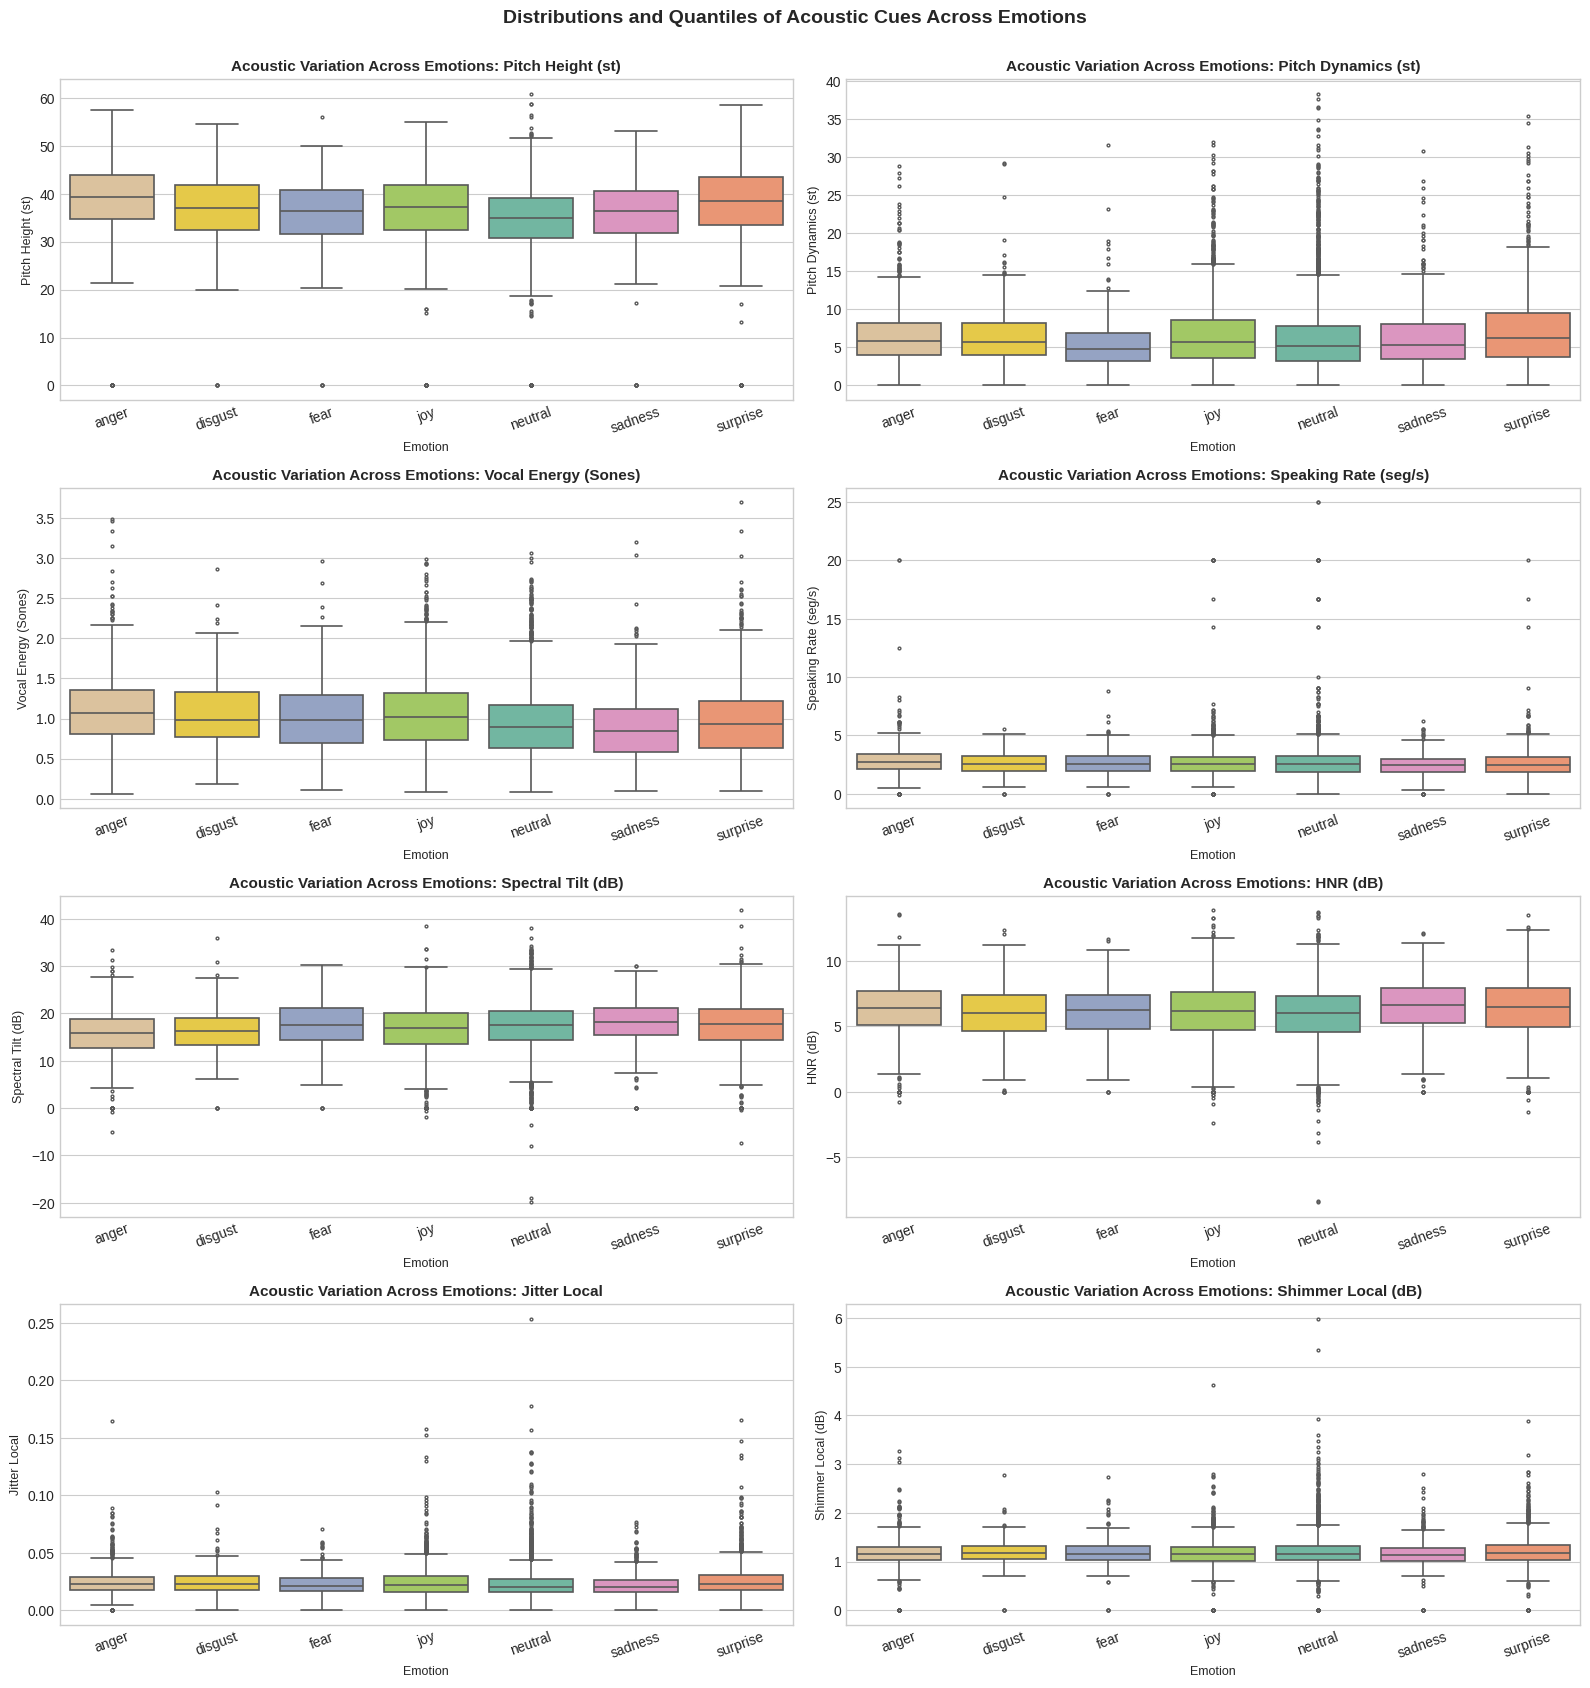

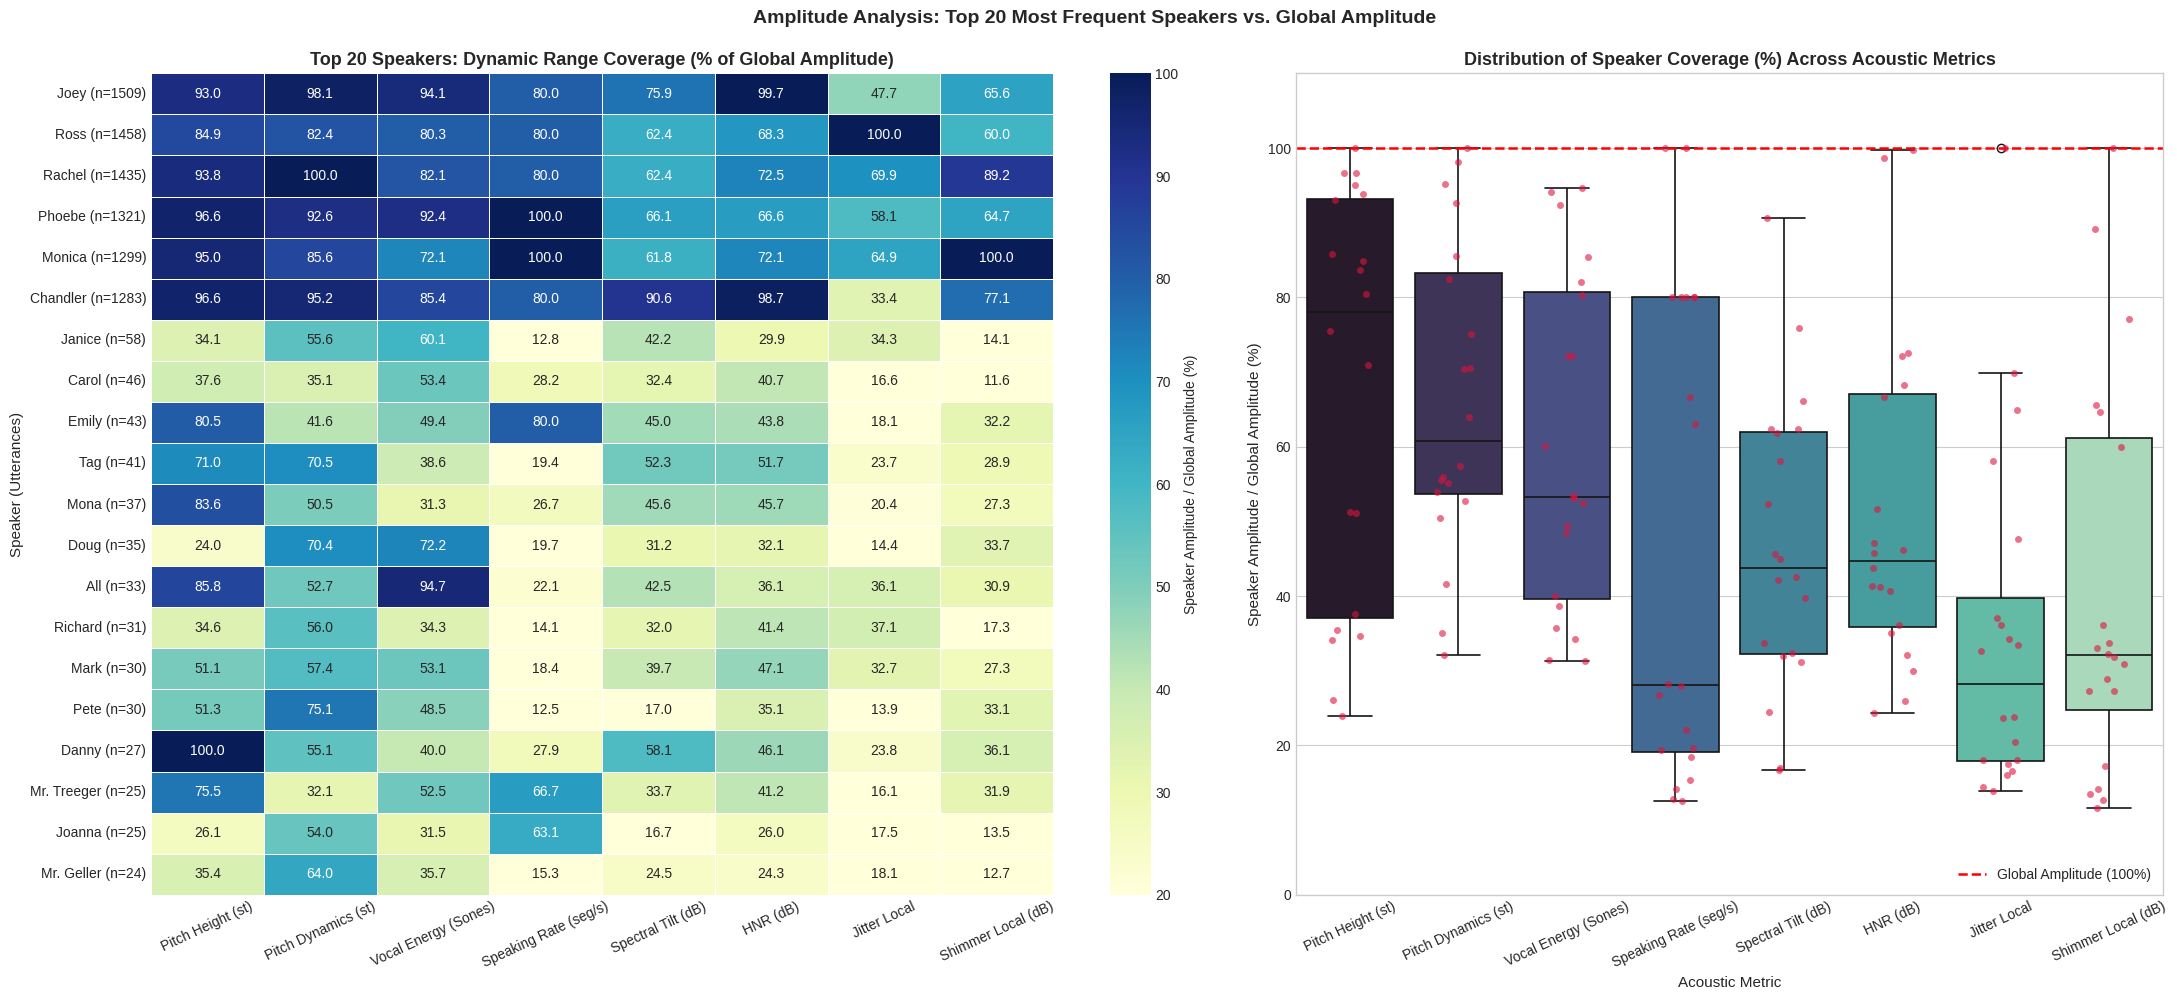

In [23]:
# ==============================================================================
# Diagnóstico de Variação por Emoção e Amplitudes dos Locutores (Raw Train Set)
# ==============================================================================
import matplotlib.pyplot as plt
import seaborn as sns

def analyze_emotion_and_speaker_acoustics(
    df: pd.DataFrame,
    top_n_speakers: int = 20,
    cues_dict: Dict[str, str] = ACOUSTIC_CUES,
):
    active_cues = {label: col for label, col in cues_dict.items() if col in df.columns}
    if not active_cues:
        print("⚠️ Nenhuma das colunas de cues acústicos foi encontrada no DataFrame.")
        return

    print("=" * 90)
    print("📊 DIAGNÓSTICO ACÚSTICO: VARIAÇÃO POR EMOÇÃO, QUANTIS E AMPLITUDES (LOCUTORES VS GLOBAL)")
    print("=" * 90)

    # A. AMPLITUDE E QUANTIS GLOBAIS (Full Corpus)
    global_rows = []
    global_amps = {}
    for label, col in active_cues.items():
        s = df[col].dropna()
        q10, q25, q33, q50, q66, q75, q90 = s.quantile([0.10, 0.25, 0.33, 0.50, 0.66, 0.75, 0.90])
        min_v, max_v = s.min(), s.max()
        amp = max_v - min_v
        global_amps[label] = amp
        global_rows.append({
            "Metric": label,
            "Count": len(s),
            "Mean": round(s.mean(), 2),
            "Std": round(s.std(), 2),
            "Min": round(min_v, 2),
            "Q10": round(q10, 2),
            "Q25": round(q25, 2),
            "Q33": round(q33, 2),
            "Median (Q50)": round(q50, 2),
            "Q66": round(q66, 2),
            "Q75": round(q75, 2),
            "Q90": round(q90, 2),
            "Max": round(max_v, 2),
            "Global Amplitude": round(amp, 2),
            "Global IQR": round(q75 - q25, 2),
        })

    df_global = pd.DataFrame(global_rows).set_index("Metric")

    # B. VARIAÇÃO DE EMOÇÃO E NÚMEROS DOS CUES ACÚSTICOS EM QUANTIS
    emo_rows = []
    for emo, emo_df in df.groupby("emotion"):
        for label, col in active_cues.items():
            s = emo_df[col].dropna()
            if len(s) == 0:
                continue
            q10, q25, q33, q50, q66, q75, q90 = s.quantile([0.10, 0.25, 0.33, 0.50, 0.66, 0.75, 0.90])
            min_v, max_v = s.min(), s.max()
            emo_rows.append({
                "Emotion": emo,
                "Metric": label,
                "Utterances": len(s),
                "Mean": round(s.mean(), 2),
                "Std": round(s.std(), 2),
                "Min": round(min_v, 2),
                "Q25": round(q25, 2),
                "Q33": round(q33, 2),
                "Median (Q50)": round(q50, 2),
                "Q66": round(q66, 2),
                "Q75": round(q75, 2),
                "Max": round(max_v, 2),
                "Amplitude": round(max_v - min_v, 2),
                "IQR": round(q75 - q25, 2),
            })

    df_emotion_quantiles = pd.DataFrame(emo_rows)

    # C. AMPLITUDE DOS 20 LOCUTORES COM MAIS FALAS (TOP 20 UTTERANCE SPEAKERS)
    spk_counts = df["speaker"].value_counts()
    top_speakers = spk_counts.head(top_n_speakers).index.tolist()

    spk_amp_rows = []
    spk_ratio_rows = []

    for spk in top_speakers:
        sub = df[df["speaker"] == spk]
        n_utt = len(sub)
        amp_entry = {"Speaker": spk, "Utterances": n_utt}
        ratio_entry = {"Speaker": f"{spk} (n={n_utt})"}

        for label, col in active_cues.items():
            s = sub[col].dropna()
            g_amp = global_amps.get(label, 0)
            if len(s) > 1:
                s_amp = s.max() - s.min()
                amp_entry[label] = round(s_amp, 2)
                ratio_entry[label] = round((s_amp / g_amp) * 100, 1) if g_amp > 0 else 0.0
            else:
                amp_entry[label] = 0.0
                ratio_entry[label] = 0.0

        spk_amp_rows.append(amp_entry)
        spk_ratio_rows.append(ratio_entry)

    df_top20_amplitudes = pd.DataFrame(spk_amp_rows).set_index("Speaker")
    df_top20_relative_amplitudes = pd.DataFrame(spk_ratio_rows).set_index("Speaker")

    # Adiciona estatísticas agregadas dos locutores à tabela global
    metric_cols = [c for c in df_top20_amplitudes.columns if c != "Utterances"]
    df_global["Mean Speaker Amp"] = [
        round(df_top20_amplitudes[m].mean(), 2) for m in df_global.index if m in metric_cols
    ]
    df_global["Speaker/Global Amp (%)"] = [
        round((df_top20_amplitudes[m].mean() / df_global.loc[m, "Global Amplitude"]) * 100, 1)
        for m in df_global.index if m in metric_cols
    ]

    # D. EXIBIÇÃO DE RESULTADOS
    print("\n1️⃣ QUANTIS E AMPLITUDE GLOBAL POR CUE ACÚSTICO (CORPUS COMPLETO):")
    display(df_global[["Min", "Q25", "Q33", "Median (Q50)", "Q66", "Q75", "Max", "Global Amplitude", "Global IQR", "Mean Speaker Amp", "Speaker/Global Amp (%)"]])

    print("\n2️⃣ VARIAÇÃO DE EMOÇÕES NOS QUANTIS E AMPLITUDES DOS CUES ACÚSTICOS:")
    display(df_emotion_quantiles.head(16))

    print(f"\n3️⃣ AMPLITUDES ABSOLUTAS (MAX - MIN) DOS {top_n_speakers} LOCUTORES COM MAIS FALAS:")
    display(df_top20_amplitudes)

    print(f"\n4️⃣ COBERTURA DA AMPLITUDE GLOBAL (%) PELOS {top_n_speakers} LOCUTORES COM MAIS FALAS:")
    display(df_top20_relative_amplitudes)

    # --------------------------------------------------------------------------
    # 4. PLOTS
    # --------------------------------------------------------------------------
    print("\n" + "=" * 90)
    print("📈 GERANDO VISUALIZAÇÕES DOS QUANTIS E AMPLITUDES...")
    print("=" * 90)

    # FIGURA 1: Variação das Emoções por Cue Acústico (Boxplots com Quantis)
    n_cues = len(active_cues)
    cols = 2
    rows = (n_cues + cols - 1) // cols

    plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
    fig1, axes1 = plt.subplots(rows, cols, figsize=(16, 4.2 * rows))
    axes1 = np.array(axes1).flatten()
    emo_order = sorted(df["emotion"].unique())

    for idx, (label, col) in enumerate(active_cues.items()):
        ax = axes1[idx]
        sns.boxplot(
            data=df,
            x="emotion",
            y=col,
            order=emo_order,
            hue="emotion",
            legend=False,
            palette="Set2",
            ax=ax,
            fliersize=2,
            linewidth=1.2,
        )
        ax.set_title(f"Acoustic Variation Across Emotions: {label}", fontsize=11, fontweight="bold")
        ax.set_xlabel("Emotion", fontsize=9)
        ax.set_ylabel(label, fontsize=9)
        ax.tick_params(axis="x", rotation=20)

    for idx in range(len(active_cues), len(axes1)):
        fig1.delaxes(axes1[idx])

    fig1.suptitle("Distributions and Quantiles of Acoustic Cues Across Emotions", fontsize=14, fontweight="bold", y=1.002)
    plt.tight_layout()
    plt.show()

    # FIGURA 2: Comparação de Amplitude dos Locutores vs Amplitude Global
    fig2, (ax_heat, ax_dist) = plt.subplots(1, 2, figsize=(22, 10), gridspec_kw={"width_ratios": [1.3, 1]})

    # Subplot A: Heatmap com percentual de amplitude global coberto
    sns.heatmap(
        df_top20_relative_amplitudes,
        annot=True,
        fmt=".1f",
        cmap="YlGnBu",
        cbar_kws={"label": "Speaker Amplitude / Global Amplitude (%)"},
        vmin=20,
        vmax=100,
        ax=ax_heat,
        linewidths=0.5,
    )
    ax_heat.set_title(f"Top {top_n_speakers} Speakers: Dynamic Range Coverage (% of Global Amplitude)", fontsize=13, fontweight="bold")
    ax_heat.set_ylabel("Speaker (Utterances)", fontsize=11)
    ax_heat.tick_params(axis="x", rotation=25)

    # Subplot B: Distribuição da cobertura relativa por métrica acústica
    df_melted_ratio = df_top20_relative_amplitudes.melt(var_name="Metric", value_name="Relative Amplitude (%)")
    sns.boxplot(
        data=df_melted_ratio,
        x="Metric",
        y="Relative Amplitude (%)",
        hue="Metric",
        legend=False,
        palette="mako",
        ax=ax_dist,
        linewidth=1.2,
    )
    sns.stripplot(
        data=df_melted_ratio,
        x="Metric",
        y="Relative Amplitude (%)",
        color="crimson",
        alpha=0.6,
        jitter=0.2,
        size=5,
        ax=ax_dist,
    )
    ax_dist.axhline(100.0, color="red", linestyle="--", linewidth=1.8, label="Global Amplitude (100%)")
    ax_dist.set_ylim(0, 110)
    ax_dist.set_title("Distribution of Speaker Coverage (%) Across Acoustic Metrics", fontsize=13, fontweight="bold")
    ax_dist.set_xlabel("Acoustic Metric", fontsize=11)
    ax_dist.set_ylabel("Speaker Amplitude / Global Amplitude (%)", fontsize=11)
    ax_dist.tick_params(axis="x", rotation=25)
    ax_dist.legend(loc="lower right", fontsize=10)

    fig2.suptitle(f"Amplitude Analysis: Top {top_n_speakers} Most Frequent Speakers vs. Global Amplitude", fontsize=14, fontweight="bold", y=0.995)
    plt.tight_layout()
    plt.show()

    return {
        "global_summary": df_global,
        "emotion_quantiles": df_emotion_quantiles,
        "speaker_amplitudes": df_top20_amplitudes,
        "speaker_relative_amplitudes": df_top20_relative_amplitudes,
    }

# Executa o diagnóstico completo sobre raw_train_set
acoustic_analysis_results = analyze_emotion_and_speaker_acoustics(raw_train_set, top_n_speakers=20)

## Balanced

In [24]:
import pandas as pd
from pathlib import Path
import librosa


def get_audio_duration(audio_path: str) -> float | None:
    """Return audio duration in seconds, or None if the file cannot be read."""
    try:
        return librosa.get_duration(path=audio_path)
    except Exception:
        return None


def sample_balanced_meld(
    df: pd.DataFrame,
    target_total: int = 2000,
    max_neutral_pct: float = 0.15,
    min_duration: float = 0.5,
    max_duration: float = 30.0,
    seed: int = 42,
) -> pd.DataFrame:
    """
    Create a deterministic, emotion-balanced MELD subset.

    Filtering:
        - Removes missing/invalid audio files.
        - Removes audio shorter than min_duration.
        - Removes audio longer than max_duration.

    Balancing:
        - Caps neutral at max_neutral_pct.
        - Distributes remaining samples across non-neutral emotions.
        - Redistributes unused quotas from underrepresented classes.

    Args:
        df: MELD dataframe containing 'audio_path' and 'emotion'.
        target_total: Desired number of samples.
        max_neutral_pct: Maximum proportion of neutral samples.
        min_duration: Minimum audio duration in seconds.
        max_duration: Maximum audio duration in seconds.
        seed: Random seed for deterministic sampling.

    Returns:
        Balanced and filtered DataFrame.
    """

    df = df.copy()

    # ----------------------------------------------------------
    # 1. Deterministic ordering
    # ----------------------------------------------------------

    id_cols = [
        c for c in ["dialogue", "utterance"]
        if c in df.columns
    ]

    if id_cols:
        df = df.sort_values(id_cols)
    elif "audio_path" in df.columns:
        df = df.sort_values("audio_path")

    df = df.reset_index(drop=True)

    # ----------------------------------------------------------
    # 2. Validate audio paths
    # ----------------------------------------------------------

    if "audio_path" not in df.columns:
        raise ValueError("DataFrame must contain 'audio_path'.")

    df = df[
        df["audio_path"].notna()
        & df["audio_path"].apply(
            lambda p: Path(str(p)).is_file()
        )
    ].copy()

    print(f"After audio validation: {len(df):,}")

    # ----------------------------------------------------------
    # 3. Audio duration filtering
    # ----------------------------------------------------------

    print("Computing audio durations...")

    df["duration"] = df["audio_path"].apply(get_audio_duration)

    failed_duration = df["duration"].isna().sum()

    if failed_duration:
        print(
            f"Warning: could not determine duration for "
            f"{failed_duration:,} files."
        )

    df = df[df["duration"].notna()].copy()

    df = df[
        df["duration"].between(
            min_duration,
            max_duration,
            inclusive="both",
        )
    ].copy()

    print(
        f"Duration filter: "
        f"{min_duration:.1f}s–{max_duration:.1f}s"
    )
    print(f"After duration filtering: {len(df):,}")

    # ----------------------------------------------------------
    # 4. Normalize emotion labels
    # ----------------------------------------------------------

    df["emotion"] = (
        df["emotion"]
        .astype(str)
        .str.strip()
        .str.lower()
    )

    df = df[df["emotion"].ne("nan")].copy()

    emotions = sorted(df["emotion"].unique())

    if not emotions:
        raise ValueError("No valid emotion classes remain.")

    print("\nAvailable emotions:")
    print(emotions)

    # ----------------------------------------------------------
    # 5. Cap neutral
    # ----------------------------------------------------------

    max_neutral_count = int(
        target_total * max_neutral_pct
    )

    non_neutral = [
        emotion
        for emotion in emotions
        if emotion != "neutral"
    ]

    # If neutral is not present, all samples go to
    # non-neutral classes.
    neutral_target = (
        min(
            max_neutral_count,
            len(df[df["emotion"] == "neutral"])
        )
        if "neutral" in emotions
        else 0
    )

    remaining_slots = target_total - neutral_target

    # ----------------------------------------------------------
    # 6. Initial non-neutral quotas
    # ----------------------------------------------------------

    quotas = {}

    if non_neutral:
        base = remaining_slots // len(non_neutral)
        remainder = remaining_slots % len(non_neutral)

        for i, emotion in enumerate(non_neutral):
            quotas[emotion] = (
                base + (1 if i < remainder else 0)
            )

    if "neutral" in emotions:
        quotas["neutral"] = neutral_target

    # ----------------------------------------------------------
    # 7. Redistribute unavailable samples
    # ----------------------------------------------------------

    while True:
        deficit = 0
        saturated = set()

        for emotion, quota in quotas.items():
            available = (
                df["emotion"].eq(emotion).sum()
            )

            if available < quota:
                deficit += quota - available
                quotas[emotion] = available
                saturated.add(emotion)

        if deficit == 0:
            break

        eligible = [
            emotion
            for emotion in non_neutral
            if emotion not in saturated
            and quotas[emotion]
            < df["emotion"].eq(emotion).sum()
        ]

        if not eligible:
            break

        base_extra = deficit // len(eligible)
        remainder = deficit % len(eligible)

        for i, emotion in enumerate(eligible):
            quotas[emotion] += (
                base_extra
                + (1 if i < remainder else 0)
            )

    # ----------------------------------------------------------
    # 8. Deterministic sampling
    # ----------------------------------------------------------

    sampled = []

    for emotion in sorted(quotas):
        n = quotas[emotion]

        if n == 0:
            continue

        class_df = df[df["emotion"] == emotion]

        sampled.append(
            class_df.sample(
                n=n,
                random_state=seed,
                replace=False,
            )
        )

    if not sampled:
        raise ValueError(
            "No samples available after filtering."
        )

    result = pd.concat(
        sampled,
        ignore_index=True,
    )

    # ----------------------------------------------------------
    # 9. Final deterministic ordering
    # ----------------------------------------------------------

    if id_cols:
        result = result.sort_values(id_cols)

    result = result.reset_index(drop=True)

    # ----------------------------------------------------------
    # 10. Diagnostics
    # ----------------------------------------------------------

    print("\n" + "=" * 50)
    print("MELD SAMPLING SUMMARY")
    print("=" * 50)

    print(f"Requested samples: {target_total:,}")
    print(f"Returned samples:  {len(result):,}")

    print("\nEmotion distribution:")
    print(result["emotion"].value_counts())

    print("\nEmotion proportions:")
    print(
        result["emotion"]
        .value_counts(normalize=True)
        .mul(100)
        .round(2)
        .astype(str)
        .add("%")
    )

    print("\nAudio duration:")
    print(
        result["duration"].describe()[
            ["min", "mean", "max"]
        ].round(2)
    )

    print("\nQuotas:")
    print(quotas)

    return result

In [25]:
pruned_train_set = sample_balanced_meld(
    raw_train_set,
    target_total=2000,
    max_neutral_pct=0.15,
    min_duration=0.5,
    max_duration=30.0,
    seed=42,
)

run_test = sample_balanced_meld(
    raw_train_set,
    target_total=2000,
    max_neutral_pct=0.15,
    min_duration=0.5,
    max_duration=30.0,
    seed=42,
)

assert pruned_train_set.equals(run_test)

print("\nFinal candidate pool:")
display(pruned_train_set.head())

After audio validation: 9,988
Computing audio durations...
Duration filter: 0.5s–30.0s
After duration filtering: 9,681

Available emotions:
['anger', 'disgust', 'fear', 'joy', 'neutral', 'sadness', 'surprise']

MELD SAMPLING SUMMARY
Requested samples: 2,000
Returned samples:  2,000

Emotion distribution:
emotion
neutral     300
anger       293
joy         292
sadness     291
surprise    291
disgust     268
fear        265
Name: count, dtype: int64

Emotion proportions:
emotion
neutral      15.0%
anger       14.65%
joy          14.6%
sadness     14.55%
surprise    14.55%
disgust      13.4%
fear        13.25%
Name: proportion, dtype: object

Audio duration:
min      0.51
mean     3.33
max     22.95
Name: duration, dtype: float64

Quotas:
{'anger': np.int64(293), 'disgust': np.int64(268), 'fear': np.int64(265), 'joy': np.int64(292), 'sadness': np.int64(291), 'surprise': np.int64(291), 'neutral': 300}
After audio validation: 9,988
Computing audio durations...
Duration filter: 0.5s–30.0s
Af

,audio_path,time,utterance,dialogue,emotion,text,speaker,F0semitoneFrom27.5Hz_sma3nz_amean,F0semitoneFrom27.5Hz_sma3nz_pctlrange0-2,loudness_sma3_percentile50.0,VoicedSegmentsPerSec,hammarbergIndexV_sma3nz_amean,HNRdBACF_sma3nz_amean,jitterLocal_sma3nz_amean,shimmerLocaldB_sma3nz_amean,duration
0,/content/MELD/preprocessed_train_splits/dia0_u...,2.219,9,0,neutral,We can go into detail,The Interviewer,28.810305,2.902483,0.755903,2.803739,19.237234,6.250984,0.015701,1.070284,2.218688
1,/content/MELD/preprocessed_train_splits/dia0_u...,2.005,10,0,fear,No dont I beg of you!,Chandler,33.925426,8.947289,1.143961,2.061856,13.352987,3.297102,0.023200,1.292880,2.005375
2,/content/MELD/preprocessed_train_splits/dia1_u...,2.475,0,1,surprise,But then who? The waitress I went out with las...,Joey,28.792513,1.474661,1.225475,2.489627,18.477812,4.619659,0.012924,1.324144,2.474687
3,/content/MELD/preprocessed_train_splits/dia1_u...,2.219,1,1,sadness,You know? Forget it!,Rachel,37.167171,6.227909,0.617221,1.860465,20.580799,5.719617,0.051611,1.371788,2.218688
4,/content/MELD/preprocessed_train_splits/dia1_u...,4.757,2,1,surprise,"No-no-no-no, no! Who, who were you talking about?",Joey,36.927811,9.820950,1.009611,3.411514,18.723021,4.865646,0.037674,1.331839,4.757375


In [26]:
from sklearn.model_selection import train_test_split

In [27]:
train_set, val_set = train_test_split(
    pruned_train_set,
    test_size=0.2,
    random_state=42,
    stratify=pruned_train_set["emotion"],
)

In [28]:
train_set['emotion'].value_counts()

,count
emotion,
neutral,240
joy,234
anger,234
sadness,233
surprise,233
disgust,214
fear,212


In [29]:
train_set['speaker'].value_counts()

,count
speaker,
Rachel,246
Joey,244
Phoebe,222
Chandler,215
Monica,214
...,...
Rachel and Phoebe,1
Another Scientist,1
Janine,1


In [30]:
display(train_set)

,audio_path,time,utterance,dialogue,emotion,text,speaker,F0semitoneFrom27.5Hz_sma3nz_amean,F0semitoneFrom27.5Hz_sma3nz_pctlrange0-2,loudness_sma3_percentile50.0,VoicedSegmentsPerSec,hammarbergIndexV_sma3nz_amean,HNRdBACF_sma3nz_amean,jitterLocal_sma3nz_amean,shimmerLocaldB_sma3nz_amean,duration
1760,/content/MELD/preprocessed_train_splits/dia921...,0.704,5,921,sadness,No-no its not!,Eric,31.504700,1.594723,0.971907,3.125000,28.355448,8.076351,0.011920,1.028892,0.704000
1341,/content/MELD/preprocessed_train_splits/dia698...,1.835,3,698,disgust,Noo.,Rachel,43.353996,2.817863,0.210902,1.129943,23.570908,12.043491,0.012698,0.748850,1.834688
469,/content/MELD/preprocessed_train_splits/dia237...,4.011,9,237,sadness,"I'm sorry, my friend Phoebe...",Monica,36.626148,8.339176,0.487151,2.531646,13.571520,5.918450,0.074552,1.235459,4.010688
1264,/content/MELD/preprocessed_train_splits/dia655...,5.227,9,655,surprise,Really?,Ross,31.756283,2.790981,0.504608,1.550388,25.658468,6.632182,0.018136,1.112266,5.226687
1731,/content/MELD/preprocessed_train_splits/dia907...,3.925,9,907,disgust,Save it Red! Unless you wanna spend the night ...,Phoebe,41.575012,3.678955,1.220119,2.590674,14.828059,6.169218,0.019418,1.146574,3.925375
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
576,/content/MELD/preprocessed_train_splits/dia283...,3.520,6,283,disgust,"Okay, whatever.",Phoebe,31.701672,11.846041,0.939283,2.890173,17.290997,4.739032,0.031922,1.250546,3.520000
1328,/content/MELD/preprocessed_train_splits/dia688...,2.603,0,688,neutral,"Youve seen my huge stack of porn, right?",Joey,33.543880,6.975632,1.214611,3.149606,15.151702,5.205800,0.015217,1.105613,2.602688
1979,/content/MELD/preprocessed_train_splits/dia103...,2.091,1,1030,sadness,Is this about me taking your watch?,Chloe,38.013603,1.759830,0.917641,3.448276,23.780550,9.723830,0.011484,0.872821,2.090688
870,/content/MELD/preprocessed_train_splits/dia445...,3.349,3,445,fear,"All right here he comes. Im gonna do this, I...",Rachel,32.740173,3.986284,0.785044,3.658537,19.804991,5.518298,0.024809,1.166903,3.349375


### 2.2 Balanceamento do Subconjunto dos 6 Locutores Principais (GRPO)

Para garantir o alinhamento rigoroso entre as recompensas de inventário acústico (R2) e as trajetórias de treinamento GRPO:
1. **Exclusividade dos 6 Personagens Principais**: O conjunto de treino é restrito aos 6 locutores com maior volume de falas (`Joey`, `Ross`, `Rachel`, `Phoebe`, `Monica`, `Chandler`).
2. **Prevenção Estrita de Data Leakage**: Nenhum arquivo de áudio presente no conjunto de validação (`val_set` com 400 amostras) é incluído no treino (sobreposição = 0%).
3. **Recorte Temporal Dialógico**: Áudios com duração estritamente entre **1.0 segundo e 20.0 segundos** (respeitando a distribuição natural de diálogos no MELD).
4. **Recorte de Integridade eGeMAPS**: Descarte estrito de áudios com medições acústicas zeradas (`0.0`) ou nulas (especialmente F0, segmentos vozeados, loudness, jitter e shimmer), impedindo ruído de extração.
5. **Estratificação de Emoções e Falantes**: Teto máximo de 15% para a classe `neutral`, distribuição equilibrada entre as classes emocionais e divisão proporcional entre os 6 locutores.


In [31]:
# ==============================================================================
# Balanceamento Específico para os 6 Locutores Principais (GRPO Train Set)
# ==============================================================================
from typing import Dict, List, Optional
import pandas as pd
import numpy as np

TOP_6_SPEAKERS = ["Joey", "Ross", "Rachel", "Phoebe", "Monica", "Chandler"]

STRICTLY_POSITIVE_ACOUSTIC_FEATURES = [
    "F0semitoneFrom27.5Hz_sma3nz_amean",
    "F0semitoneFrom27.5Hz_sma3nz_pctlrange0-2",
    "loudness_sma3_percentile50.0",
    "VoicedSegmentsPerSec",
    "jitterLocal_sma3nz_amean",
    "shimmerLocaldB_sma3nz_amean",
]

ALL_ACOUSTIC_COLS = STRICTLY_POSITIVE_ACOUSTIC_FEATURES + [
    "HNRdBACF_sma3nz_amean",
    "hammarbergIndexV_sma3nz_amean",
]


def sample_balanced_top_speakers(
    train_df: pd.DataFrame,
    val_df: Optional[pd.DataFrame] = None,
    top_speakers: Optional[List[str]] = None,
    min_duration: float = 1.0,
    max_duration: float = 20.0,
    max_neutral_pct: float = 0.15,
    target_total: Optional[int] = None,
    seed: int = 42,
) -> pd.DataFrame:
    """Extrai um subconjunto balanceado exclusivamente dos 6 locutores principais.

    Garante exclusão estrita dos 400 áudios de validação, limites de duração (1.0s-20.0s)
    e filtro rigoroso contra métricas acústicas eGeMAPS zeradas ou nulas.
    """
    df = train_df.copy()

    # 1. Exclusão estrita dos áudios do conjunto de validação
    if val_df is not None and "audio_path" in val_df.columns and "audio_path" in df.columns:
        val_paths = set(val_df["audio_path"].dropna().astype(str))
        init_len = len(df)
        df = df[~df["audio_path"].astype(str).isin(val_paths)].copy()
        print(f"🔒 Exclusão de validação: {init_len - len(df)} áudios coincidentes removidos.")

    # 2. Filtragem exclusiva para os 6 locutores calibrados
    target_speakers = top_speakers or TOP_6_SPEAKERS
    if "speaker" in df.columns:
        df = df[df["speaker"].isin(target_speakers)].copy()
        print(f"👥 Filtrado para os {len(target_speakers)} locutores principais: {len(df)} amostras disponíveis.")

    # 3. Recorte temporal (1.0s a 20.0s)
    dur_col = "duration" if "duration" in df.columns else ("time" if "time" in df.columns else None)
    if dur_col is not None:
        df = df[df[dur_col].notna()].copy()
        df = df[df[dur_col].between(min_duration, max_duration, inclusive="both")].copy()
        print(f"⏱️ Recorte temporal [{min_duration}s, {max_duration}s]: {len(df)} amostras.")

    # 4. Recorte eGeMAPS: métricas de áudio não podem estar zeradas nem nulas
    for col in ALL_ACOUSTIC_COLS:
        if col in df.columns:
            df = df[df[col].notna() & (df[col] != 0.0)].copy()
            if col in STRICTLY_POSITIVE_ACOUSTIC_FEATURES:
                df = df[df[col] > 0.0].copy()
    print(f"🎙️ Recorte eGeMAPS (métricas estritamente não zeradas): {len(df)} amostras válidas.")

    # 5. Normalização de emoções e cálculo de cotas
    if "emotion" in df.columns:
        df["emotion"] = df["emotion"].astype(str).str.strip().str.lower()
    emotions = sorted(df["emotion"].unique())
    non_neutral = [e for e in emotions if e != "neutral"]

    if target_total is None or target_total > len(df):
        counts = df["emotion"].value_counts()
        min_non_neutral = min([counts.get(e, 0) for e in non_neutral]) if non_neutral else 0
        slots_non_neutral = min_non_neutral * len(non_neutral)
        neutral_avail = counts.get("neutral", 0)
        neutral_target = min(neutral_avail, int(slots_non_neutral * max_neutral_pct / (1.0 - max_neutral_pct)))
        target_total = slots_non_neutral + neutral_target

    max_neutral = int(target_total * max_neutral_pct)
    neutral_count = min(max_neutral, df["emotion"].eq("neutral").sum()) if "neutral" in emotions else 0
    remaining_slots = target_total - neutral_count

    quotas: Dict[str, int] = {}
    if non_neutral:
        base = remaining_slots // len(non_neutral)
        rem = remaining_slots % len(non_neutral)
        for i, emo in enumerate(non_neutral):
            quotas[emo] = base + (1 if i < rem else 0)
    if "neutral" in emotions:
        quotas["neutral"] = neutral_count

    # Redistribuição iterativa de cotas
    while True:
        deficit = 0
        saturated = set()
        for emo, quota in quotas.items():
            avail = df["emotion"].eq(emo).sum()
            if avail < quota:
                deficit += (quota - avail)
                quotas[emo] = avail
                saturated.add(emo)
        if deficit == 0:
            break
        eligible = [e for e in non_neutral if e not in saturated and quotas[e] < df["emotion"].eq(e).sum()]
        if not eligible:
            break
        base_extra = deficit // len(eligible)
        rem_extra = deficit % len(eligible)
        for i, emo in enumerate(eligible):
            quotas[emo] += base_extra + (1 if i < rem_extra else 0)

    # 6. Amostragem determinística estratificada por emoção e locutor
    sampled_dfs = []
    for emo, q in quotas.items():
        if q == 0:
            continue
        sub_emo = df[df["emotion"] == emo]
        spk_groups = []
        spk_quota = q // len(target_speakers)
        spk_rem = q % len(target_speakers)

        for s_idx, spk in enumerate(sorted(target_speakers)):
            spk_df = sub_emo[sub_emo["speaker"] == spk]
            needed = spk_quota + (1 if s_idx < spk_rem else 0)
            take = min(needed, len(spk_df))
            if take > 0:
                spk_groups.append(spk_df.sample(n=take, random_state=seed, replace=False))

        sampled_emo = pd.concat(spk_groups) if spk_groups else pd.DataFrame()
        if len(sampled_emo) < q:
            missing = q - len(sampled_emo)
            already_idx = set(sampled_emo.index)
            remaining_pool = sub_emo[~sub_emo.index.isin(already_idx)]
            if len(remaining_pool) > 0:
                fill = remaining_pool.sample(n=min(missing, len(remaining_pool)), random_state=seed, replace=False)
                sampled_emo = pd.concat([sampled_emo, fill])

        sampled_dfs.append(sampled_emo)

    result = pd.concat(sampled_dfs, ignore_index=True)
    id_cols = [c for c in ["dialogue", "utterance"] if c in result.columns]
    if id_cols:
        result = result.sort_values(id_cols)
    elif "audio_path" in result.columns:
        result = result.sort_values("audio_path")
    result = result.reset_index(drop=True)

    return result


# Executa a amostragem balanceada apenas nos 6 locutores principais
grpo_train_set = sample_balanced_top_speakers(
    train_df=train_set,
    val_df=val_set,
    top_speakers=TOP_6_SPEAKERS,
    min_duration=1.0,
    max_duration=20.0,
    max_neutral_pct=0.15,
    seed=42,
)

# Atualiza train_set para que todas as etapas seguintes utilizem o dataset balanceado dos 6 locutores
train_set = grpo_train_set

print(f"\n🎯 Conjunto balanceado final para GRPO: {len(train_set)} amostras.")
print(f"Locutores presentes: {sorted(train_set['speaker'].unique())}")
if "audio_path" in val_set.columns and "audio_path" in train_set.columns:
    overlap = set(train_set["audio_path"]).intersection(set(val_set["audio_path"]))
    assert len(overlap) == 0, f"Erro: {len(overlap)} áudios do conjunto de validação vazaram para o treino!"
    print("🔒 Integridade verificada: 0 vazamento de áudios entre treino e validação.")

print("\nDistribuição por Emoção:")
display(train_set["emotion"].value_counts())
print("\nDistribuição por Locutor:")
display(train_set["speaker"].value_counts())


🔒 Exclusão de validação: 0 áudios coincidentes removidos.
👥 Filtrado para os 6 locutores principais: 1346 amostras disponíveis.
⏱️ Recorte temporal [1.0s, 20.0s]: 1256 amostras.
🎙️ Recorte eGeMAPS (métricas estritamente não zeradas): 1250 amostras válidas.

🎯 Conjunto balanceado final para GRPO: 1129 amostras.
Locutores presentes: ['Chandler', 'Joey', 'Monica', 'Phoebe', 'Rachel', 'Ross']
🔒 Integridade verificada: 0 vazamento de áudios entre treino e validação.

Distribuição por Emoção:


,count
emotion,
neutral,169
surprise,160
fear,160
disgust,160
sadness,160
anger,160
joy,160



Distribuição por Locutor:


,count
speaker,
Joey,201
Rachel,192
Chandler,188
Monica,184
Ross,183
Phoebe,181


# Model Config
Qwen 2.5 Omni - 4bit Quantization

In [32]:
import torch
from typing import Dict, Any, Tuple
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training

## Prompt

In [33]:
qwen_persona = (
    "You are an expert in speech emotion recognition and acoustic phonetics. "
    "You evaluate vocal affect strictly through physical acoustic properties."
)

cot_prompt = """Listen to the audio clip and predict the speaker's emotional state solely from acoustics.

Allowed emotions: anger, joy, sadness, surprise, fear, disgust, neutral

Instructions:
1. Complete [Acoustic Inventory] selecting one option per line.
2. In [Prosodic Reasoning], deduce which emotion best matches these physical cues and eliminate conflicting states.
3. Output only the predicted class inside <answer>.

Output strictly in this format:
<think>
[Acoustic Inventory]
- Pitch Height: low | moderate | elevated
- Pitch Dynamics: narrow | moderate | wide
- Vocal Energy: quiet | moderate | loud
- Speaking Rate: slow | moderate | fast
- Voice Quality: pressed/tense | breathy | harsh/creaky | modal/normal

[Prosodic Reasoning]
(Deduce the emotion from the cues above)
</think>
<answer>emotion</answer>"""

## Quantization config

In [34]:
!pip install -q bitsandbytes

In [35]:
from transformers import (
    AutoProcessor,
    Qwen2_5OmniForConditionalGeneration,
    BitsAndBytesConfig
)

In [36]:
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.bfloat16,
    bnb_4bit_use_double_quant=True,
)

## LoRA Config

In [37]:
peft_config = LoraConfig(
    r=16,
    lora_alpha=32,
    lora_dropout=0.00,
    bias="none",
    task_type=None,
    target_modules=r".*layers\.\d+\.(self_attn\.(q_proj|k_proj|v_proj|o_proj)|mlp\.(gate_proj|up_proj|down_proj))"
)

## General Config

In [38]:
model_id = "Qwen/Qwen2.5-Omni-7B"

# Reward Functions

## Utils

In [67]:
VALID_EMOTIONS =  {"anger", "joy", "sadness", "surprise", "fear", "disgust", "neutral"}

In [68]:
LABEL_SYNONYMS = {
    "happy": "joy",
    "happiness": "joy",
    "sad": "sadness",
    "mad": "anger",
    "angry": "anger",
    "scared": "fear",
    "fearful": "fear",
    "disgusted": "disgust",
    "surprised": "surprise",
}

SET_VALID_EMOTIONS = set(VALID_EMOTIONS)

In [69]:
REQUIRED_INVENTORY_KEYS = [
    "pitch_height",
    "pitch_dynamics",
    "vocal_energy",
    "speaking_rate",
    "voice_quality",
]

In [70]:
import json
from pathlib import Path
import re
from typing import Any, Dict, List, Optional
from collections import Counter

In [71]:
def extract_acoustic_inventory(completion: str) -> Dict[str, Optional[str]]:
    section_match = re.search(
        r"\[Acoustic Inventory\](.*?)(?:\[Prosodic Reasoning\]|</think>|$)",
        completion,
        re.DOTALL | re.IGNORECASE,
    )
    target_text = section_match.group(1) if section_match else completion

    patterns = {
        "pitch_height": (
            r"Pitch Height\s*:\s*(low|moderate|elevated)\b",
            {"low": "low", "moderate": "moderate", "elevated": "elevated"},
        ),
        "pitch_dynamics": (
            r"Pitch Dynamics\s*:\s*(narrow|moderate|wide)\b",
            {"narrow": "narrow", "moderate": "moderate", "wide": "wide"},
        ),
        "vocal_energy": (
            r"Vocal Energy\s*:\s*(quiet|moderate|loud)\b",
            {"quiet": "quiet", "moderate": "moderate", "loud": "loud"},
        ),
        "speaking_rate": (
            r"Speaking Rate\s*:\s*(slow|moderate|fast)\b",
            {"slow": "slow", "moderate": "moderate", "fast": "fast"},
        ),
        "voice_quality": (
            r"Voice Quality\s*:\s*(pressed/tense|pressed|tense|breathy|harsh/creaky|harsh|creaky|modal/normal|modal|normal)\b",
            {
                "pressed/tense": "pressed/tense",
                "pressed": "pressed/tense",
                "tense": "pressed/tense",
                "breathy": "breathy",
                "harsh/creaky": "harsh/creaky",
                "harsh": "harsh/creaky",
                "creaky": "harsh/creaky",
                "modal/normal": "modal/normal",
                "modal": "modal/normal",
                "normal": "modal/normal",
            },
        ),
    }

    parsed: Dict[str, Optional[str]] = {}

    for key, (pattern, canonical_map) in patterns.items():
        match = re.search(pattern, target_text, re.IGNORECASE)
        if match:
            raw_val = match.group(1).lower().strip()
            parsed[key] = canonical_map.get(raw_val, raw_val)
        else:
            parsed[key] = None

    return parsed

In [72]:
def extract_reasoning(completion: str) -> str:
    match = re.search(
        r"\[Prosodic Reasoning\](.*?)(?:</think>|<answer>|$)",
        completion,
        re.DOTALL | re.IGNORECASE,
    )
    if not match:
        return ""

    reasoning = match.group(1).strip()

    placeholder = "(Deduce the emotion from the cues above)"
    if reasoning.startswith(placeholder):
        reasoning = reasoning[len(placeholder) :].strip()

    return reasoning

In [73]:
def extract_answer_content(completion: str) -> str:
    match = re.search(
        r"<answer>(.*?)(?:</answer>|$)", completion, re.DOTALL | re.IGNORECASE
    )
    if not match:
        return ""

    raw_text = match.group(1).strip().lower()

    cleaned = re.sub(r"[\[\]\"\'\*\.]", "", raw_text).strip()

    if cleaned in VALID_EMOTIONS:
        return cleaned

    for emotion in VALID_EMOTIONS:
        if re.search(rf"\b{re.escape(emotion)}\b", cleaned):
            return emotion

    return cleaned


import functools

@functools.lru_cache(maxsize=8192)
def parse_completion(completion: str) -> Dict[str, Any]:
    """Parse estruturado completo da completion em UMA ÚNICA PASSAGEM com cache LRU.

    Centraliza a extração de tags XML, inventário acústico, raciocínio prosódico e resposta,
    evitando que múltiplas funções de recompensa repitam regex sobre a mesma string.
    """
    if not isinstance(completion, str):
        completion = str(completion) if completion is not None else ""

    t_open = completion.find("<think>")
    t_close = completion.find("</think>")
    a_open = completion.find("<answer>")
    a_close = completion.find("</answer>")

    has_think = (t_open != -1 and t_close != -1)
    has_answer = (a_open != -1 and a_close != -1)
    valid_tag_order = (has_think and has_answer and t_open < t_close < a_open < a_close)

    inventory = extract_acoustic_inventory(completion)
    valid_slots_count = sum(1 for v in inventory.values() if v is not None)

    reasoning = extract_reasoning(completion)

    answer_raw = extract_answer_content(completion)
    answer_norm = LABEL_SYNONYMS.get(answer_raw, answer_raw) if "LABEL_SYNONYMS" in globals() else answer_raw
    is_valid_emotion = answer_norm in VALID_EMOTIONS

    return {
        "raw": completion,
        "has_think": has_think,
        "has_answer": has_answer,
        "valid_tag_order": valid_tag_order,
        "inventory": inventory,
        "valid_slots_count": valid_slots_count,
        "reasoning": reasoning,
        "answer_raw": answer_raw,
        "answer_norm": answer_norm,
        "is_valid_emotion": is_valid_emotion,
    }


In [74]:
def compute_emotion_weights(
    train_set: Any, power: float = 0.4
) -> Dict[str, float]:
    """Computes smoothed inverse class-frequency weights for GRPO rewards.

    Uses w_c = (max_count / count) ** power so the majority class (neutral)
    is anchored at 1.0, and minority classes receive an advantage boost
    without blowing up gradient variance.

    Args:
        train_set: Pandas DataFrame, HuggingFace Dataset, or list containing an
          'emotion' column/key.
        power: Smoothing exponent. 0.0 = uniform (all 1.0), 0.4-0.5 = smoothed
          inverse (recommended for RLVR), 1.0 = raw inverse frequency.
    """
    emotions = list(train_set["emotion"])
    counts = Counter(emotions)
    max_count = max(counts.values())

    weights = {
        emotion: round((max_count / count) ** power, 3)
        for emotion, count in counts.items()
    }
    return weights

#CLASS_WEIGHTS = compute_emotion_weights(train_set)

In [75]:
display(CLASS_WEIGHTS)

{'anger': 1.0193,
 'joy': 1.0193,
 'sadness': 1.0193,
 'fear': 1.0193,
 'disgust': 1.0193,
 'surprise': 1.0193,
 'neutral': 1.0}

## R1 - Accuracy

In [76]:
# ==============================================================================
# R1 - Accuracy (Zero-Mean Esperança & Bonificação de Classes Difíceis)
# ==============================================================================
from typing import Any, Dict, List, Tuple
from collections import Counter
import pandas as pd

def compute_emotion_priors_and_weights(
    train_set: Any, power: float = 0.35
) -> Tuple[Dict[str, float], Dict[str, float]]:
    """Calcula os priors empíricos f_e e os pesos de raridade w_e para R1.

    Matemática Zero-Mean:
      - Acerto (pred == target): +w_e = (max_count / count_e) ** power
      - Erro (pred != target):   -f_pred * w_pred / (1 - f_pred)
      - Esperança de Chute Cego: f_e * (+w_e) + (1 - f_e) * (-f_e * w_e / (1 - f_e)) = 0.0!
    """
    raw_emotions = [
        LABEL_SYNONYMS.get(str(e).lower().strip(), str(e).lower().strip())
        for e in train_set["emotion"]
    ]
    counts = Counter(e for e in raw_emotions if e in VALID_EMOTIONS)
    total_valid = max(1, sum(counts.values()))
    max_count = max(counts.values()) if counts else 1

    # Preserva precisão float64 completa nos priors para garantir E[R1 | chute cego] = 0.0 exato
    raw_priors = {e: max(1e-6, counts.get(e, 0) / total_valid) for e in VALID_EMOTIONS}
    norm_sum = sum(raw_priors.values())
    priors = {e: float(p / norm_sum) for e, p in raw_priors.items()}

    weights = {
        e: round(float((max_count / max(1, counts.get(e, 1))) ** power), 4)
        for e in VALID_EMOTIONS
    }

    summary_rows = []
    for e in sorted(VALID_EMOTIONS, key=lambda x: counts.get(x, 0), reverse=True):
        cnt = counts.get(e, 0)
        f_e = priors[e]
        w_e = weights[e]
        miss_pen = -(f_e * w_e) / (1.0 - f_e)
        esp_cego = (f_e * w_e) + ((1.0 - f_e) * miss_pen)
        summary_rows.append({
            "Emoção": e,
            "Contagem (N)": cnt,
            "Prior f_e (%)": round(f_e * 100, 2),
            "Acerto (+w_e)": round(w_e, 4),
            "Erro (Miss Penalty)": round(miss_pen, 4),
            "E[Chute Cego]": round(esp_cego, 6),
        })

    print("=" * 80)
    print("⚖️ TABELA DE CALIBRAÇÃO ZERO-MEAN DAS EMOÇÕES R1 (E[CHUTE] = 0.0)")
    print("=" * 80)
    display(pd.DataFrame(summary_rows).set_index("Emoção"))

    return priors, weights


# Inicializa EMOTION_PRIORS e CLASS_WEIGHTS a partir do dataset de treino
target_df = (
    grpo_train_set if "grpo_train_set" in globals()
    else (train_set if "train_set" in globals()
          else (raw_train_set if "raw_train_set" in globals() else None))
)

if target_df is not None and "emotion" in target_df.columns:
    EMOTION_PRIORS, CLASS_WEIGHTS = compute_emotion_priors_and_weights(target_df, power=0.35)
else:
    EMOTION_PRIORS = {e: float(1.0 / len(VALID_EMOTIONS)) for e in VALID_EMOTIONS}
    CLASS_WEIGHTS = {e: 1.0 for e in VALID_EMOTIONS}


def reward_label_accuracy_weighted(
    prompts: List[str],
    completions: List[str],
    label: List[str],
    **kwargs: Any,
) -> List[float]:
    """Calcula a recompensa R1 com Esperança Nula para chutes cegos e bônus para classes raras."""
    rewards: List[float] = []
    parsed_list = kwargs.get("parsed_completions")

    for idx, (comp, target) in enumerate(zip(completions, label)):
        if parsed_list is not None and idx < len(parsed_list):
            pred_norm = parsed_list[idx]["answer_norm"]
        else:
            pred_norm = parse_completion(comp)["answer_norm"]

        target_norm = str(target).lower().strip()
        target_norm = LABEL_SYNONYMS.get(target_norm, target_norm)

        # 1. Acerto genuíno da classe: recebe o bônus de raridade +w_e
        if pred_norm == target_norm and pred_norm != "":
            weight = CLASS_WEIGHTS.get(target_norm, 1.0)
            rewards.append(float(weight))

        # 2. Erro em uma emoção válida: aplica penalidade exata para zerar E[chute cego]
        elif pred_norm in VALID_EMOTIONS:
            f_pred = EMOTION_PRIORS.get(pred_norm, 1.0 / len(VALID_EMOTIONS))
            w_pred = CLASS_WEIGHTS.get(pred_norm, 1.0)
            miss_penalty = -(f_pred * w_pred) / max(1e-6, 1.0 - f_pred)
            rewards.append(float(miss_penalty))

        # 3. Omissão ou tag <answer> fora das 7 emoções válidas
        else:
            rewards.append(-0.50)

    return rewards

⚖️ TABELA DE CALIBRAÇÃO ZERO-MEAN DAS EMOÇÕES R1 (E[CHUTE] = 0.0)


,Contagem (N),Prior f_e (%),Acerto (+w_e),Erro (Miss Penalty),E[Chute Cego]
Emoção,,,,,
neutral,169,14.97,1.0000,-0.1760,0.0
anger,160,14.17,1.0193,-0.1683,0.0
joy,160,14.17,1.0193,-0.1683,0.0
sadness,160,14.17,1.0193,-0.1683,0.0
fear,160,14.17,1.0193,-0.1683,0.0
disgust,160,14.17,1.0193,-0.1683,0.0
surprise,160,14.17,1.0193,-0.1683,0.0


## R2 - Acoustic Inventory Reward (Matriz Ordinal Zero-Mean em Quartis Q25/Q75 & Normalização Afim Constante)

Preserva a divisão científica por **quartis por locutor** ($Q_{25}$ e $Q_{75}$: 25% `low` / 50% `moderate` / 25% `high`) para os 4 cues prosódicos contínuos e aplica duas correções matemáticas fundamentais:

1. **Fix 1 — Matriz de Payoff Ordinal Zero-Mean (`score_cue_zero_mean`)**:
   - **Cues Contínuos Ordenados** (`pitch_height`, `pitch_dynamics`, `vocal_energy`, `speaking_rate`):
     Respeita a distância topológica $|\hat{k} - k^*|$ enquanto mantém esperança nula $\mathbb{E}[s_c \mid \hat{k}] = 0.0$ para todos os tiers:
     - Acerto em `moderate` ($|\hat{k} - k^*| = 0$): $+0.40$; erro de 1 passo chutando `moderate` quando a verdade é extremo: $-0.40 \cdot \frac{f_M}{f_L + f_H}$ ($\approx -0.40$).
     - Erro adjacente de 1 passo chutando extremo (`low`/`high`) quando a verdade é `moderate` ($|\hat{k} - k^*| = 1$): $-0.20$.
     - Erro de extremo oposto de 2 passos (`low` $\leftrightarrow$ `high`, $|\hat{k} - k^*| = 2$): $-0.55$ (estritamente mais severo que o erro adjacente de $-0.40$!).
     - Acerto nos extremos (`low` ou `high`): calibrado exatamente para zerar a esperança da coluna ($\approx +0.95$).
   - **Cue Categórico (`voice_quality`)**:
     Pontuação Zero-Mean exata com $\text{Hit} = +(1 - f_k)$ e $\text{Miss} = -f_{\hat{k}}$, garantindo $\mathbb{E}[s_{\text{vq}} \mid \hat{k}] = 0.0$.
2. **Fix 2 — Normalização Afim com Denominador Constante (`R2_NORM_SCALE = 2.0`)**:
   - Substitui o denominador variável $2 \cdot \sum \text{max\_score}(k_c^*)$ (que sofria da desigualdade de Jensen e inflava `moderate` para $0.5833$) pela constante fixa `R2_NORM_SCALE = 2.0` por cue:
     $$R_2 = \text{clip}_{[0, 1]}\!\left(0.50 + \frac{\sum_{c=1}^{N} s_c}{2.0 \cdot N}\right), \qquad \mathbb{E}[R_2 \mid \text{chute cego}] = 0.500000 \text{ exato para todas as classes!}$$

In [77]:
# ==============================================================================
# R2 - Acoustic Inventory Reward (Ordinal Zero-Mean em Quartis & Escala Constante)
# ==============================================================================
from typing import Dict, List, Optional, Tuple, Any
import math
import numpy as np
import pandas as pd

# 1. Mapeamento dos 4 cues físicos contínuos do prompt para o eGeMAPS
CUE_FEATURE_MAP: Dict[str, str] = {
    "pitch_height": "F0semitoneFrom27.5Hz_sma3nz_amean",
    "pitch_dynamics": "F0semitoneFrom27.5Hz_sma3nz_pctlrange0-2",
    "vocal_energy": "loudness_sma3_percentile50.0",
    "speaking_rate": "VoicedSegmentsPerSec",
}

# Features físicas para Voice Quality (Jitter, Shimmer, HNR, Hammarberg index)
VOICE_QUALITY_FEATURE_MAP: Dict[str, str] = {
    "jitter": "jitterLocal_sma3nz_amean",
    "shimmer": "shimmerLocaldB_sma3nz_amean",
    "hnr": "HNRdBACF_sma3nz_amean",
    "hammarberg": "hammarbergIndexV_sma3nz_amean",
}

ALL_ACOUSTIC_FEATURES: Dict[str, str] = {
    **CUE_FEATURE_MAP,
    **VOICE_QUALITY_FEATURE_MAP,
}

# Normalização das opções descritas no prompt para os 3 níveis (low, moderate, high)
PRED_TIER_MAP: Dict[str, Dict[str, str]] = {
    "pitch_height": {
        "low": "low",
        "moderate": "moderate",
        "elevated": "high",
        "high": "high",
    },
    "pitch_dynamics": {
        "narrow": "low",
        "low": "low",
        "moderate": "moderate",
        "wide": "high",
        "high": "high",
    },
    "vocal_energy": {
        "quiet": "low",
        "low": "low",
        "moderate": "moderate",
        "loud": "high",
        "high": "high",
    },
    "speaking_rate": {
        "slow": "low",
        "low": "low",
        "moderate": "moderate",
        "fast": "high",
        "high": "high",
    },
}

# Mapeamento canônico das opções de Voice Quality do modelo
VOICE_QUALITY_CHOICES: Dict[str, str] = {
    "pressed/tense": "pressed/tense",
    "pressed": "pressed/tense",
    "tense": "pressed/tense",
    "breathy": "breathy",
    "harsh/creaky": "harsh/creaky",
    "harsh": "harsh/creaky",
    "creaky": "harsh/creaky",
    "modal/normal": "modal/normal",
    "modal": "modal/normal",
    "normal": "modal/normal",
}

STRICTLY_POSITIVE_CUES = {
    "F0semitoneFrom27.5Hz_sma3nz_amean",
    "F0semitoneFrom27.5Hz_sma3nz_pctlrange0-2",
    "loudness_sma3_percentile50.0",
    "VoicedSegmentsPerSec",
    "jitterLocal_sma3nz_amean",
    "shimmerLocaldB_sma3nz_amean",
}

# Fix 1: Parâmetros da Matriz de Payoff Ordinal Zero-Mean (preservando quartis Q25/Q75)
ORDINAL_MOD_HIT: float = 0.40        # Acerto em moderate (|k - k*| = 0, centro IQR 50%)
ORDINAL_MOD_ADJ_MISS: float = -0.20  # Chutar low/high quando verdade é moderate (|k - k*| = 1)
ORDINAL_EXT_OPP_MISS: float = -0.55  # Erro extremo oposto low <-> high (|k - k*| = 2)

# Fix 2: Denominador constante por cue para transformação linear afim s_c in [-1, +1] -> [0, 1]
R2_NORM_SCALE: float = 2.0


def _is_nan_val(val: Any) -> bool:
    if val is None:
        return True
    try:
        return bool(math.isnan(float(val)))
    except (ValueError, TypeError):
        return True


def get_ordinal_cue_payoff_matrix(cue_priors: Dict[str, float]) -> Dict[str, Dict[str, float]]:
    """Constrói a matriz 3x3 Ordinal Zero-Mean S[truth][pred] para cues contínuos em quartis.

    Propriedades garantidas para qualquer distribuição (f_L, f_M, f_H):
      1. Zero-Mean Exato por Coluna: E_{truth ~ f}[S[truth][pred]] = 0.0 para pred in {low, moderate, high}.
      2. Monotonicidade Ordinal Estrita por Linha:
         - Se truth == 'low':      S['low']['low'] > S['low']['moderate'] > S['low']['high']
         - Se truth == 'high':     S['high']['high'] > S['high']['moderate'] > S['high']['low']
         - Se truth == 'moderate': S['moderate']['moderate'] > S['moderate']['low'] == S['moderate']['high']
    """
    f_l = float(cue_priors.get("low", 0.25))
    f_m = float(cue_priors.get("moderate", 0.50))
    f_h = float(cue_priors.get("high", 0.25))
    total_f = max(1e-9, f_l + f_m + f_h)
    f_l, f_m, f_h = f_l / total_f, f_m / total_f, f_h / total_f

    hit_mod = ORDINAL_MOD_HIT
    # Erro de 1 passo ao chutar moderate quando a verdade é low ou high
    miss_mod_on_ext = -(f_m / max(1e-9, f_l + f_h)) * hit_mod

    # Erros ao chutar um extremo (low ou high)
    miss_ext_on_mod = ORDINAL_MOD_ADJ_MISS  # 1 passo: verdade é moderate (-0.20)
    miss_opp = ORDINAL_EXT_OPP_MISS         # 2 passos: verdade é o extremo oposto (-0.55)

    # Acertos nos extremos calibrados para esperança nula exata nas colunas low e high
    hit_low = -(f_m * miss_ext_on_mod + f_h * miss_opp) / max(1e-9, f_l)
    hit_high = -(f_l * miss_opp + f_m * miss_ext_on_mod) / max(1e-9, f_h)

    return {
        "low": {
            "low": float(hit_low),
            "moderate": float(miss_mod_on_ext),
            "high": float(miss_opp),
        },
        "moderate": {
            "low": float(miss_ext_on_mod),
            "moderate": float(hit_mod),
            "high": float(miss_ext_on_mod),
        },
        "high": {
            "low": float(miss_opp),
            "moderate": float(miss_mod_on_ext),
            "high": float(hit_high),
        },
    }


def compute_top_speaker_acoustic_quantiles(
    df: pd.DataFrame,
    top_n: int = 6,
    cues_map: Dict[str, str] = ALL_ACOUSTIC_FEATURES,
    filter_zeroes: bool = True,
) -> Dict[str, Dict[str, Dict[str, float]]]:
    """Calcula os quartis (Q25 e Q75) para cada um dos 6 locutores principais e global."""
    spk_counts = df["speaker"].value_counts()
    top_speakers = spk_counts.head(top_n).index.tolist()

    quantiles_dict: Dict[str, Dict[str, Dict[str, float]]] = {}

    for spk in top_speakers:
        sub = df[df["speaker"] == spk]
        quantiles_dict[spk] = {}
        for cue_name, col_name in cues_map.items():
            if col_name in sub.columns:
                series = sub[col_name].dropna()
                if filter_zeroes:
                    series = series[series != 0.0]
                    if col_name in STRICTLY_POSITIVE_CUES:
                        series = series[series > 0.0]
                if len(series) > 0:
                    quantiles_dict[spk][cue_name] = {
                        "q25": float(series.quantile(0.25)),
                        "q75": float(series.quantile(0.75)),
                    }

    # Fallback global para falantes fora do top 6
    quantiles_dict["__GLOBAL__"] = {}
    for cue_name, col_name in cues_map.items():
        if col_name in df.columns:
            series = df[col_name].dropna()
            if filter_zeroes:
                series = series[series != 0.0]
                if col_name in STRICTLY_POSITIVE_CUES:
                    series = series[series > 0.0]
            if len(series) > 0:
                quantiles_dict["__GLOBAL__"][cue_name] = {
                    "q25": float(series.quantile(0.25)),
                    "q75": float(series.quantile(0.75)),
                }

    return quantiles_dict


def determine_voice_quality_ground_truth(
    jitter_val: float,
    shimmer_val: float,
    hnr_val: float,
    hammarberg_val: float,
    quantiles: Dict[str, Dict[str, float]],
) -> str:
    """Determina a qualidade vocal física (ground truth) a partir de Jitter, Shimmer, HNR e Hammarberg."""
    def _tier(cue_name: str, val: float) -> str:
        q = quantiles.get(cue_name, {})
        q25 = q.get("q25", float("-inf"))
        q75 = q.get("q75", float("inf"))
        if val <= q25:
            return "low"
        elif val <= q75:
            return "moderate"
        else:
            return "high"

    j_tier = _tier("jitter", jitter_val)
    s_tier = _tier("shimmer", shimmer_val)
    h_tier = _tier("hnr", hnr_val)
    tilt_tier = _tier("hammarberg", hammarberg_val)

    # 1. Harsh / Creaky: aperiodicidade e perturbação ciclo a ciclo
    if (j_tier == "high" and s_tier == "high") or ((j_tier == "high" or s_tier == "high") and h_tier == "low"):
        return "harsh/creaky"

    # 2. Breathy: inclinação espectral acentuada e/ou aspiração
    if tilt_tier == "high" and j_tier != "high":
        return "breathy"
    if tilt_tier == "moderate" and h_tier == "low" and j_tier != "high" and s_tier != "high":
        return "breathy"

    # 3. Pressed / Tense: hiperadução glotal / espectro plano
    if tilt_tier == "low" and j_tier != "high" and s_tier != "high":
        return "pressed/tense"

    # 4. Modal / Normal: fonação balanceada (fallback)
    return "modal/normal"


def compute_acoustic_cue_priors(
    train_df: pd.DataFrame,
    quantiles_dict: Dict[str, Dict[str, Dict[str, float]]],
    cues_map: Dict[str, str] = CUE_FEATURE_MAP,
    vq_map: Dict[str, str] = VOICE_QUALITY_FEATURE_MAP,
) -> Dict[str, Dict[str, float]]:
    """Calcula as probabilidades empíricas a priori f_c(k) para cada cue acústico
    e exibe a tabela de calibração Zero-Mean Ordinal (Fix 1) e Categórica.
    """
    counts: Dict[str, Dict[str, int]] = {
        cue: {"low": 0, "moderate": 0, "high": 0} for cue in cues_map
    }
    counts["voice_quality"] = {
        "modal/normal": 0, "pressed/tense": 0, "breathy": 0, "harsh/creaky": 0
    }

    for _, row in train_df.iterrows():
        spk = row.get("speaker", "__GLOBAL__")
        spk_q = quantiles_dict.get(spk, quantiles_dict.get("__GLOBAL__", {}))

        # Cues contínuos (filtrando zeros/falhas de extração)
        for cue_name, feat_col in cues_map.items():
            if feat_col in row and not _is_nan_val(row[feat_col]) and cue_name in spk_q:
                val = float(row[feat_col])
                if val == 0.0 or (feat_col in STRICTLY_POSITIVE_CUES and val <= 0.0):
                    continue
                q25 = spk_q[cue_name]["q25"]
                q75 = spk_q[cue_name]["q75"]
                if val <= q25:
                    counts[cue_name]["low"] += 1
                elif val <= q75:
                    counts[cue_name]["moderate"] += 1
                else:
                    counts[cue_name]["high"] += 1

        # Voice quality cues (filtrando zeros nas features estritamente positivas)
        vq_vals = {}
        for sub_cue, col_name in vq_map.items():
            if col_name in row and not _is_nan_val(row[col_name]):
                v = float(row[col_name])
                if v == 0.0 or (col_name in STRICTLY_POSITIVE_CUES and v <= 0.0):
                    continue
                vq_vals[sub_cue] = v

        if len(vq_vals) == len(vq_map) and all(k in spk_q for k in vq_vals):
            vq_gt = determine_voice_quality_ground_truth(
                jitter_val=vq_vals["jitter"],
                shimmer_val=vq_vals["shimmer"],
                hnr_val=vq_vals["hnr"],
                hammarberg_val=vq_vals["hammarberg"],
                quantiles=spk_q,
            )
            if vq_gt in counts["voice_quality"]:
                counts["voice_quality"][vq_gt] += 1

    priors: Dict[str, Dict[str, float]] = {}
    summary_rows = []

    for cue_name, cat_counts in counts.items():
        total = max(1, sum(cat_counts.values()))
        raw_p = {cat: max(1e-6, cnt / total) for cat, cnt in cat_counts.items()}
        norm_sum = sum(raw_p.values())
        priors[cue_name] = {cat: float(p / norm_sum) for cat, p in raw_p.items()}

        if cue_name in cues_map:
            mat = get_ordinal_cue_payoff_matrix(priors[cue_name])
            for cat, cnt in cat_counts.items():
                f_k = priors[cue_name][cat]
                hit_score = mat[cat][cat]
                adj_miss = mat["moderate"][cat] if cat != "moderate" else mat["low"]["moderate"]
                opp_miss = mat["high" if cat == "low" else "low"][cat] if cat != "moderate" else None
                esperanca_cego = sum(priors[cue_name][t] * mat[t][cat] for t in ("low", "moderate", "high"))
                summary_rows.append({
                    "Acoustic Cue": cue_name,
                    "Categoria": cat,
                    "Contagem (N)": cnt,
                    "Prior f_k (%)": round(f_k * 100, 2),
                    "Acerto (Hit)": round(hit_score, 4),
                    "Erro 1-Passo": round(adj_miss, 4),
                    "Erro Oposto (2-Passos)": round(opp_miss, 4) if opp_miss is not None else "N/A",
                    "E[Chute Cego]": round(esperanca_cego, 6),
                })
        else:
            for cat, cnt in cat_counts.items():
                f_k = priors[cue_name][cat]
                hit_score = 1.0 - f_k
                miss_score = -f_k
                esperanca_cego = (f_k * hit_score) + ((1.0 - f_k) * miss_score)
                summary_rows.append({
                    "Acoustic Cue": cue_name,
                    "Categoria": cat,
                    "Contagem (N)": cnt,
                    "Prior f_k (%)": round(f_k * 100, 2),
                    "Acerto (Hit)": round(hit_score, 4),
                    "Erro 1-Passo": round(miss_score, 4),
                    "Erro Oposto (2-Passos)": "N/A (Categórico)",
                    "E[Chute Cego]": round(esperanca_cego, 6),
                })

    print("=" * 95)
    print("⚖️ TABELA DE CALIBRAÇÃO ZERO-MEAN ORDINAL & CATEGÓRICA DOS ACOUSTIC CUES (E[CHUTE] = 0.0)")
    print("=" * 95)
    display(pd.DataFrame(summary_rows).set_index(["Acoustic Cue", "Categoria"]))

    return priors


def score_cue_zero_mean(
    truth_tier: str,
    pred_tier: Optional[str],
    cue_name: str,
    priors_dict: Optional[Dict[str, Dict[str, float]]] = None,
) -> Tuple[float, float, float]:
    """Pontuação Zero-Mean por Cue (Fix 1):
      - Para os 4 cues contínuos em quartis (pitch_height, pitch_dynamics, vocal_energy, speaking_rate):
        Usa a Matriz Ordinal Zero-Mean 3x3 (get_ordinal_cue_payoff_matrix), onde:
          * E[s_c | chute cego k] = 0.000000 exato para low, moderate e high.
          * Erro de extremo oposto (|k - k*| = 2, -0.55) é estritamente pior que erro adjacente (|k - k*| = 1).
      - Para voice_quality (categórico nominal de 4 classes):
          * Hit (pred == truth): +(1.0 - f_truth)
          * Miss (pred != truth): -f_pred
          * E[s_vq | chute cego k] = 0.000000 exato para todas as 4 qualidades vocais.
      - Omissão / None: -0.25
    Retorna (achieved_score, max_possible_score, unweighted_hit_indicator).
    """
    active_priors = priors_dict if priors_dict is not None else ACOUSTIC_CUE_PRIORS
    t = str(truth_tier).lower().strip()

    # Caso 1: Cue contínuo ordenado em quartis (low < moderate < high)
    if cue_name in CUE_FEATURE_MAP:
        default_p = {"low": 0.25, "moderate": 0.50, "high": 0.25}
        cue_p = active_priors.get(cue_name, default_p)
        mat = get_ordinal_cue_payoff_matrix(cue_p)
        t_row = mat.get(t, mat["moderate"])
        max_score = float(t_row.get(t, ORDINAL_MOD_HIT))

        if pred_tier is None or not t:
            return -0.25, max_score, 0.0

        p = str(pred_tier).lower().strip()
        if p not in t_row:
            return -0.25, max_score, 0.0

        sc = float(t_row[p])
        hit = 1.0 if p == t else 0.0
        return sc, max_score, hit

    # Caso 2: Cue categórico nominal (voice_quality)
    default_vq = {"modal/normal": 0.60, "pressed/tense": 0.15, "breathy": 0.15, "harsh/creaky": 0.10}
    raw_vq_p = active_priors.get(cue_name, default_vq)
    total_vq = max(1e-9, sum(float(v) for v in raw_vq_p.values()))
    cue_p = {k: float(v) / total_vq for k, v in raw_vq_p.items()}

    f_truth = float(cue_p.get(t, 0.25))
    max_score = 1.0 - f_truth

    if pred_tier is None or not t:
        return -0.25, max_score, 0.0

    p = str(pred_tier).lower().strip()
    if p == t:
        return float(max_score), float(max_score), 1.0

    if p not in cue_p:
        return -0.25, max_score, 0.0

    f_pred = float(cue_p[p])
    return float(-f_pred), float(max_score), 0.0


# 2. Inicializa quantis, priors calibrados e lookup a partir do grpo_train_set / train_set
target_df = (
    grpo_train_set if "grpo_train_set" in globals()
    else (train_set if "train_set" in globals()
          else (raw_train_set if "raw_train_set" in globals() else None))
)

if target_df is not None:
    SPEAKER_ACOUSTIC_QUANTILES = compute_top_speaker_acoustic_quantiles(
        target_df, top_n=6, filter_zeroes=True
    )

    # Exibe tabela resumo dos quantis calibrados dos 6 locutores
    summary_rows = []
    for spk, cues in SPEAKER_ACOUSTIC_QUANTILES.items():
        if spk == "__GLOBAL__":
            continue
        row = {"Speaker": spk}
        for cue, q in cues.items():
            row[f"{cue}_Q25 (Low)"] = round(q["q25"], 2)
            row[f"{cue}_Q75 (High)"] = round(q["q75"], 2)
        summary_rows.append(row)
    print("🎯 Quantis Calibrados dos 6 Locutores Principais (Q25: Low | Q75: High):")
    display(pd.DataFrame(summary_rows).set_index("Speaker"))

    # Calibra os priors f_c(k) para pontuação Zero-Mean
    ACOUSTIC_CUE_PRIORS = compute_acoustic_cue_priors(target_df, SPEAKER_ACOUSTIC_QUANTILES)

    # Lookup O(1) de áudio para features contínuas e locutor
    AUDIO_ACOUSTIC_LOOKUP = (
        target_df.set_index("audio_path")[
            [c for c in list(ALL_ACOUSTIC_FEATURES.values()) + ["speaker"] if c in target_df.columns]
        ].to_dict(orient="index")
        if "audio_path" in target_df.columns else {}
    )
else:
    SPEAKER_ACOUSTIC_QUANTILES = {}
    ACOUSTIC_CUE_PRIORS = {
        "pitch_height": {"low": 0.25, "moderate": 0.50, "high": 0.25},
        "pitch_dynamics": {"low": 0.25, "moderate": 0.50, "high": 0.25},
        "vocal_energy": {"low": 0.25, "moderate": 0.50, "high": 0.25},
        "speaking_rate": {"low": 0.25, "moderate": 0.50, "high": 0.25},
        "voice_quality": {
            "modal/normal": 0.60, "pressed/tense": 0.15, "breathy": 0.15, "harsh/creaky": 0.10
        },
    }
    AUDIO_ACOUSTIC_LOOKUP = {}


# 3. Função de Recompensa R2 Refinada para o GRPO Trainer (Fix 1 + Fix 2)
def reward_acoustic_inventory(
    prompts: List[str],
    completions: List[str],
    return_gate_scores: bool = False,
    **kwargs: Any,
) -> Any:
    """Calcula a recompensa R2 (Acoustic Inventory) com Esperança Simétrica e Denominador Constante.
      - norm_r2 (Fix 2): Transformação linear afim com denominador constante (R2_NORM_SCALE * total_cues),
                         garantindo E[R2 | chute cego] = 0.500000 exato para todas as classes/tiers
                         (eliminando integralmente o viés da desigualdade de Jensen).
      - gate_score: Fração exata de cues acertados (unweighted_hits / total_cues) para telemetria.
    """
    rewards: List[float] = []
    gate_rewards: List[float] = []

    speakers = kwargs.get("speaker", [None] * len(completions))
    audio_paths = kwargs.get("audio_path", [None] * len(completions))
    parsed_list = kwargs.get("parsed_completions")
    priors_override = kwargs.get("priors_dict", ACOUSTIC_CUE_PRIORS)
    quantiles_override = kwargs.get("quantiles_dict", SPEAKER_ACOUSTIC_QUANTILES)
    lookup_override = kwargs.get("audio_lookup", AUDIO_ACOUSTIC_LOOKUP)

    for idx, comp in enumerate(completions):
        if parsed_list is not None and idx < len(parsed_list):
            parsed_inv = parsed_list[idx]["inventory"]
        else:
            parsed_inv = parse_completion(comp)["inventory"]

        spk = speakers[idx] if idx < len(speakers) else None
        audio_p = audio_paths[idx] if idx < len(audio_paths) else None

        lookup_data = lookup_override.get(audio_p, {}) if (audio_p and lookup_override) else {}
        if spk is None:
            spk = lookup_data.get("speaker", "__GLOBAL__")

        spk_q = quantiles_override.get(
            spk, quantiles_override.get("__GLOBAL__", {})
        )

        achieved_scores = []
        max_possible_scores = []
        unweighted_hits = 0.0
        total_cues = 0

        # A. Avaliação dos 4 Cues Físicos Contínuos
        for cue_name, feat_col in CUE_FEATURE_MAP.items():
            val = None
            if feat_col in kwargs and idx < len(kwargs[feat_col]):
                val = kwargs[feat_col][idx]
            elif feat_col in lookup_data:
                val = lookup_data[feat_col]

            if _is_nan_val(val) or cue_name not in spk_q:
                continue
            val_f = float(val)
            if val_f == 0.0 or (feat_col in STRICTLY_POSITIVE_CUES and val_f <= 0.0):
                continue

            q25 = spk_q[cue_name]["q25"]
            q75 = spk_q[cue_name]["q75"]

            if val_f <= q25:
                truth_tier = "low"
            elif val_f <= q75:
                truth_tier = "moderate"
            else:
                truth_tier = "high"

            raw_pred = parsed_inv.get(cue_name)
            pred_tier = None
            if raw_pred:
                pred_tier = PRED_TIER_MAP.get(cue_name, {}).get(str(raw_pred).lower().strip())

            sc, mx, hit = score_cue_zero_mean(truth_tier, pred_tier, cue_name, priors_override)
            achieved_scores.append(sc)
            max_possible_scores.append(mx)
            unweighted_hits += hit
            total_cues += 1

        # B. Avaliação de Voice Quality (Jitter, Shimmer, HNR, Hammarberg)
        vq_vals = {}
        for sub_cue, col_name in VOICE_QUALITY_FEATURE_MAP.items():
            v = None
            if col_name in kwargs and idx < len(kwargs[col_name]):
                v = kwargs[col_name][idx]
            elif col_name in lookup_data:
                v = lookup_data[col_name]
            if not _is_nan_val(v):
                v_f = float(v)
                if v_f == 0.0 or (col_name in STRICTLY_POSITIVE_CUES and v_f <= 0.0):
                    continue
                vq_vals[sub_cue] = v_f

        if len(vq_vals) == len(VOICE_QUALITY_FEATURE_MAP) and all(k in spk_q for k in vq_vals):
            truth_vq = determine_voice_quality_ground_truth(
                jitter_val=vq_vals["jitter"],
                shimmer_val=vq_vals["shimmer"],
                hnr_val=vq_vals["hnr"],
                hammarberg_val=vq_vals["hammarberg"],
                quantiles=spk_q,
            )
            raw_vq_pred = parsed_inv.get("voice_quality")
            pred_vq = None
            if raw_vq_pred:
                pred_vq = VOICE_QUALITY_CHOICES.get(str(raw_vq_pred).lower().strip())

            sc, mx, hit = score_cue_zero_mean(truth_vq, pred_vq, "voice_quality", priors_override)
            achieved_scores.append(sc)
            max_possible_scores.append(mx)
            unweighted_hits += hit
            total_cues += 1

        if total_cues > 0:
            sum_achieved = sum(achieved_scores)

            # Fix 2: Transformação Linear Afim com Denominador Constante (R2_NORM_SCALE * total_cues):
            # - Chute cego (E[sum_achieved] = 0.0) -> E[norm_r2] = 0.500000 exato para qualquer classe!
            norm_r2 = max(0.0, min(1.0, 0.50 + (sum_achieved / (R2_NORM_SCALE * total_cues))))

            # Taxa de acerto físico exato (para telemetria e diagnóstico)
            gate_score = unweighted_hits / total_cues

            rewards.append(float(norm_r2))
            gate_rewards.append(float(gate_score))
        else:
            rewards.append(0.0)
            gate_rewards.append(0.0)

    if return_gate_scores:
        return rewards, gate_rewards
    return rewards

🎯 Quantis Calibrados dos 6 Locutores Principais (Q25: Low | Q75: High):


,pitch_height_Q25 (Low),pitch_height_Q75 (High),pitch_dynamics_Q25 (Low),pitch_dynamics_Q75 (High),vocal_energy_Q25 (Low),vocal_energy_Q75 (High),speaking_rate_Q25 (Low),speaking_rate_Q75 (High),jitter_Q25 (Low),jitter_Q75 (High),shimmer_Q25 (Low),shimmer_Q75 (High),hnr_Q25 (Low),hnr_Q75 (High),hammarberg_Q25 (Low),hammarberg_Q75 (High)
Speaker,,,,,,,,,,,,,,,,
Joey,27.94,36.89,3.91,8.87,0.85,1.31,1.92,3.00,0.02,0.03,1.09,1.39,3.99,6.16,15.21,20.19
Rachel,38.21,44.31,3.98,8.78,0.70,1.23,1.85,3.32,0.02,0.03,1.01,1.25,6.00,8.72,13.63,19.44
Chandler,30.23,37.29,3.65,7.71,0.74,1.26,2.00,3.19,0.02,0.03,1.09,1.36,4.69,6.75,15.76,21.42
Monica,36.61,43.13,3.57,7.53,0.70,1.16,2.02,3.25,0.02,0.03,1.03,1.28,6.03,8.21,13.63,18.88
Ross,31.23,37.40,3.65,7.26,0.67,1.18,1.83,3.05,0.02,0.03,1.00,1.24,5.82,7.50,17.74,23.29
Phoebe,37.84,44.89,4.45,9.25,0.69,1.27,2.08,3.21,0.02,0.03,1.01,1.24,5.78,7.78,11.95,17.64


⚖️ TABELA DE CALIBRAÇÃO ZERO-MEAN DOS ACOUSTIC CUES (E[CHUTE] = 0.0)


Contagem (N)  Prior f_k (%)  Acerto +(1-f_k)  \
Acoustic Cue   Categoria                                                     
pitch_height   low                     284          25.16           0.7485   
               moderate                563          49.87           0.5013   
               high                    282          24.98           0.7502   
pitch_dynamics low                     284          25.16           0.7485   
               moderate                563          49.87           0.5013   
               high                    282          24.98           0.7502   
vocal_energy   low                     284          25.16           0.7485   
               moderate                563          49.87           0.5013   
               high                    282          24.98           0.7502   
speaking_rate  low                     284          25.16           0.7485   
               moderate                563          49.87           0.5013   
               high                    282          24.98           0.7502   
voice_quality  modal/normal            477          42.25           0.5775   
               pressed/tense           171          15.15           0.8485   
               breathy                 248          21.97           0.7803   
               harsh/creaky            233          20.64           0.7936   

                              Erro (-f_k)  E[Chute Cego]  
Acoustic Cue   Categoria                                  
pitch_height   low                -0.2515            0.0  
               moderate           -0.4987            0.0  
               high               -0.2498            0.0  
pitch_dynamics low                -0.2515            0.0  
               moderate           -0.4987            0.0  
               high               -0.2498            0.0  
vocal_energy   low                -0.2515            0.0  
               moderate           -0.4987            0.0  
               high               -0.2498            0.0  
speaking_rate  low                -0.2515            0.0  
               moderate           -0.4987            0.0  
               high               -0.2498            0.0  
voice_quality  modal/normal       -0.4225            0.0  
               pressed/tense      -0.1515            0.0  
               breathy            -0.2197            0.0  
               harsh/creaky       -0.2064            0.0

## R3 - Format

In [78]:
def compute_format_reward_from_parsed(p: Dict[str, Any]) -> float:
    """Calcula a recompensa de formato estruturado em [0.0, 1.0] a partir do objeto pré-analisado.

    Componentes:
      1. Ordem das tags XML (<think> ... </think> <answer> ... </answer>): +0.20
      2. Preenchimento dos 5 slots do inventário acústico: +0.35 (proporcional)
      3. Qualidade e comprimento do raciocínio prosódico: +0.25 (5-150 palavras)
      4. Rótulo de emoção válido: +0.20
    """
    reward = 0.0

    # 1. XML Tag ordering
    if p["valid_tag_order"]:
        reward += 0.20

    # 2. Slot completion
    reward += 0.35 * (p["valid_slots_count"] / 5.0)

    # 3. Reasoning quality and length
    clean_reasoning = p["reasoning"].strip()
    placeholder = "(Deduce the emotion from the cues above)"

    if len(clean_reasoning) >= 20 and clean_reasoning != placeholder:
        words = len(clean_reasoning.split())
        if 5 <= words <= 150:
            reward += 0.25
        elif words > 150:
            reward += 0.10

    # 4. Valid emotion token
    if p["is_valid_emotion"]:
        reward += 0.20

    return round(reward, 3)


def reward_format(
    prompts: List[str],
    completions: List[str],
    **kwargs: Any,
) -> List[float]:
    """Função de recompensa em lote para formato compatível com TRL GRPOTrainer (Single-Pass)."""
    parsed_list = kwargs.get("parsed_completions") or [parse_completion(c) for c in completions]
    return [compute_format_reward_from_parsed(p) for p in parsed_list]


def compute_format_reward(*args: Any, **kwargs: Any) -> Any:
    """Função híbrida de formato: suporta chamadas em lote pelo GRPOTrainer e chamadas unitárias."""
    if "prompts" in kwargs or "completions" in kwargs or (
        len(args) >= 2 and isinstance(args[0], list) and isinstance(args[1], list)
    ):
        kw = dict(kwargs)
        prompts = kw.pop("prompts", args[0] if len(args) > 0 else [])
        completions = kw.pop("completions", args[1] if len(args) > 1 else [])
        return reward_format(prompts=prompts, completions=completions, **kw)

    # Avaliação de completion individual
    if len(args) == 1 and isinstance(args[0], str):
        p = parse_completion(args[0])
        return compute_format_reward_from_parsed(p)
    elif len(args) >= 4:
        p = parse_completion(args[0])
        return compute_format_reward_from_parsed(p)
    elif "completion" in kwargs:
        p = parse_completion(kwargs["completion"])
        return compute_format_reward_from_parsed(p)
    else:
        return 0.0


## R_unified - Composite GRPO Reward (Normalized Weighted Sum)
Combina R1 (Acurácia: peso 1.5), R2 (Acoustic Inventory: peso 1.0) e R3 (Formato: peso 0.2) em uma soma ponderada normalizada.


In [79]:
# ==============================================================================
# R_unified - Composite GRPO Reward (Soft-Causal Gating & Zero-Mean Balance - Fix 3)
# ==============================================================================
from typing import Any, Dict, List

def unified_gated_grpo_reward(
    prompts: List[str],
    completions: List[str],
    w_r1: float = 1.5,
    w_r2: float = 1.0,
    w_r3: float = 0.2,
    gate_floor: float = 0.15,
    **kwargs: Any,
) -> List[float]:
    """Calcula a recompensa composta do GRPO com Soft-Gating Causal Simétrico Zero-Mean (Fix 3):

    Fórmula (Fix 3):
      - Se R1 > 0 (acertou a emoção):
          causal_gate = gate_floor + (1.0 - gate_floor) * R2
          gated_R1 = R1 * causal_gate
          (Usa R2 Zero-Mean onde E[R2 | chute cego] = 0.50 para todos os tiers acústicos,
           eliminando o viés que dava 50% de gate para moderate vs 25% para low/high!)
      - Se R1 <= 0 em uma emoção válida (errou a emoção):
          blind_gate = gate_floor + (1.0 - gate_floor) * 0.50
          gated_R1 = R1 * blind_gate
          (Escala a penalidade pela esperança constante do gate cego = 0.575, garantindo que:
           1. E[gated_R1 | chute cego (e, k)] = 0.000000 exato para todas as 7 emoções e todos os cues!
           2. Nunca pune acertos acústicos R2 quando o modelo erra a emoção!)
      - Se omissão / tag <answer> inválida:
          gated_R1 = R1 (-0.50 integral)
    """
    # 1. Parse único em lote com cache LRU
    if "parsed_completions" not in kwargs:
        kwargs["parsed_completions"] = [parse_completion(c) for c in completions]
    parsed_list = kwargs["parsed_completions"]

    # 2. Avaliação dos 3 pilares
    r1_scores = reward_label_accuracy_weighted(prompts, completions, **kwargs)
    r2_scores, r2_gate_scores = reward_acoustic_inventory(
        prompts, completions, return_gate_scores=True, **kwargs
    )
    r3_scores = reward_format(prompts, completions, **kwargs)

    # Esperança constante do gate causal sob qualquer política acústica cega (E[R2] = 0.50)
    blind_gate_expectation = gate_floor + (1.0 - gate_floor) * 0.50

    unified_scores: List[float] = []

    for idx, (r1, r2, r2_gate, r3) in enumerate(zip(r1_scores, r2_scores, r2_gate_scores, r3_scores)):
        r1_val = float(r1)
        r2_val = max(0.0, min(1.0, float(r2)))
        r3_val = max(0.0, min(1.0, float(r3)))

        is_valid_emo = (
            parsed_list[idx]["is_valid_emotion"]
            if idx < len(parsed_list) and "is_valid_emotion" in parsed_list[idx]
            else (r1_val > -0.4999)
        )

        # Fix 3: Gate Causal baseado em R2 Zero-Mean com balanceamento de esperança nula
        if r1_val > 0.0:
            causal_gate = gate_floor + (1.0 - gate_floor) * r2_val
            gated_r1 = r1_val * causal_gate
        elif is_valid_emo:
            gated_r1 = r1_val * blind_gate_expectation
        else:
            gated_r1 = r1_val

        acc_term = w_r1 * gated_r1
        acoust_term = w_r2 * r2_val
        format_term = w_r3 * r3_val

        total_reward = acc_term + acoust_term + format_term
        unified_scores.append(float(total_reward))

    return unified_scores

# Alias para o GRPOTrainer
unified_grpo_reward = unified_gated_grpo_reward

In [80]:
# ==============================================================================
# Validação Matemática Completa (Isolada e Combinada) de Fix 1, Fix 2 e Fix 3
# ==============================================================================
def build_sample_completion(
    pitch_height: str = "moderate",
    pitch_dynamics: str = "moderate",
    vocal_energy: str = "moderate",
    speaking_rate: str = "moderate",
    voice_quality: str = "modal/normal",
    emotion: str = "neutral",
) -> str:
    """Constrói uma completion XML/CoT completa com valores de amostra para testar as funções reais."""
    return (
        "<think>\n"
        "[Acoustic Inventory]\n"
        f"- Pitch Height: {pitch_height}\n"
        f"- Pitch Dynamics: {pitch_dynamics}\n"
        f"- Vocal Energy: {vocal_energy}\n"
        f"- Speaking Rate: {speaking_rate}\n"
        f"- Voice Quality: {voice_quality}\n\n"
        "[Prosodic Reasoning]\n"
        "The speaker exhibits acoustic prosody consistent with the observed vocal parameters above.\n"
        "</think>\n"
        f"<answer>{emotion}</answer>"
    )


def validate_grpo_reward_mathematics() -> Dict[str, Any]:
    """Executa bateria de testes matemáticos usando valores de amostra nas funções reais:
      1. R1 Isolado (reward_label_accuracy_weighted): E[R1 | chute cego e] == 0.000000 para todas as 7 emoções.
      2. Cues Isolados (score_cue_zero_mean & norm_sc):
         - E[s_c | chute cego k] == 0.000000 e E[norm_sc | chute cego k] == 0.500000 em quartis (25%/50%/25%).
         - Monotonicidade Ordinal Estrita (Fix 1): erro oposto (low <-> high) penalizado mais que erro adjacente.
      3. R2 Isolado (reward_acoustic_inventory - Fix 1 + Fix 2):
         - E[R2 | chute cego] == 0.500000 para qualquer classe/tier (zero viés de Jensen).
      4. R3 Isolado (reward_format): E[R3] == 1.000000 para formato válido.
      5. R_unified Combinado (unified_gated_grpo_reward - Fix 1 + Fix 2 + Fix 3):
         - E[R_unified | chute cego (e, k)] == 0.700000 idêntico para todas as emoções e todos os cues acústicos!
         - Monotonicidade Causal: melhorar R2 aumenta R_unified tanto no acerto quanto no erro emocional.
    """
    # 1. Quantis físicos de amostra por locutor (Q25 e Q75)
    sample_quantiles = {
        "SampleSpeaker": {
            "pitch_height": {"q25": 28.0, "q75": 34.0},
            "pitch_dynamics": {"q25": 5.0, "q75": 11.0},
            "vocal_energy": {"q25": 0.40, "q75": 0.90},
            "speaking_rate": {"q25": 2.20, "q75": 3.60},
            "jitter": {"q25": 0.015, "q75": 0.035},
            "shimmer": {"q25": 0.80, "q75": 1.60},
            "hnr": {"q25": 4.0, "q75": 9.0},
            "hammarberg": {"q25": 12.0, "q75": 20.0},
        }
    }
    sample_quantiles["__GLOBAL__"] = sample_quantiles["SampleSpeaker"]

    # Valores físicos representativos de cada quartil: Low (<= Q25), Moderate (Q25..Q75), High (> Q75)
    cont_tier_values = {
        "pitch_height": {"low": 24.0, "moderate": 31.0, "high": 38.0},
        "pitch_dynamics": {"low": 3.0, "moderate": 8.0, "high": 15.0},
        "vocal_energy": {"low": 0.25, "moderate": 0.65, "high": 1.25},
        "speaking_rate": {"low": 1.60, "moderate": 2.90, "high": 4.30},
    }
    # Tuplas físicas que mapeiam deterministicamente para cada Voice Quality
    vq_sample_values = {
        "modal/normal": {"jitter": 0.025, "shimmer": 1.20, "hnr": 6.5, "hammarberg": 16.0},
        "pressed/tense": {"jitter": 0.025, "shimmer": 1.20, "hnr": 6.5, "hammarberg": 8.0},
        "breathy": {"jitter": 0.025, "shimmer": 1.20, "hnr": 6.5, "hammarberg": 24.0},
        "harsh/creaky": {"jitter": 0.050, "shimmer": 2.10, "hnr": 2.5, "hammarberg": 16.0},
    }

    # Ciclo exato de Quartis Científicos (25% low, 50% moderate, 25% high) e Voice Quality (60/15/15/10%)
    quartile_cycle = ["low", "moderate", "moderate", "high"]  # N=4 -> 25% / 50% / 25%
    vq_cycle = (
        ["modal/normal"] * 12
        + ["pressed/tense"] * 3
        + ["breathy"] * 3
        + ["harsh/creaky"] * 2
    )  # N=20 -> 60% / 15% / 15% / 10%

    # Ciclo de 20 amostras acústicas balanceadas nos quartis (20 é múltiplo de 4 e de 20)
    acoustic_samples = []
    for i in range(20):
        t_tier = quartile_cycle[i % 4]
        t_vq = vq_cycle[i]
        rec = {
            "speaker": "SampleSpeaker",
            "truth_cont_tier": t_tier,
            "truth_vq": t_vq,
            CUE_FEATURE_MAP["pitch_height"]: cont_tier_values["pitch_height"][t_tier],
            CUE_FEATURE_MAP["pitch_dynamics"]: cont_tier_values["pitch_dynamics"][t_tier],
            CUE_FEATURE_MAP["vocal_energy"]: cont_tier_values["vocal_energy"][t_tier],
            CUE_FEATURE_MAP["speaking_rate"]: cont_tier_values["speaking_rate"][t_tier],
            VOICE_QUALITY_FEATURE_MAP["jitter"]: vq_sample_values[t_vq]["jitter"],
            VOICE_QUALITY_FEATURE_MAP["shimmer"]: vq_sample_values[t_vq]["shimmer"],
            VOICE_QUALITY_FEATURE_MAP["hnr"]: vq_sample_values[t_vq]["hnr"],
            VOICE_QUALITY_FEATURE_MAP["hammarberg"]: vq_sample_values[t_vq]["hammarberg"],
        }
        acoustic_samples.append(rec)

    df_acoustic_sample = pd.DataFrame(acoustic_samples)

    # Ciclo de 20 emoções desbalanceadas realistas para testar R1 e R_unified
    emotion_counts_sample = {
        "neutral": 7,
        "joy": 4,
        "anger": 3,
        "sadness": 2,
        "fear": 2,
        "disgust": 1,
        "surprise": 1,
    }
    emotion_list_sample = [
        emo for emo, cnt in emotion_counts_sample.items() for _ in range(cnt)
    ]
    df_emotion_sample = pd.DataFrame({"emotion": emotion_list_sample})

    # Calibra priors de emoção e de cues usando as próprias funções do notebook
    sample_emo_priors, sample_emo_weights = compute_emotion_priors_and_weights(df_emotion_sample, power=0.35)
    sample_cue_priors = compute_acoustic_cue_priors(df_acoustic_sample, sample_quantiles)

    # Salva globais originais e injeta os parâmetros de amostra para chamar as funções reais
    orig_emo_priors, orig_emo_weights = dict(EMOTION_PRIORS), dict(CLASS_WEIGHTS)
    orig_cue_priors = dict(ACOUSTIC_CUE_PRIORS)
    orig_spk_quantiles = dict(SPEAKER_ACOUSTIC_QUANTILES)

    try:
        EMOTION_PRIORS.clear()
        EMOTION_PRIORS.update(sample_emo_priors)
        CLASS_WEIGHTS.clear()
        CLASS_WEIGHTS.update(sample_emo_weights)
        ACOUSTIC_CUE_PRIORS.clear()
        ACOUSTIC_CUE_PRIORS.update(sample_cue_priors)
        SPEAKER_ACOUSTIC_QUANTILES.clear()
        SPEAKER_ACOUSTIC_QUANTILES.update(sample_quantiles)

        # ======================================================================
        # TESTE 1: R1 Isolado (reward_label_accuracy_weighted)
        # ======================================================================
        r1_blind_means = {}
        prompts_20 = ["prompt"] * len(emotion_list_sample)
        for blind_emo in sorted(VALID_EMOTIONS):
            comps = [build_sample_completion(emotion=blind_emo) for _ in emotion_list_sample]
            scores = reward_label_accuracy_weighted(prompts_20, comps, label=emotion_list_sample)
            mean_sc = float(np.mean(scores))
            r1_blind_means[blind_emo] = mean_sc
            assert abs(mean_sc - 0.0) < 1e-9, f"Viés em R1 para {blind_emo}: {mean_sc}"

        # ======================================================================
        # TESTE 2: Cues Isolados & Monotonicidade Ordinal (score_cue_zero_mean)
        # ======================================================================
        cue_blind_raw_means = {}
        cue_blind_norm_means = {}
        for cue_name in CUE_FEATURE_MAP:
            cue_blind_raw_means[cue_name] = {}
            cue_blind_norm_means[cue_name] = {}
            for blind_tier in ("low", "moderate", "high"):
                raw_list = []
                norm_list = []
                for t_tier in quartile_cycle:
                    sc, mx, _ = score_cue_zero_mean(t_tier, blind_tier, cue_name, sample_cue_priors)
                    norm_sc = 0.50 + (sc / R2_NORM_SCALE)
                    raw_list.append(sc)
                    norm_list.append(norm_sc)
                m_raw = float(np.mean(raw_list))
                m_norm = float(np.mean(norm_list))
                cue_blind_raw_means[cue_name][blind_tier] = m_raw
                cue_blind_norm_means[cue_name][blind_tier] = m_norm
                assert abs(m_raw - 0.0) < 1e-9, f"Viés raw em {cue_name}/{blind_tier}: {m_raw}"
                assert abs(m_norm - 0.50) < 1e-9, f"Viés norm em {cue_name}/{blind_tier}: {m_norm}"

            # Verificação da Distância Topológica Ordinal (Fix 1):
            sc_ll, _, _ = score_cue_zero_mean("low", "low", cue_name, sample_cue_priors)
            sc_lm, _, _ = score_cue_zero_mean("low", "moderate", cue_name, sample_cue_priors)
            sc_lh, _, _ = score_cue_zero_mean("low", "high", cue_name, sample_cue_priors)
            assert sc_ll > 0.0 > sc_lm > sc_lh, (
                f"Violação ordinal em truth=low: hit={sc_ll}, adj={sc_lm}, opp={sc_lh}"
            )

            sc_hh, _, _ = score_cue_zero_mean("high", "high", cue_name, sample_cue_priors)
            sc_hm, _, _ = score_cue_zero_mean("high", "moderate", cue_name, sample_cue_priors)
            sc_hl, _, _ = score_cue_zero_mean("high", "low", cue_name, sample_cue_priors)
            assert sc_hh > 0.0 > sc_hm > sc_hl, (
                f"Violação ordinal em truth=high: hit={sc_hh}, adj={sc_hm}, opp={sc_hl}"
            )

        cue_blind_raw_means["voice_quality"] = {}
        cue_blind_norm_means["voice_quality"] = {}
        for blind_vq in ("modal/normal", "pressed/tense", "breathy", "harsh/creaky"):
            raw_list = []
            norm_list = []
            for t_vq in vq_cycle:
                sc, mx, _ = score_cue_zero_mean(t_vq, blind_vq, "voice_quality", sample_cue_priors)
                norm_sc = 0.50 + (sc / R2_NORM_SCALE)
                raw_list.append(sc)
                norm_list.append(norm_sc)
            m_raw = float(np.mean(raw_list))
            m_norm = float(np.mean(norm_list))
            cue_blind_raw_means["voice_quality"][blind_vq] = m_raw
            cue_blind_norm_means["voice_quality"][blind_vq] = m_norm
            assert abs(m_raw - 0.0) < 1e-9, f"Viés raw em voice_quality/{blind_vq}: {m_raw}"
            assert abs(m_norm - 0.50) < 1e-9, f"Viés norm em voice_quality/{blind_vq}: {m_norm}"

        # ======================================================================
        # TESTE 3: R2 Isolado (reward_acoustic_inventory - Fix 1 + Fix 2)
        # ======================================================================
        ac_kwargs = {
            "speaker": [r["speaker"] for r in acoustic_samples],
            **{
                col: [r[col] for r in acoustic_samples]
                for col in ALL_ACOUSTIC_FEATURES.values()
            },
        }
        blind_acoustic_policies = {
            "All Low + Modal": ("low", "narrow", "quiet", "slow", "modal/normal"),
            "All Moderate + Modal": ("moderate", "moderate", "moderate", "moderate", "modal/normal"),
            "All High + Modal": ("elevated", "wide", "loud", "fast", "modal/normal"),
            "All Low + Pressed": ("low", "narrow", "quiet", "slow", "pressed/tense"),
            "All Moderate + Breathy": ("moderate", "moderate", "moderate", "moderate", "breathy"),
            "All High + Harsh/Creaky": ("elevated", "wide", "loud", "fast", "harsh/creaky"),
            "Mixed (Low/Mod/High/Slow/Harsh)": ("low", "moderate", "loud", "slow", "harsh/creaky"),
        }
        r2_blind_means = {}
        for pol_name, (ph, pdyn, ve, sr, vq) in blind_acoustic_policies.items():
            comps = [
                build_sample_completion(ph, pdyn, ve, sr, vq, emotion="neutral")
                for _ in acoustic_samples
            ]
            r2_vals = reward_acoustic_inventory(["p"] * len(comps), comps, **ac_kwargs)
            m_r2 = float(np.mean(r2_vals))
            r2_blind_means[pol_name] = m_r2
            assert abs(m_r2 - 0.50) < 1e-9, f"Viés em R2 para política '{pol_name}': {m_r2}"

        # ======================================================================
        # TESTE 4: R_unified Combinado (Produto Cartesiano 20 Emoções x 20 Acústicas = 400 amostras)
        # ======================================================================
        grid_labels = []
        grid_kwargs = {"speaker": []}
        for col in ALL_ACOUSTIC_FEATURES.values():
            grid_kwargs[col] = []

        for emo_target in emotion_list_sample:
            for ac_row in acoustic_samples:
                grid_labels.append(emo_target)
                grid_kwargs["speaker"].append(ac_row["speaker"])
                for col in ALL_ACOUSTIC_FEATURES.values():
                    grid_kwargs[col].append(ac_row[col])

        grid_prompts = ["prompt"] * len(grid_labels)
        r_unified_matrix = []

        for blind_emo in sorted(VALID_EMOTIONS):
            row_dict = {"Blind Emotion": blind_emo}
            for pol_name, (ph, pdyn, ve, sr, vq) in blind_acoustic_policies.items():
                comps = [
                    build_sample_completion(ph, pdyn, ve, sr, vq, emotion=blind_emo)
                    for _ in grid_labels
                ]
                u_scores = unified_gated_grpo_reward(
                    grid_prompts, comps, label=grid_labels, **grid_kwargs
                )
                mean_u = float(np.mean(u_scores))
                row_dict[pol_name] = round(mean_u, 6)
                assert abs(mean_u - 0.70) < 1e-9, (
                    f"Viés em R_unified para ({blind_emo}, {pol_name}): {mean_u} != 0.700000"
                )
            r_unified_matrix.append(row_dict)

        # ======================================================================
        # TESTE 5: Comparação Oráculo vs Adjacente (1-Passo) vs Oposto (2-Passos)
        # ======================================================================
        # Amostra onde verdade é: emotion='anger', todos os 4 cues = 'low', voice_quality = 'harsh/creaky'
        single_kw = {
            "label": ["anger"],
            "speaker": ["SampleSpeaker"],
            CUE_FEATURE_MAP["pitch_height"]: [cont_tier_values["pitch_height"]["low"]],
            CUE_FEATURE_MAP["pitch_dynamics"]: [cont_tier_values["pitch_dynamics"]["low"]],
            CUE_FEATURE_MAP["vocal_energy"]: [cont_tier_values["vocal_energy"]["low"]],
            CUE_FEATURE_MAP["speaking_rate"]: [cont_tier_values["speaking_rate"]["low"]],
            VOICE_QUALITY_FEATURE_MAP["jitter"]: [vq_sample_values["harsh/creaky"]["jitter"]],
            VOICE_QUALITY_FEATURE_MAP["shimmer"]: [vq_sample_values["harsh/creaky"]["shimmer"]],
            VOICE_QUALITY_FEATURE_MAP["hnr"]: [vq_sample_values["harsh/creaky"]["hnr"]],
            VOICE_QUALITY_FEATURE_MAP["hammarberg"]: [vq_sample_values["harsh/creaky"]["hammarberg"]],
        }
        comp_oracle = build_sample_completion("low", "narrow", "quiet", "slow", "harsh/creaky", "anger")
        comp_adj_err = build_sample_completion("moderate", "moderate", "moderate", "moderate", "harsh/creaky", "anger")
        comp_opp_err = build_sample_completion("elevated", "wide", "loud", "fast", "harsh/creaky", "anger")

        u_oracle = unified_gated_grpo_reward(["p"], [comp_oracle], **single_kw)[0]
        u_adj = unified_gated_grpo_reward(["p"], [comp_adj_err], **single_kw)[0]
        u_opp = unified_gated_grpo_reward(["p"], [comp_opp_err], **single_kw)[0]
        assert u_oracle > u_adj > u_opp, (
            f"Ordem incorreta em R_unified: Oracle={u_oracle}, Adj(1-step)={u_adj}, Opp(2-step)={u_opp}"
        )

        print("\n" + "=" * 95)
        print("✅ VALIDAÇÃO MATEMÁTICA CONCLUÍDA: TODAS AS ASSERÇÕES PASSARAM COM PRECISÃO < 1e-9!")
        print("=" * 95)
        print("1. E[R1 | Chute Cego] por Emoção (todas == 0.000000):")
        print("   ", {k: round(v, 6) for k, v in r1_blind_means.items()})
        print("2. E[R2 | Chute Cego] por Política Acústica (todas == 0.500000):")
        print("   ", {k: round(v, 6) for k, v in r2_blind_means.items()})
        print(
            f"3. Ordenação Topológica em Amostra Extrema (Truth=Low):\n"
            f"   Oracle (0-step) = {u_oracle:.4f} > Erro Adjacente Moderate (1-step) = {u_adj:.4f} > Erro Extremo Oposto High (2-step) = {u_opp:.4f}"
        )
        print("4. Matriz E[R_unified | Chute Cego (Emoção x Política Acústica)] (todas == 0.700000):")
        df_u_mat = pd.DataFrame(r_unified_matrix).set_index("Blind Emotion")
        display(df_u_mat)

        return {
            "r1_blind_means": r1_blind_means,
            "cue_blind_raw_means": cue_blind_raw_means,
            "cue_blind_norm_means": cue_blind_norm_means,
            "r2_blind_means": r2_blind_means,
            "r_unified_matrix": df_u_mat,
            "ordinal_ranking": (u_oracle, u_adj, u_opp),
        }

    finally:
        EMOTION_PRIORS.clear()
        EMOTION_PRIORS.update(orig_emo_priors)
        CLASS_WEIGHTS.clear()
        CLASS_WEIGHTS.update(orig_emo_weights)
        ACOUSTIC_CUE_PRIORS.clear()
        ACOUSTIC_CUE_PRIORS.update(orig_cue_priors)
        SPEAKER_ACOUSTIC_QUANTILES.clear()
        SPEAKER_ACOUSTIC_QUANTILES.update(orig_spk_quantiles)


validation_math_report = validate_grpo_reward_mathematics()

⚖️ TABELA DE CALIBRAÇÃO ZERO-MEAN DAS EMOÇÕES R1 (E[CHUTE] = 0.0)
          Contagem (N)  Prior f_e (%)  Acerto (+w_e)  Erro (Miss Penalty)  E[Chute Cego]
Emoção                                                                                  
neutral              7           35.0         1.0000              -0.5385            0.0
joy                  4           20.0         1.2164              -0.3041            0.0
anger                3           15.0         1.3452              -0.2374            0.0
sadness              2           10.0         1.5503              -0.1723            0.0
fear                 2           10.0         1.5503              -0.1723            0.0
disgust              1            5.0         1.9760              -0.1040            0.0
surprise             1            5.0         1.9760              -0.1040            0.0
⚖️ TABELA DE CALIBRAÇÃO ZERO-MEAN ORDINAL & CATEGÓRICA DOS ACOUSTIC CUES (E[CHUTE] = 0.0)
                              Contagem (N) 

# Model and Processor Load

In [53]:
processor = AutoProcessor.from_pretrained(model_id, trust_remote_code=True)

model = Qwen2_5OmniForConditionalGeneration.from_pretrained(
    model_id,
    quantization_config=bnb_config,
    device_map="auto",
    dtype=torch.bfloat16,
    trust_remote_code=True,
)
model.disable_talker()
model.generation_config.return_audio = False
if hasattr(model, "talker_config"):
    model.config.enable_talker = False

if hasattr(processor, "generation_config") and processor.generation_config is not None:
    processor.generation_config.return_audio = False
model = prepare_model_for_kbit_training(model)#, use_gradient_checkpointing=True)

preprocessor_config.json:   0%|          | 0.00/667 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/1.31k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/13.2k [00:00<?, ?B/s]

[transformers] Model config: tts_text_start_token_id must be `None` or an integer within the vocabulary (between 0 and 8447), got 151860. This may result in unexpected behavior.
[transformers] Model config: tts_text_end_token_id must be `None` or an integer within the vocabulary (between 0 and 8447), got 151861. This may result in unexpected behavior.
[transformers] Model config: tts_text_pad_token_id must be `None` or an integer within the vocabulary (between 0 and 8447), got 151859. This may result in unexpected behavior.
[transformers] Model config: vision_start_token_id must be `None` or an integer within the vocabulary (between 0 and 8447), got 151652. This may result in unexpected behavior.
[transformers] Model config: vision_end_token_id must be `None` or an integer within the vocabulary (between 0 and 8447), got 151653. This may result in unexpected behavior.
[transformers] Model config: audio_start_token_id must be `None` or an integer within the vocabulary (between 0 and 8447

tokenizer_config.json:   0%|          | 0.00/6.47k [00:00<?, ?B/s]

...

Loading weights:   0%|          | 0/2447 [00:00<?, ?it/s]

[transformers] Qwen2_5OmniForConditionalGeneration LOAD REPORT from: Qwen/Qwen2.5-Omni-7B
Key                                                | Status     |  | 
---------------------------------------------------+------------+--+-
token2wav.code2wav_dit_model.rotary_embed.inv_freq | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


generation_config.json:   0%|          | 0.00/74.0 [00:00<?, ?B/s]

spk_dict.pt: reconstructing file:   0%|          |  0.00B /  260kB            

spk_dict.pt: downloading bytes:           |  0.00B            

In [54]:
tokenizer = processor.tokenizer

# 1. Fetch token IDs
im_end_id = tokenizer.convert_tokens_to_ids("<|im_end|>")
endoftext_id = tokenizer.convert_tokens_to_ids("<|endoftext|>")

# Ensure stop tokens is a list of valid IDs
eos_token_ids = [tid for tid in [im_end_id, endoftext_id] if tid is not None]

# 2. Assign to tokenizer & generation_config
tokenizer.eos_token = "<|im_end|>"
tokenizer.eos_token_id = im_end_id

model.config.eos_token_id = eos_token_ids
model.generation_config.eos_token_id = eos_token_ids

# 3. Prevent pad/eos token collision during batch generation
if tokenizer.pad_token_id is None or tokenizer.pad_token_id == endoftext_id:
    # Use <|im_end|> as pad or keep it distinct from generation
    tokenizer.pad_token_id = im_end_id
    model.generation_config.pad_token_id = im_end_id

In [55]:
model = get_peft_model(model, peft_config)
model.print_trainable_parameters()

trainable params: 44,302,336 || all params: 8,976,116,224 || trainable%: 0.4936


# GRPO Training Pipeline
Implementação multimodal com geração em lote, vantagens por grupo e fused loss do Qwen 2.5 Omni.


## Setup

In [81]:
# ==============================================================================
# Preparação do Dataset para o Hugging Face TRL GRPOTrainer
# ==============================================================================
from datasets import Dataset

def prepare_grpo_dataset(df: pd.DataFrame, prompt: str = cot_prompt) -> Dataset:
    """Converte o DataFrame balanceado do MELD para Dataset formatado para rollouts GRPO."""
    records = []
    for _, row in df.iterrows():
        rec = {
            "prompt": prompt,
            "label": str(row.get("emotion", "")).lower().strip(),
            "audio_path": str(row.get("audio_path", "")),
            "speaker": str(row.get("speaker", "")),
        }
        for col in df.columns:
            if col.startswith("F0") or col.startswith("loudness") or "sma3" in col or "Voiced" in col:
                try:
                    rec[col] = float(row[col])
                except (ValueError, TypeError):
                    pass
        records.append(rec)
    return Dataset.from_list(records)

TOP_6_SPEAKERS = ["Joey", "Ross", "Rachel", "Phoebe", "Monica", "Chandler"]
target_train = grpo_train_set if "grpo_train_set" in globals() else (train_set if "train_set" in globals() else raw_train_set)

if "speaker" in target_train.columns:
    target_train_filtered = target_train[target_train["speaker"].isin(TOP_6_SPEAKERS)].reset_index(drop=True)
    print(f"🎯 Dataset balanceado dos 6 locutores principais calibrados: {len(target_train_filtered)} de {len(target_train)} amostras.")
else:
    target_train_filtered = target_train

ser_train_dataset = prepare_grpo_dataset(target_train_filtered)
print(f"✅ Dataset GRPO de treino preparado: {len(ser_train_dataset)} amostras.")


🎯 Dataset balanceado dos 6 locutores principais calibrados: 1129 de 1129 amostras.
✅ Dataset GRPO de treino preparado: 1129 amostras.


In [82]:
# ==============================================================================
# Patches de Otimização e Bypass de VRAM para o Qwen 2.5 Omni
# ==============================================================================
from transformers.models.qwen2_5_omni.modeling_qwen2_5_omni import Qwen2_5OmniForConditionalGeneration

class DummyTalker(torch.nn.Module):
    def __init__(self):
        super().__init__()
        self.codec_pad_token = 0

dummy_talker = DummyTalker()

# 1. Patch a nível de classe (garante que qualquer instância encontre o codec_pad_token sem alocar VRAM)
Qwen2_5OmniForConditionalGeneration.talker = property(
    lambda self: getattr(self, "_dummy_talker", dummy_talker),
    lambda self, val: setattr(self, "_dummy_talker", val),
)

# 2. Patch a nível de instância
base = model.get_base_model() if hasattr(model, "get_base_model") else model
if hasattr(base, "model"):
    base.model.talker = dummy_talker
base.talker = dummy_talker
model.talker = dummy_talker

# 3. Forward patch: delega diretamente para o Thinker (onde residem os logits e o LoRA)
Qwen2_5OmniForConditionalGeneration.forward = lambda self, *args, **kwargs: self.thinker(*args, **kwargs)
print("✅ Patches de VRAM e Thinker do Qwen 2.5 Omni aplicados com sucesso.")


✅ Patches de VRAM e Thinker do Qwen 2.5 Omni aplicados com sucesso.


In [83]:
import re
from typing import Optional

# Your canonical emotion set (e.g., MELD emotions)
VALID_EMOTIONS = {
    "anger",
    "disgust",
    "fear",
    "joy",
    "neutral",
    "sadness",
    "surprise",
}

def parse_answer(completion: str) -> str:
    """
    Extracts and standardizes the final classification from <answer>...</answer>.

    Returns:
        str: A valid canonical emotion label, or 'invalid' if parsing fails.
    """
    if not completion or not isinstance(completion, str):
        return "invalid"

    # 1. Regex to extract content inside the last <answer>...</answer> block
    #    (non-greedy, case-insensitive, handles potential newlines inside tags)
    matches = re.findall(r"<answer>\s*(.*?)\s*</answer>", completion, flags=re.DOTALL | re.IGNORECASE)

    if not matches:
        return "invalid"

    # Take the last occurrence in case of chain-of-thought hallucinating tags
    raw_answer = matches[-1].strip().lower()

    # 2. Strip special tokens, markdown, and trailing punctuation
    clean_answer = re.sub(r"<\|.*?\|>", "", raw_answer)        # strip special tokens like <|im_end|>
    clean_answer = re.sub(r"[\*\_\"\'\`\.\,\:\;]", "", clean_answer).strip()

    # 3. Direct match
    if clean_answer in VALID_EMOTIONS:
        return clean_answer

    # 4. Fallback: check if exactly one valid emotion keyword appears in the answer text
    # (e.g., model writes "the emotion is fear" inside the tag)
    found_emotions = [emo for emo in VALID_EMOTIONS if re.search(rf"\b{emo}\b", clean_answer)]
    if len(found_emotions) == 1:
        return found_emotions[0]

    return "invalid"

In [84]:
# ==============================================================================
# AudioGRPOTrainer: Trainer Multimodal Especializado para Áudio
# ==============================================================================
import math
import soundfile as sf
from collections import Counter
import torch.nn.functional as F
from trl import GRPOTrainer, GRPOConfig

def load_audio_fast(path: str, target_sr: int = 16000) -> np.ndarray:
    wav, sr = sf.read(path, dtype="float32")
    if len(wav.shape) > 1:
        wav = wav.mean(axis=1)
    if sr != target_sr:
        try:
            import librosa
            wav = librosa.resample(wav, orig_sr=sr, target_sr=target_sr)
        except ImportError:
            pass
    return wav

class AudioGRPOTrainer(GRPOTrainer):
    def __init__(self, processor, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.processor = processor

    def _compute_advantages(self, rewards_per_func: List[torch.Tensor]) -> torch.Tensor:
        """Calcula as vantagens do GRPO (normalize_then_sum)."""
        g = self.args.num_generations
        weights = getattr(self.args, "reward_weights", None)
        if weights is None:
            weights = [1.0] * len(rewards_per_func)

        total_advantages = None
        for r, w in zip(rewards_per_func, weights):
            r_grouped = r.view(-1, g)
            mean = r_grouped.mean(dim=-1, keepdim=True)
            std = r_grouped.std(dim=-1, keepdim=True)

            adv_k = (r_grouped - mean) / (std + 1e-4)
            adv_k = torch.nan_to_num(adv_k, nan=0.0)
            weighted_adv = w * adv_k

            if total_advantages is None:
                total_advantages = weighted_adv
            else:
                total_advantages += weighted_adv

        return total_advantages.view(-1)

    def _generate_and_score_completions(self, inputs: Dict[str, Any]):
      """Gera rollouts multimodais e pontua completions."""
      g = self.args.num_generations
      device = self.accelerator.device

      if isinstance(inputs, list):
        inputs = {k: [item[k] for item in inputs] for k in inputs[0].keys()}

      formatted_prompts = []
      for prompt in inputs["prompt"]:
        messages = [
            {"role": "system", "content": qwen_persona},
            {
                "role": "user",
                "content": [
                    {"type": "audio", "audio": ""},
                    {"type": "text", "text": cot_prompt},
                ],
            },
        ]
        formatted_prompts.append(
            self.processor.apply_chat_template(
                messages, add_generation_prompt=True, tokenize=False
            )
        )

      raw_audios = [load_audio_fast(a) for a in inputs["audio_path"]]
      processed = self.processor(
          text=formatted_prompts,
          audio=raw_audios,
          sampling_rate=16000,
          return_tensors="pt",
          padding=True,
      ).to(device)

      expanded_inputs = {
          k: v.repeat_interleave(g, dim=0) if isinstance(v, torch.Tensor) else v
          for k, v in processed.items()
      }

      # 1. LIBERAÇÃO IMEDIATA: elimina o tensor não-replicado da GPU
      del processed
      del raw_audios

      prompt_input_ids = expanded_inputs["input_ids"]
      prompt_len = prompt_input_ids.shape[1]

      replicated_kwargs = {}
      for k, v in inputs.items():
        if k not in ["prompt", "audio_path"]:
          if isinstance(v, list):
            replicated_kwargs[k] = [item for item in v for _ in range(g)]
          elif isinstance(v, torch.Tensor):
            replicated_kwargs[k] = v.repeat_interleave(g, dim=0)

      unwrapped_model = self.accelerator.unwrap_model(self.model)
      unwrapped_model.eval()
      if hasattr(unwrapped_model, "gradient_checkpointing_disable"):
        unwrapped_model.gradient_checkpointing_disable()
      if hasattr(unwrapped_model, "thinker") and hasattr(
          unwrapped_model.thinker, "gradient_checkpointing_disable"
      ):
        unwrapped_model.thinker.gradient_checkpointing_disable()

      unwrapped_model.config.use_cache = True
      if hasattr(unwrapped_model.config, "thinker_config"):
        unwrapped_model.config.thinker_config.use_cache = True
      if hasattr(unwrapped_model, "thinker"):
        unwrapped_model.thinker.config.use_cache = True

      with torch.no_grad():
        generated_ids = unwrapped_model.generate(
            **expanded_inputs,
            use_cache=True,
            return_audio=False,
            max_new_tokens=self.args.max_completion_length,
            temperature=self.args.temperature,
            do_sample=True,
            pad_token_id=self.processor.tokenizer.pad_token_id,
            eos_token_id=[
                self.processor.tokenizer.eos_token_id,
                self.processor.tokenizer.convert_tokens_to_ids("<|im_end|>"),
            ],
        )

      if hasattr(unwrapped_model, "gradient_checkpointing_enable"):
        unwrapped_model.gradient_checkpointing_enable()
      if hasattr(unwrapped_model, "thinker") and hasattr(
          unwrapped_model.thinker, "gradient_checkpointing_enable"
      ):
        unwrapped_model.thinker.gradient_checkpointing_enable()

      unwrapped_model.config.use_cache = False
      if hasattr(unwrapped_model.config, "thinker_config"):
        unwrapped_model.config.thinker_config.use_cache = False
      if hasattr(unwrapped_model, "thinker"):
        unwrapped_model.thinker.config.use_cache = False

      unwrapped_model.train()

      completion_ids = generated_ids[:, prompt_len:]
      completions = self.processor.tokenizer.batch_decode(
          completion_ids, skip_special_tokens=False
      )
      expanded_prompts = [p for p in inputs["prompt"] for _ in range(g)]

      total_rollouts = len(completions)

      parsed_completions = [parse_completion(c) for c in completions]
      replicated_kwargs["parsed_completions"] = parsed_completions

      parsed_predictions = [
          p["answer_norm"] if p["is_valid_emotion"] else "invalid"
          for p in parsed_completions
      ]
      counts = Counter(parsed_predictions)

      dist_metrics = {}
      for emo in VALID_EMOTIONS:
        dist_metrics[f"dist/{emo}"] = counts.get(emo, 0) / total_rollouts

      invalid_count = counts.get("invalid", 0) + sum(
          counts.get(k, 0)
          for k in counts
          if k not in VALID_EMOTIONS and k != "invalid"
      )
      dist_metrics["dist/invalid_format"] = invalid_count / total_rollouts

      entropy = 0.0
      for emo in VALID_EMOTIONS:
        p = dist_metrics[f"dist/{emo}"]
        if p > 0.0:
          entropy -= p * math.log2(p)
      dist_metrics["metrics/prediction_entropy"] = entropy

      perf_metrics = {}
      raw_labels = replicated_kwargs.get("label", [])
      if raw_labels and len(raw_labels) == len(parsed_predictions):
        targets = [str(lbl).lower().strip() for lbl in raw_labels]
        step_acc = sum(
            1 for p, t in zip(parsed_predictions, targets) if p == t
        ) / max(len(targets), 1)
        perf_metrics["metrics/acc_step"] = step_acc

        if not hasattr(self, "_f1_window_preds"):
          self._f1_window_preds = []
          self._f1_window_targets = []

        self._f1_window_preds.extend(parsed_predictions)
        self._f1_window_targets.extend(targets)
        if len(self._f1_window_preds) > 160:
          self._f1_window_preds = self._f1_window_preds[-160:]
          self._f1_window_targets = self._f1_window_targets[-160:]

        from sklearn.metrics import f1_score

        perf_metrics["metrics/f1_macro_running"] = float(
            f1_score(
                self._f1_window_targets,
                self._f1_window_preds,
                average="macro",
                zero_division=0,
            )
        )
        perf_metrics["metrics/f1_macro_step"] = float(
            f1_score(
                targets,
                parsed_predictions,
                average="macro",
                zero_division=0,
            )
        )

      rewards_per_func = []
      reward_metrics = {}
      reward_names = [
          "reward/R1_accuracy",
          "reward/R2_acoustic",
          "reward/R3_format",
      ]

      for r_idx, r_func in enumerate(self.reward_funcs):
        scores = r_func(
            prompts=expanded_prompts,
            completions=completions,
            **replicated_kwargs,
        )
        r_tensor = torch.tensor(scores, dtype=torch.float32, device=device)
        rewards_per_func.append(r_tensor)
        r_name = (
            reward_names[r_idx]
            if r_idx < len(reward_names)
            else f"reward/func_{r_idx}"
        )
        reward_metrics[r_name] = float(r_tensor.mean().item())

      weights = getattr(self.args, "reward_weights", None)
      if weights and len(weights) == len(rewards_per_func):
        reward_metrics["reward/total_weighted"] = float(
            sum(w * r.mean().item() for w, r in zip(weights, rewards_per_func))
        )
      else:
        reward_metrics["reward/total"] = float(
            sum(r.mean().item() for r in rewards_per_func)
        )

      if self.accelerator.is_main_process:
        self.log({**dist_metrics, **perf_metrics, **reward_metrics})

      advantages = self._compute_advantages(rewards_per_func)

      output_dict = {
          "generated_ids": generated_ids,
          "completion_ids": completion_ids,
          "advantages": advantages,
          "prompt_input_ids": prompt_input_ids,
      }

      for k, v in expanded_inputs.items():
        if k not in ["input_ids", "attention_mask"] and isinstance(
            v, torch.Tensor
        ):
          output_dict[k] = v

      # 2. LIMPEZA DOS TENSORES LOCAIS E DESFRAGMENTAÇÃO
      del generated_ids
      del expanded_inputs
      torch.cuda.empty_cache()

      return output_dict

    def compute_loss(
        self, model, inputs: Dict[str, Any], return_outputs: bool = False, num_items_in_batch: int = None, **kwargs
    ):
        """Calcula o surrogate loss do GRPO sem materializar o vocabulário completo em VRAM."""
        device = self.accelerator.device
        unwrapped_model = self.accelerator.unwrap_model(model)

        generated_ids = inputs["generated_ids"]
        completion_ids = inputs["completion_ids"]
        advantages = inputs["advantages"]

        prompt_len = generated_ids.shape[1] - completion_ids.shape[1]

        full_input_ids = generated_ids
        full_attention_mask = (full_input_ids != self.processor.tokenizer.pad_token_id).long()

        ignored_keys = {"generated_ids", "completion_ids", "advantages", "prompt_input_ids"}
        forward_inputs = {k: v for k, v in inputs.items() if k not in ignored_keys}
        forward_inputs["input_ids"] = full_input_ids
        forward_inputs["attention_mask"] = full_attention_mask
        forward_inputs["use_cache"] = False

        outputs = model(**forward_inputs)
        logits = outputs.logits[:, prompt_len - 1 : -1, :].contiguous()
        del outputs

        per_token_logps = -F.cross_entropy(
            logits.view(-1, logits.size(-1)),
            completion_ids.contiguous().view(-1),
            reduction="none",
        ).view(completion_ids.shape)
        del logits

        with torch.no_grad():
            with unwrapped_model.disable_adapter():
                ref_outputs = unwrapped_model(**forward_inputs)
                ref_logits = ref_outputs.logits[:, prompt_len - 1 : -1, :].contiguous()
                del ref_outputs

                ref_per_token_logps = -F.cross_entropy(
                    ref_logits.view(-1, ref_logits.size(-1)),
                    completion_ids.contiguous().view(-1),
                    reduction="none",
                ).view(completion_ids.shape)
                del ref_logits

        completion_mask = (completion_ids != self.processor.tokenizer.pad_token_id).float()
        clip_eps = getattr(self.args, "epsilon", 0.2)

        ratio = torch.exp(per_token_logps - per_token_logps.detach())
        surr1 = ratio * advantages.unsqueeze(-1)
        surr2 = torch.clamp(ratio, 1.0 - clip_eps, 1.0 + clip_eps) * advantages.unsqueeze(-1)
        policy_loss = -torch.min(surr1, surr2)

        kl = torch.exp(ref_per_token_logps - per_token_logps) - (ref_per_token_logps - per_token_logps) - 1.0
        total_loss = ((policy_loss + self.args.beta * kl) * completion_mask).sum() / completion_mask.sum().clamp(min=1.0)

        return (total_loss, total_loss) if return_outputs else total_loss


In [85]:
# ==============================================================================
# Inicialização do Treinador e Hiperparâmetros do GRPO
# ==============================================================================
OUTPUT_DIR = "/content/drive/MyDrive/SER_DPO/MELD/checkpoints/qwen_omni_grpo_qlora_v5"
from pathlib import Path
try:
    Path(OUTPUT_DIR).mkdir(parents=True, exist_ok=True)
except OSError:
    pass

training_args = GRPOConfig(
    output_dir=OUTPUT_DIR,
    remove_unused_columns=False,
    #num_train_epochs=1,
    max_steps=300,
    save_strategy="steps",
    learning_rate=2e-5,
    max_grad_norm=1.0,
    save_steps=50,
    save_total_limit=3,
    per_device_train_batch_size=1,
    gradient_accumulation_steps=8,
    #reward_weights=[1.5, 1.0, 0.2],
    multi_objective_aggregation="normalize_then_sum",
    num_generations=4,
    temperature=1.0,
    max_completion_length=512,
    logging_steps=10,
)

trainer = AudioGRPOTrainer(
    model=model,
    processor=processor,
    args=training_args,
    reward_funcs=[unified_gated_grpo_reward],#[reward_label_accuracy_weighted, reward_acoustic_inventory, reward_format],
    train_dataset=ser_train_dataset,
)
print("🚀 AudioGRPOTrainer inicializado com sucesso!")
# trainer.train()  # Descomente para rodar o treinamento


🚀 AudioGRPOTrainer inicializado com sucesso!


In [86]:
import os

os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

## Train

In [87]:
trainer.train()#resume_from_checkpoint=f"{OUTPUT_DIR}/checkpoint-200")

[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 151645}.


Step,Training Loss
10,-0.002905
20,-0.047192
30,-0.030087
40,0.020211
50,0.033938
60,-0.022125
70,0.108648
80,0.113421
90,-0.094829
100,0.079524


KeyboardInterrupt: 

# Visualização das Curvas de Recompensa e Convergência GRPO

Gera gráficos comparativos a partir do histórico de logs do `trainer.state.log_history`:
- **Evolução das Recompensas**: R1 (Acurácia Ponderada), R2 (Inventário Acústico), R3 (Formato XML/CoT) e Total Ponderado.
- **Convergência de Classificação**: F1-Macro em janela deslizante (160 rollouts) e acurácia por step.
- **Estabilidade da Política**: Entropia de predição e taxa de erro de sintaxe XML.
- **Distribuição por Classe**: Frequência relativa de cada uma das 7 emoções ao longo dos steps.


In [88]:
# ==============================================================================
# Função de Plotagem das Curvas de Aprendizado e Recompensas GRPO (Corrigida)
# ==============================================================================
from typing import Any, Dict, List, Optional
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


def plot_grpo_training_curves(
    log_history: List[Dict[str, Any]], save_path: Optional[str] = None
):
  """Gera visualizações completas da evolução do treinamento GRPO:

  1. Curvas de Recompensa (R1 Acurácia, R2 Inventário Acústico, R3 Formato e
  Total Ponderado)
  2. Curvas de Desempenho (F1-Macro running e Acurácia)
  3. Estabilidade da Política (Entropia e Erro de Formato XML)
  4. Distribuição das Predições por Emoção ao longo dos steps
  """
  if not log_history:
    print("⚠️ Nenhum histórico de log encontrado em trainer.state.log_history.")
    return

  df_logs = pd.DataFrame(log_history)

  # Tratamento seguro da coluna 'step' compatível com RangeIndex
  if "step" not in df_logs.columns and "global_step" in df_logs.columns:
    df_logs["step"] = df_logs["global_step"]

  idx_series = pd.Series(df_logs.index, index=df_logs.index)
  if "step" in df_logs.columns:
    df_logs["step"] = df_logs["step"].ffill().fillna(idx_series)
  else:
    df_logs["step"] = idx_series

  # Agrupa pelo step para consolidar múltiplos logs emitidos no mesmo step
  df_step = df_logs.groupby("step", as_index=False).last()

  def smooth(series: pd.Series, alpha: float = 0.35) -> pd.Series:
    s = series.dropna()
    return s.ewm(alpha=alpha).mean() if len(s) > 1 else s

  fig, axes = plt.subplots(2, 2, figsize=(16, 10))
  fig.suptitle(
      "Evolução do Treinamento GRPO - Qwen 2.5 Omni (SER MELD)",
      fontsize=16,
      fontweight="bold",
  )

  # 1. Curvas de Recompensa
  ax1 = axes[0, 0]
  has_reward = False
  reward_configs = [
      ("reward/R1_accuracy", "R1: Acurácia Ponderada", "#1f77b4"),
      ("reward/R2_acoustic", "R2: Inventário Acústico", "#2ca02c"),
      ("reward/R3_format", "R3: Formato XML/CoT", "#ff7f0e"),
      ("reward/total_weighted", "Recompensa Total Ponderada", "#9467bd"),
  ]
  for col, label, color in reward_configs:
    if col in df_step.columns:
      valid = df_step.dropna(subset=[col])
      if len(valid) > 0:
        has_reward = True
        ax1.plot(
            valid["step"], valid[col], alpha=0.25, color=color, linestyle="--"
        )
        ax1.plot(
            valid["step"],
            smooth(valid[col]),
            label=label,
            color=color,
            linewidth=2.2,
        )

  ax1.set_title(
      "1. Evolução das Recompensas (Rewards Growth)",
      fontsize=13,
      fontweight="semibold",
  )
  ax1.set_xlabel("Optimization Steps")
  ax1.set_ylabel("Score de Recompensa")
  ax1.grid(True, linestyle=":", alpha=0.6)
  if has_reward:
    ax1.legend(loc="upper left")

  # 2. Desempenho: F1-Macro e Acurácia
  ax2 = axes[0, 1]
  has_perf = False
  if "metrics/f1_macro_running" in df_step.columns:
    valid_f1 = df_step.dropna(subset=["metrics/f1_macro_running"])
    if len(valid_f1) > 0:
      has_perf = True
      ax2.plot(
          valid_f1["step"],
          valid_f1["metrics/f1_macro_running"],
          alpha=0.25,
          color="#d62728",
          linestyle="--",
      )
      ax2.plot(
          valid_f1["step"],
          smooth(valid_f1["metrics/f1_macro_running"]),
          label="F1-Macro (Running Window)",
          color="#d62728",
          linewidth=2.5,
      )

  if "metrics/acc_step" in df_step.columns:
    valid_acc = df_step.dropna(subset=["metrics/acc_step"])
    if len(valid_acc) > 0:
      has_perf = True
      ax2.plot(
          valid_acc["step"],
          smooth(valid_acc["metrics/acc_step"]),
          label="Acurácia por Lote (Suavizada)",
          color="#17becf",
          linewidth=2.0,
      )

  ax2.set_title(
      "2. Convergência: F1-Macro e Acurácia", fontsize=13, fontweight="semibold"
  )
  ax2.set_xlabel("Optimization Steps")
  ax2.set_ylabel("Métrica [0.0 a 1.0]")
  ax2.set_ylim(-0.05, 1.05)
  ax2.grid(True, linestyle=":", alpha=0.6)
  if has_perf:
    ax2.legend(loc="lower right")

  # 3. Estabilidade da Política: Entropia e Erro de Formato
  ax3 = axes[1, 0]
  has_stab = False
  if "metrics/prediction_entropy" in df_step.columns:
    valid_ent = df_step.dropna(subset=["metrics/prediction_entropy"])
    if len(valid_ent) > 0:
      has_stab = True
      ax3.plot(
          valid_ent["step"],
          smooth(valid_ent["metrics/prediction_entropy"]),
          label="Entropia de Predição (Bits)",
          color="#8c564b",
          linewidth=2.0,
      )

  if "dist/invalid_format" in df_step.columns:
    valid_inv = df_step.dropna(subset=["dist/invalid_format"])
    if len(valid_inv) > 0:
      has_stab = True
      ax3.plot(
          valid_inv["step"],
          smooth(valid_inv["dist/invalid_format"]),
          label="Taxa de Formato Inválido",
          color="#e377c2",
          linewidth=2.0,
      )

  ax3.set_title(
      "3. Estabilidade da Política e Formato XML",
      fontsize=13,
      fontweight="semibold",
  )
  ax3.set_xlabel("Optimization Steps")
  ax3.set_ylabel("Valor")
  ax3.grid(True, linestyle=":", alpha=0.6)
  if has_stab:
    ax3.legend(loc="upper right")

  # 4. Proporção das Predições por Emoção
  ax4 = axes[1, 1]
  has_dist = False
  emo_colors = {
      "dist/anger": "#d62728",
      "dist/joy": "#2ca02c",
      "dist/neutral": "#7f7f7f",
      "dist/sadness": "#1f77b4",
      "dist/surprise": "#ff7f0e",
      "dist/fear": "#9467bd",
      "dist/disgust": "#8c564b",
  }
  for col, color in emo_colors.items():
    if col in df_step.columns:
      valid_d = df_step.dropna(subset=[col])
      if len(valid_d) > 0:
        has_dist = True
        label = col.replace("dist/", "").capitalize()
        ax4.plot(
            valid_d["step"],
            smooth(valid_d[col]),
            label=label,
            color=color,
            linewidth=1.8,
        )

  ax4.set_title(
      "4. Dinâmica de Predição das 7 Emoções",
      fontsize=13,
      fontweight="semibold",
  )
  ax4.set_xlabel("Optimization Steps")
  ax4.set_ylabel("Frequência Relativa")
  ax4.set_ylim(-0.02, 1.02)
  ax4.grid(True, linestyle=":", alpha=0.6)
  if has_dist:
    ax4.legend(loc="upper right", ncol=2, fontsize=9)

  plt.tight_layout()
  if save_path:
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    print(f"📊 Gráficos de treinamento salvos em: {save_path}")
  plt.show()

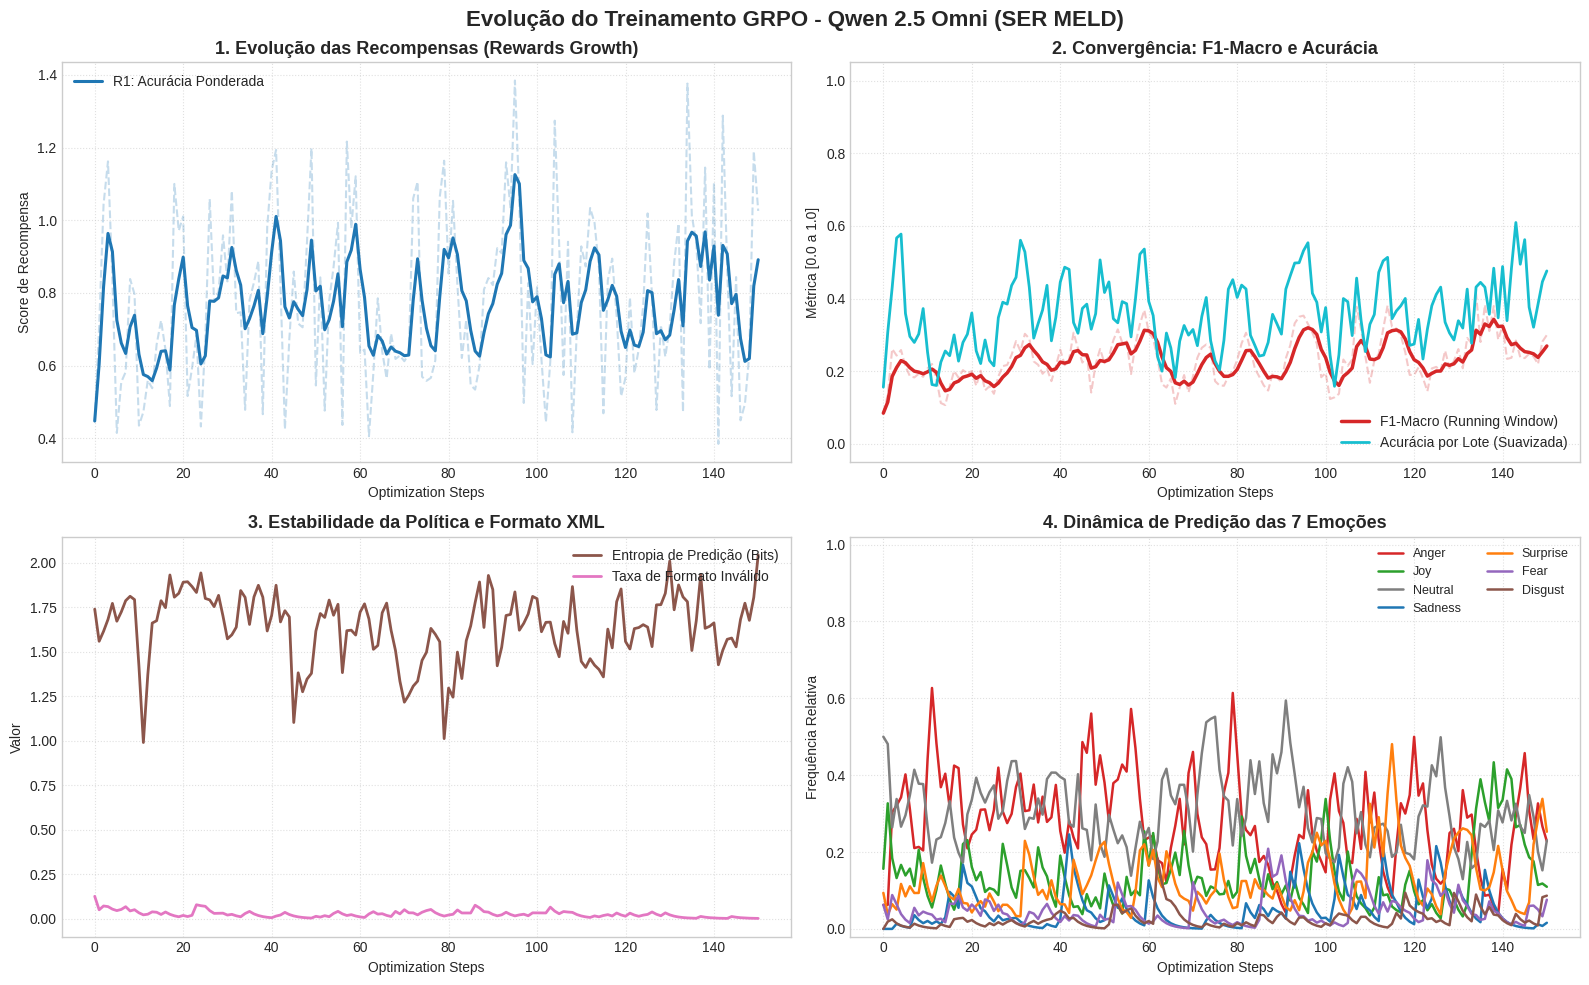

In [89]:
plot_grpo_training_curves(trainer.state.log_history)

# Avaliação Formal no Conjunto de Validação Independente (400 Amostras)

Avalia a política do modelo treinado em modo determinístico (`do_sample=False`) diretamente sobre o conjunto de validação isolado (`val_set`), gerando:
- F1-Macro, F1-Weighted e Acurácia fora do conjunto de treino.
- Classification Report detalhado para cada uma das 7 classes emocionais.
- Matriz de Confusão normalizada.
- **Rastreamento da Recompensa Acústica (R2)**: cálculo da pontuação de recompensa física e acerto de cada prompt do conjunto de validação.
- **Diagnóstico do Acoustic Inventory (Taxa de Acerto)**: quanto do inventário acústico o modelo está acertando (global e por dimensão: Pitch Height, Pitch Dynamics, Vocal Energy, Speaking Rate e Voice Quality).
- **Distribuição das Respostas do Modelo no Acoustic Inventory**: análise empírica da distribuição das opções geradas pelo modelo vs. distribuição física real (Ground Truth) em cada slot prosódico.


## Minority check

In [90]:
disgust_samples = train_set[train_set["emotion"] == "disgust"].head(5)

model.eval()
print("🔍 O QUE O MODELO RESPONDE QUANDO O ÁUDIO É DISGUST:")
for _, row in disgust_samples.iterrows():
  audio = load_audio_fast(row["audio_path"])
  prompt = [
      {"role": "system", "content": qwen_persona},
      {
          "role": "user",
          "content": [
              {"type": "audio", "audio": ""},
              {"type": "text", "text": cot_prompt},
          ],
      },
  ]
  text = processor.apply_chat_template(
      prompt, add_generation_prompt=True, tokenize=False
  )
  inputs = processor(
      text=[text], audio=[audio], sampling_rate=16000, return_tensors="pt"
  ).to(model.device)

  with torch.no_grad():
    out = model.generate(
        **inputs, max_new_tokens=256, temperature=0.7, do_sample=True, return_audio=False,
    )

  gen_text = processor.tokenizer.decode(
      out[0][inputs.input_ids.shape[1] :], skip_special_tokens=True
  )
  print(f"\n[Falante: {row['speaker']}] Verdade: {row['emotion']}")
  print(f"Geração:\n{gen_text}...")

🔍 O QUE O MODELO RESPONDE QUANDO O ÁUDIO É DISGUST:

[Falante: Chandler] Verdade: disgust
Geração:
<think>
[Acoustic Inventory]
- Pitch Height: low
- Pitch Dynamics: wide
- Vocal Energy: loud
- Speaking Rate: moderate
- Voice Quality: modal/normal

[Prosodic Reasoning]
The speaker's low pitch, wide pitch dynamics, loud vocal energy, and moderate speaking rate suggest that the speaker is experiencing a strong emotion. The combination of these cues, especially the loud vocal energy and the wide pitch dynamics, typically indicates anger or surprise. Given the context of the conversation, it seems more likely that the speaker is expressing dissatisfaction or frustration, which aligns with anger.

</think>
<answer>anger</answer>...

[Falante: Ross] Verdade: disgust
Geração:
<think>
[Acoustic Inventory]
- Pitch Height: elevated
- Pitch Dynamics: wide
- Vocal Energy: loud
- Speaking Rate: slow
- Voice Quality: harsh/creaky

[Prosodic Reasoning]
The elevated pitch, wide pitch dynamics, loud vo

## individual

In [91]:
!pip install -q opensmile

In [92]:
import os
from typing import Dict, Union
import opensmile
import pandas as pd

CUE_FEATURE_MAP: Dict[str, str] = {
    "pitch_height": "F0semitoneFrom27.5Hz_sma3nz_amean",
    "pitch_dynamics": "F0semitoneFrom27.5Hz_sma3nz_pctlrange0-2",
    "vocal_energy": "loudness_sma3_percentile50.0",
    "speaking_rate": "VoicedSegmentsPerSec",
}

VOICE_QUALITY_FEATURE_MAP: Dict[str, str] = {
    "jitter": "jitterLocal_sma3nz_amean",
    "shimmer": "shimmerLocaldB_sma3nz_amean",
    "hnr": "HNRdBACF_sma3nz_amean",
    "hammarberg": "hammarbergIndexV_sma3nz_amean",
}

# Initialize openSMILE extractor for eGeMAPSv02 functionals
smile = opensmile.Smile(
    feature_set=opensmile.FeatureSet.eGeMAPSv02,
    feature_level=opensmile.FeatureLevel.Functionals,
)


def extract_and_print_egemaps(
    audio_path_or_signal: Union[str, tuple],
    speaker_id: str = "Unknown",
    sampling_rate: int = 16000,
) -> Dict[str, float]:
    """Extracts target eGeMAPSv02 features for an audio clip and prints a structured summary.

    Args:
        audio_path_or_signal: Path to .wav file (str) OR tuple of (signal_np_array,
          sr).
        speaker_id: Optional speaker tag for logging.
        sampling_rate: Sampling rate if passing a numpy array.

    Returns:
        Dict mapping clean feature aliases to their raw float values.
    """
    if isinstance(audio_path_or_signal, str):
        if not os.path.exists(audio_path_or_signal):
            raise FileNotFoundError(
                f"Audio file not found: {audio_path_or_signal}"
            )
        df_feats: pd.DataFrame = smile.process_file(audio_path_or_signal)
    else:
        # Tuple of (np.ndarray, sample_rate)
        signal, sr = audio_path_or_signal
        df_feats: pd.DataFrame = smile.process_signal(signal, sr)

    extracted_metrics: Dict[str, float] = {}

    print(f"\n{'='*20} eGeMAPS Acoustic Extraction [{speaker_id}] {'='*20}")

    print("\n--- Core Prosodic Cues ---")
    for alias, feature_col in CUE_FEATURE_MAP.items():
        val = (
            float(df_feats[feature_col].iloc[0])
            if feature_col in df_feats.columns
            else float("nan")
        )
        extracted_metrics[alias] = val
        print(f"  {alias:<16} : {val:8.3f}  ({feature_col})")

    print("\n--- Voice Quality Features ---")
    for alias, feature_col in VOICE_QUALITY_FEATURE_MAP.items():
        val = (
            float(df_feats[feature_col].iloc[0])
            if feature_col in df_feats.columns
            else float("nan")
        )
        extracted_metrics[alias] = val
        print(f"  {alias:<16} : {val:8.3f}  ({feature_col})")

    print(f"{'='*65}\n")

    return extracted_metrics

In [93]:
sample = val_set.iloc[31]
print(sample["emotion"])
print(sample["duration"])
print(sample["audio_path"])
print(sample["speaker"])
audio_path = sample["audio_path"]

disgust
6.016
/content/MELD/preprocessed_train_splits/dia82_utt6.wav
Chandler


In [94]:
metrics = extract_and_print_egemaps(
    audio_path, speaker_id=sample["speaker"]
)


==================== eGeMAPS Acoustic Extraction [Chandler] ====================

--- Core Prosodic Cues ---
  pitch_height     :   31.454  (F0semitoneFrom27.5Hz_sma3nz_amean)
  pitch_dynamics   :    7.264  (F0semitoneFrom27.5Hz_sma3nz_pctlrange0-2)
  vocal_energy     :    0.709  (loudness_sma3_percentile50.0)
  speaking_rate    :    2.521  (VoicedSegmentsPerSec)

--- Voice Quality Features ---
  jitter           :    0.025  (jitterLocal_sma3nz_amean)
  shimmer          :    1.119  (shimmerLocaldB_sma3nz_amean)
  hnr              :    4.908  (HNRdBACF_sma3nz_amean)
  hammarberg       :   17.786  (hammarbergIndexV_sma3nz_amean)



In [95]:
import librosa
import torch
import gc

# 1. Limpeza de memória
gc.collect()
torch.cuda.empty_cache()

# 2. Carrega o áudio exatamente como no trainer
audio_array, sr = librosa.load(audio_path, sr=16000)

# 3. Chat template idêntico ao AudioGRPOTrainer (com qwen_persona e audio: "")
messages = [
    {"role": "system", "content": qwen_persona},
    {
        "role": "user",
        "content": [
            {"type": "audio", "audio": ""},
            {"type": "text", "text": cot_prompt}
        ]
    }
]
chat_prompt = processor.apply_chat_template(
    messages,
    add_generation_prompt=True,
    tokenize=False
)

# 4. Processamento multimodal (mesma assinatura do trainer)
inputs = processor(
    text=[chat_prompt],
    audio=[audio_array],
    sampling_rate=16000,
    return_tensors="pt",
    padding=True
).to(model.device)

# 5. Coloca em eval e destrava o cache em todos os submódulos
model.eval()

if hasattr(model, "gradient_checkpointing_disable"):
    model.gradient_checkpointing_disable()
if hasattr(model, "thinker") and hasattr(model.thinker, "gradient_checkpointing_disable"):
    model.thinker.gradient_checkpointing_disable()

model.config.use_cache = True
if hasattr(model.config, "thinker_config"):
    model.config.thinker_config.use_cache = True
if hasattr(model, "thinker"):
    model.thinker.config.use_cache = True

# 6. Geração com lista de tokens de paragem
im_end_id = processor.tokenizer.convert_tokens_to_ids("<|im_end|>")
eos_ids = [processor.tokenizer.eos_token_id, im_end_id]

with torch.no_grad():
    out = model.generate(
        **inputs,
        use_cache=True,
        return_audio=False,
        max_new_tokens=256,
        temperature=0.7,
        do_sample=True,
        pad_token_id=processor.tokenizer.pad_token_id,
        eos_token_id=eos_ids,
        repetition_penalty=1.15
    )

# 7. Decodificação isolando a resposta gerada
prompt_len = inputs["input_ids"].shape[1]
generated_ids = out[0][prompt_len:]
completion_text = processor.decode(generated_ids, skip_special_tokens=False)

print(f"Tokens gerados: {len(generated_ids)}")
print("--- SAÍDA GERADA ---")
print(completion_text)

Tokens gerados: 188
--- SAÍDA GERADA ---
<think>
[Acoustic Inventory]
- Pitch Height: low
- Pitch Dynamics: wide
- Vocal Energy: loud
- Speaking Rate: moderate
- Voice Quality: normal

[Prosodic Reasoning]
The speaker is likely experiencing amusement or happiness given their laughter at the end of their statement despite not directly expressing joy verbally throughout most of the segment. The use of a moderate speaking rate with noticeable pitch dynamics suggests a casual yet engaged demeanor rather than extreme excitement (which would imply higher pitched tones and faster rates) or repression (implying lower pitch, slower pace, and possibly even whispering). There’s no indication of tension or distress, ruling out fear or anger; thus, it leaves us primarily with options related to positive emotions such as amusement, which aligns well with the context provided by the laughter indicating a light-hearted moment shared among friends or acquaintances.
</think>
<answer>joy</answer><|im_end

## Val set

🔬 Avaliando política GRPO em 400 amostras (Batch Size: 20)...


Avaliando Validação:   0%|          | 0/20 [00:00<?, ?it/s]


📊 RELATÓRIO DE CLASSIFICAÇÃO NO CONJUNTO DE VALIDAÇÃO
              precision    recall  f1-score   support

       anger     0.3592    0.6271    0.4568        59
     disgust     0.7143    0.0926    0.1639        54
        fear     0.5429    0.3585    0.4318        53
         joy     0.4717    0.4310    0.4505        58
     neutral     0.3404    0.5333    0.4156        60
     sadness     0.7692    0.3448    0.4762        58
    surprise     0.4810    0.6552    0.5547        58

   micro avg     0.4433    0.4400    0.4417       400
   macro avg     0.5255    0.4347    0.4214       400
weighted avg     0.5221    0.4400    0.4239       400

Accuracy: 0.4400
Invalid prediction rate: 0.75%


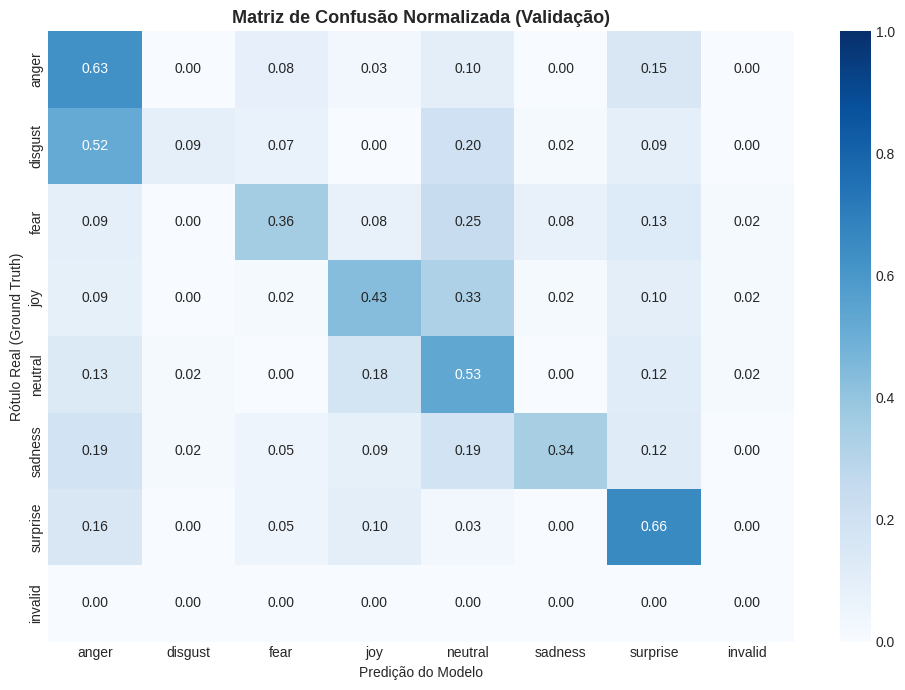


🎙️ DIAGNÓSTICO DO INVENTÁRIO ACÚSTICO & RECOMPENSAS GRPO (ZERO-MEAN)
Total de Amostras Avaliadas       : 400
Recompensa Composta R_unified     : 0.9482
Recompensa Emoção R1 (Zero-Mean)  : +0.3490 (Baseline Chute Cego = 0.0000)
Recompensa Acústica R2 [0.0, 1.0] : 0.5597 ± 0.1579 (Mediana: 0.5532 | Chute Cego = 0.5000)
Gate Físico / Acerto Exato (R2)   : 40.60%
Recompensa de Formato R3 [0.0, 1.0]: 0.9985
Inventários 100% Perfeitos (5/5)  : 1.75%
Formato Válido (5/5 Slots)        : 100.00%

---------------------------------------------------------------------------
🎯 QUANTO DO INVENTÁRIO ACÚSTICO O MODELO ESTÁ ACERTANDO POR DIMENSÃO:
---------------------------------------------------------------------------
Dimensão Acústica  | Acerto Exato (%) | Score R2 [0-1] | Amostras GT | Omissões 
---------------------------------------------------------------------------
Pitch Height       |          47.00% |         0.6063 | 400         |    0.00%
Pitch Dynamics     |          28.25% |         0

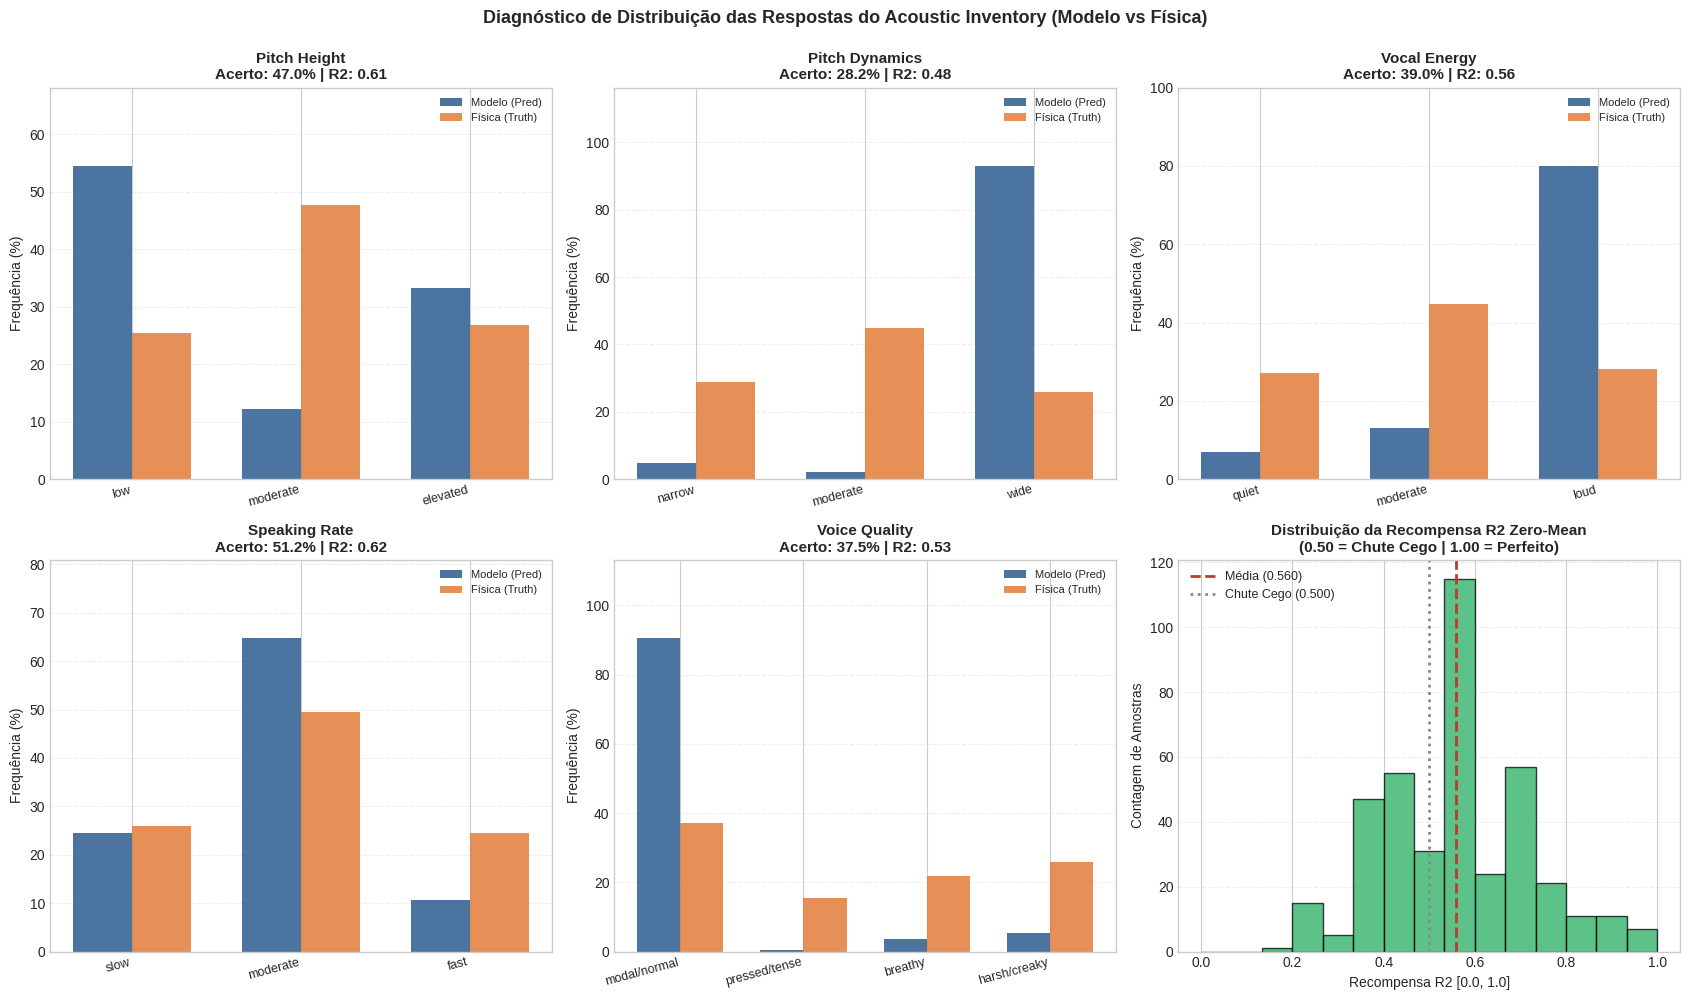

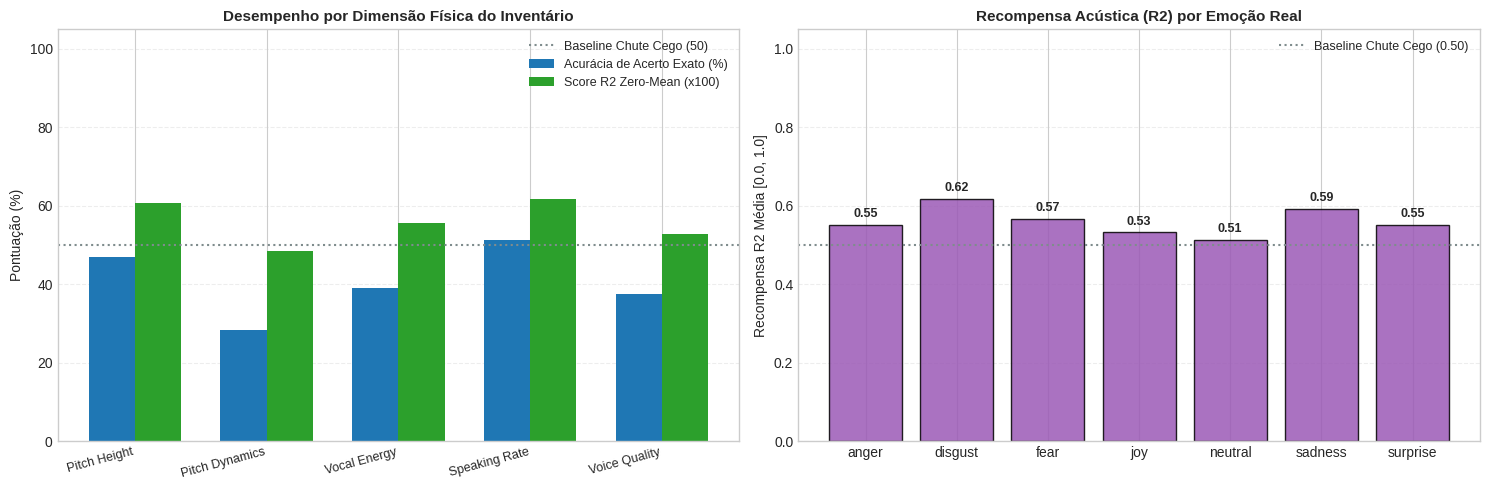

In [99]:
# ==============================================================================
# Avaliação do Modelo no Conjunto de Validação (val_set) em Lotes (Batches)
# + Rastreamento de Recompensas R1, R2 (Zero-Mean Esperança), R3 e R_unified
# ==============================================================================
from typing import Any, Dict, List, Optional, Tuple
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
)
import torch
from tqdm.auto import tqdm

VALID_EMOTIONS_LIST = [
    "anger",
    "disgust",
    "fear",
    "joy",
    "neutral",
    "sadness",
    "surprise",
]

INVENTORY_DIMENSIONS: Dict[str, Dict[str, Any]] = {
    "pitch_height": {
        "title": "Pitch Height",
        "options": ["low", "moderate", "elevated"],
        "tier_to_prompt": {"low": "low", "moderate": "moderate", "high": "elevated"},
    },
    "pitch_dynamics": {
        "title": "Pitch Dynamics",
        "options": ["narrow", "moderate", "wide"],
        "tier_to_prompt": {"low": "narrow", "moderate": "moderate", "high": "wide"},
    },
    "vocal_energy": {
        "title": "Vocal Energy",
        "options": ["quiet", "moderate", "loud"],
        "tier_to_prompt": {"low": "quiet", "moderate": "moderate", "high": "loud"},
    },
    "speaking_rate": {
        "title": "Speaking Rate",
        "options": ["slow", "moderate", "fast"],
        "tier_to_prompt": {"low": "slow", "moderate": "moderate", "high": "fast"},
    },
    "voice_quality": {
        "title": "Voice Quality",
        "options": ["modal/normal", "pressed/tense", "breathy", "harsh/creaky"],
        "tier_to_prompt": None,
    },
}


def evaluate_single_prompt_acoustics(
    completion: str,
    audio_path: str,
    speaker: str,
    row_data: Optional[Dict[str, Any]] = None,
    quantiles_dict: Optional[Dict[str, Any]] = None,
    audio_lookup: Optional[Dict[str, Any]] = None,
    priors_dict: Optional[Dict[str, Dict[str, float]]] = None,
) -> Dict[str, Any]:
    """Calcula a recompensa acústica R2 (Zero-Mean Esperança + Transformação Linear Afim),
    o gate causal não-ponderado (exact_match_ratio) e o desempenho individual de cada dimensão.
    """
    parsed = parse_completion(completion)
    parsed_inv = parsed.get("inventory", {})

    q_dict = quantiles_dict if quantiles_dict is not None else globals().get("SPEAKER_ACOUSTIC_QUANTILES", {})
    lookup = audio_lookup if audio_lookup is not None else globals().get("AUDIO_ACOUSTIC_LOOKUP", {})
    p_dict = priors_dict if priors_dict is not None else globals().get("ACOUSTIC_CUE_PRIORS", {})

    row = row_data or {}
    spk = speaker if speaker else row.get("speaker", lookup.get(audio_path, {}).get("speaker", "__GLOBAL__"))
    spk_q = q_dict.get(spk, q_dict.get("__GLOBAL__", {}))

    audio_feat_cache = lookup.get(audio_path, {})

    cue_raw_scores: Dict[str, float] = {}
    cue_norm_scores: Dict[str, float] = {}
    cue_matches: Dict[str, bool] = {}
    cue_preds: Dict[str, Optional[str]] = {}
    cue_truths: Dict[str, Optional[str]] = {}

    achieved_scores: List[float] = []
    max_possible_scores: List[float] = []
    unweighted_hits = 0.0
    total_cues = 0

    # 1. Avaliação dos 4 cues físicos contínuos
    for cue_name in ["pitch_height", "pitch_dynamics", "vocal_energy", "speaking_rate"]:
        feat_col = CUE_FEATURE_MAP.get(cue_name)
        val = (
            row.get(feat_col)
            if (feat_col in row and not pd.isna(row.get(feat_col)))
            else audio_feat_cache.get(feat_col)
        )

        truth_tier = None
        truth_prompt_opt = None
        if val is not None and not pd.isna(val) and cue_name in spk_q:
            val_f = float(val)
            # Filtra zeros / falhas de extração do openSMILE
            if not (val_f == 0.0 or (feat_col in STRICTLY_POSITIVE_CUES and val_f <= 0.0)):
                q25 = spk_q[cue_name]["q25"]
                q75 = spk_q[cue_name]["q75"]
                if val_f <= q25:
                    truth_tier = "low"
                elif val_f <= q75:
                    truth_tier = "moderate"
                else:
                    truth_tier = "high"
                truth_prompt_opt = INVENTORY_DIMENSIONS[cue_name]["tier_to_prompt"].get(truth_tier)

        raw_pred = parsed_inv.get(cue_name)
        pred_tier = None
        pred_prompt_opt = None
        if raw_pred:
            raw_clean = str(raw_pred).lower().strip()
            pred_tier = PRED_TIER_MAP.get(cue_name, {}).get(raw_clean)
            if pred_tier == "low":
                pred_prompt_opt = INVENTORY_DIMENSIONS[cue_name]["options"][0]
            elif pred_tier == "moderate":
                pred_prompt_opt = INVENTORY_DIMENSIONS[cue_name]["options"][1]
            elif pred_tier == "high":
                pred_prompt_opt = INVENTORY_DIMENSIONS[cue_name]["options"][2]
            else:
                pred_prompt_opt = raw_clean

        cue_preds[cue_name] = pred_prompt_opt
        cue_truths[cue_name] = truth_prompt_opt

        if truth_tier is not None:
            sc, mx, hit = score_cue_zero_mean(truth_tier, pred_tier, cue_name, priors_dict=p_dict)
            # Fix 2: Score individual normalizado linearmente com denominador constante R2_NORM_SCALE (0.50 = chute cego)
            norm_sc = max(0.0, min(1.0, 0.50 + (sc / R2_NORM_SCALE)))
            cue_raw_scores[cue_name] = sc
            cue_norm_scores[cue_name] = float(norm_sc)
            cue_matches[cue_name] = bool(hit == 1.0)

            achieved_scores.append(sc)
            max_possible_scores.append(mx)
            unweighted_hits += hit
            total_cues += 1
        else:
            cue_matches[cue_name] = False

    # 2. Avaliação de Voice Quality (Jitter, Shimmer, HNR, Hammarberg)
    vq_vals = {}
    for sub_cue, col_name in VOICE_QUALITY_FEATURE_MAP.items():
        v = (
            row.get(col_name)
            if (col_name in row and not pd.isna(row.get(col_name)))
            else audio_feat_cache.get(col_name)
        )
        if v is not None and not pd.isna(v):
            v_f = float(v)
            if not (v_f == 0.0 or (col_name in STRICTLY_POSITIVE_CUES and v_f <= 0.0)):
                vq_vals[sub_cue] = v_f

    truth_vq = None
    if len(vq_vals) == len(VOICE_QUALITY_FEATURE_MAP) and all(k in spk_q for k in vq_vals):
        truth_vq = determine_voice_quality_ground_truth(
            jitter_val=vq_vals["jitter"],
            shimmer_val=vq_vals["shimmer"],
            hnr_val=vq_vals["hnr"],
            hammarberg_val=vq_vals["hammarberg"],
            quantiles=spk_q,
        )

    raw_vq_pred = parsed_inv.get("voice_quality")
    pred_vq = None
    if raw_vq_pred:
        raw_vq_clean = str(raw_vq_pred).lower().strip()
        pred_vq = VOICE_QUALITY_CHOICES.get(raw_vq_clean, raw_vq_clean)

    cue_preds["voice_quality"] = pred_vq
    cue_truths["voice_quality"] = truth_vq

    if truth_vq is not None:
        sc, mx, hit = score_cue_zero_mean(truth_vq, pred_vq, "voice_quality", priors_dict=p_dict)
        norm_sc = max(0.0, min(1.0, 0.50 + (sc / R2_NORM_SCALE)))
        cue_raw_scores["voice_quality"] = sc
        cue_norm_scores["voice_quality"] = float(norm_sc)
        cue_matches["voice_quality"] = bool(hit == 1.0)

        achieved_scores.append(sc)
        max_possible_scores.append(mx)
        unweighted_hits += hit
        total_cues += 1
    else:
        cue_matches["voice_quality"] = False

    # 3. Cálculo de R2 Normalizado (Transformação Linear Afim) e Gate Não-Ponderado
    if total_cues > 0:
        sum_achieved = sum(achieved_scores)
        r2_reward = float(max(0.0, min(1.0, 0.50 + (sum_achieved / (R2_NORM_SCALE * total_cues)))))
        exact_match_ratio = float(unweighted_hits / total_cues)
    else:
        r2_reward = 0.0
        exact_match_ratio = 0.0

    return {
        "r2_acoustic_reward": r2_reward,
        "acoustic_exact_match_ratio": exact_match_ratio,
        "cue_scores": cue_norm_scores,
        "cue_raw_scores": cue_raw_scores,
        "cue_matches": cue_matches,
        "cue_preds": cue_preds,
        "cue_truths": cue_truths,
    }


def analyze_acoustic_inventory_performance(
    results_df: pd.DataFrame,
    plot: bool = True,
) -> Dict[str, Any]:
    """Diagnóstico estatístico das Recompensas (R1, R2 Zero-Mean, R3, R_unified) e do Inventário Acústico."""
    total_samples = len(results_df)
    mean_r2 = float(results_df["r2_acoustic_reward"].mean()) if "r2_acoustic_reward" in results_df else 0.0
    std_r2 = float(results_df["r2_acoustic_reward"].std()) if "r2_acoustic_reward" in results_df else 0.0
    median_r2 = float(results_df["r2_acoustic_reward"].median()) if "r2_acoustic_reward" in results_df else 0.0
    mean_exact = float(results_df["acoustic_exact_match_ratio"].mean()) if "acoustic_exact_match_ratio" in results_df else 0.0
    perfect_inv = float((results_df["acoustic_exact_match_ratio"] == 1.0).mean()) if "acoustic_exact_match_ratio" in results_df else 0.0
    valid_format = float((results_df["valid_slots_count"] == 5).mean()) if "valid_slots_count" in results_df else 0.0

    mean_r1 = float(results_df["r1_reward"].mean()) if "r1_reward" in results_df else 0.0
    mean_r3 = float(results_df["r3_format_reward"].mean()) if "r3_format_reward" in results_df else 0.0
    mean_runified = float(results_df["r_unified_reward"].mean()) if "r_unified_reward" in results_df else 0.0

    print("\n" + "=" * 75)
    print("🎙️ DIAGNÓSTICO DO INVENTÁRIO ACÚSTICO & RECOMPENSAS GRPO (ZERO-MEAN)")
    print("=" * 75)
    print(f"Total de Amostras Avaliadas       : {total_samples}")
    print(f"Recompensa Composta R_unified     : {mean_runified:.4f}")
    print(f"Recompensa Emoção R1 (Zero-Mean)  : {mean_r1:+.4f} (Baseline Chute Cego = 0.0000)")
    print(f"Recompensa Acústica R2 [0.0, 1.0] : {mean_r2:.4f} ± {std_r2:.4f} (Mediana: {median_r2:.4f} | Chute Cego = 0.5000)")
    print(f"Gate Físico / Acerto Exato (R2)   : {mean_exact:.2%}")
    print(f"Recompensa de Formato R3 [0.0, 1.0]: {mean_r3:.4f}")
    print(f"Inventários 100% Perfeitos (5/5)  : {perfect_inv:.2%}")
    print(f"Formato Válido (5/5 Slots)        : {valid_format:.2%}")

    # 1. Tabela de Desempenho por Dimensão Acústica
    print("\n" + "-" * 75)
    print("🎯 QUANTO DO INVENTÁRIO ACÚSTICO O MODELO ESTÁ ACERTANDO POR DIMENSÃO:")
    print("-" * 75)
    print(f"{'Dimensão Acústica':<18} | {'Acerto Exato (%)':<16} | {'Score R2 [0-1]':<14} | {'Amostras GT':<11} | {'Omissões':<9}")
    print("-" * 75)

    dim_metrics = {}
    for cue, info in INVENTORY_DIMENSIONS.items():
        truth_col = f"truth_{cue}"
        pred_col = f"pred_{cue}"
        match_col = f"match_{cue}"
        score_col = f"score_{cue}"

        valid_mask = results_df[truth_col].notna() if truth_col in results_df else pd.Series(False, index=results_df.index)
        n_valid = int(valid_mask.sum())

        if n_valid > 0:
            acc = float(results_df.loc[valid_mask, match_col].mean())
            avg_score = float(results_df.loc[valid_mask, score_col].mean())
        else:
            acc = 0.0
            avg_score = 0.0

        n_missing = int(results_df[pred_col].isna().sum()) if pred_col in results_df else total_samples
        missing_pct = n_missing / max(total_samples, 1)

        dim_metrics[cue] = {
            "accuracy": acc,
            "mean_score": avg_score,
            "evaluated_samples": n_valid,
            "missing_count": n_missing,
        }

        print(f"{info['title']:<18} | {acc * 100:14.2f}% | {avg_score:14.4f} | {n_valid:<11} | {missing_pct * 100:7.2f}%")

    print("-" * 75)

    # 2. Distribuição das Respostas do Modelo vs Ground Truth Físico
    print("\n" + "-" * 75)
    print("📊 DISTRIBUIÇÃO DAS RESPOSTAS GERADAS PELO MODELO VS GROUND TRUTH FÍSICO:")
    print("-" * 75)

    dist_comparison = {}
    for cue, info in INVENTORY_DIMENSIONS.items():
        title = info["title"]
        opts = info["options"]
        pred_col = f"pred_{cue}"
        truth_col = f"truth_{cue}"

        pred_counts = results_df[pred_col].value_counts() if pred_col in results_df else pd.Series(dtype=int)
        truth_counts = results_df[truth_col].value_counts() if truth_col in results_df else pd.Series(dtype=int)

        print(f"\n🔹 {title}:")
        dist_comparison[cue] = {}

        for opt in opts:
            pc = int(pred_counts.get(opt, 0))
            tc = int(truth_counts.get(opt, 0))
            p_pct = (pc / max(total_samples, 1)) * 100.0
            t_pct = (tc / max(truth_counts.sum(), 1)) * 100.0
            diff = p_pct - t_pct
            dist_comparison[cue][opt] = {
                "model_pct": p_pct,
                "truth_pct": t_pct,
                "diff_pct": diff,
            }
            print(f"   • {opt:<14} : Modelo: {p_pct:5.1f}% ({pc:3d}) | Ground Truth: {t_pct:5.1f}% ({tc:3d}) | Viés: {diff:+6.1f}%")

        unparsed = total_samples - sum(int(pred_counts.get(opt, 0)) for opt in opts)
        if unparsed > 0:
            print(f"   • <não-parseado> : Modelo: {(unparsed / max(total_samples, 1)) * 100.0:5.1f}% ({unparsed:3d})")

    # 3. Recompensa Acústica R2 por Emoção Real (Ground Truth)
    if "truth" in results_df.columns and "r2_acoustic_reward" in results_df.columns:
        print("\n" + "-" * 75)
        print("🎭 DESEMPENHO ACÚSTICO (R2) E EMOCIONAL POR CLASSE REAL (GROUND TRUTH):")
        print("-" * 75)
        emo_group = results_df.groupby("truth").agg(
            r2_mean=("r2_acoustic_reward", "mean"),
            exact_match=("acoustic_exact_match_ratio", "mean"),
            acc_emotion=("pred", lambda x: np.mean(x == results_df.loc[x.index, "truth"])),
            count=("truth", "count"),
        ).sort_values("r2_mean", ascending=False)

        for emo, row in emo_group.iterrows():
            print(
                f"   • {emo:<10} (N={int(row['count']):3d}): "
                f"R2={row['r2_mean']:.3f} | Gate (Acerto Físico)={row['exact_match']:.1%} | Acc Emoção={row['acc_emotion']:.1%}"
            )

    # 4. Visualizações Gráficas
    if plot:
        fig, axes = plt.subplots(2, 3, figsize=(17, 10))
        axes = axes.flatten()

        for idx, (cue, info) in enumerate(INVENTORY_DIMENSIONS.items()):
            ax = axes[idx]
            opts = info["options"]
            pred_col = f"pred_{cue}"
            truth_col = f"truth_{cue}"

            pred_counts = results_df[pred_col].value_counts() if pred_col in results_df else pd.Series(dtype=int)
            truth_counts = results_df[truth_col].value_counts() if truth_col in results_df else pd.Series(dtype=int)

            pred_vals = [(pred_counts.get(opt, 0) / max(total_samples, 1)) * 100.0 for opt in opts]
            truth_vals = [(truth_counts.get(opt, 0) / max(truth_counts.sum(), 1)) * 100.0 for opt in opts]

            x = np.arange(len(opts))
            width = 0.35

            ax.bar(x - width / 2, pred_vals, width, label="Modelo (Pred)", color="#2b5c8f", alpha=0.85)
            ax.bar(x + width / 2, truth_vals, width, label="Física (Truth)", color="#e27c38", alpha=0.85)

            acc_cue = dim_metrics[cue]["accuracy"] * 100.0
            score_cue = dim_metrics[cue]["mean_score"]
            ax.set_title(f"{info['title']}\nAcerto: {acc_cue:.1f}% | R2: {score_cue:.2f}", fontsize=11, fontweight="bold")
            ax.set_xticks(x)
            ax.set_xticklabels(opts, rotation=15, ha="right", fontsize=9)
            ax.set_ylabel("Frequência (%)", fontsize=10)
            ax.set_ylim(0, max(max(pred_vals + [10]), max(truth_vals + [10])) * 1.25)
            ax.grid(axis="y", linestyle="--", alpha=0.35)
            ax.legend(fontsize=8, loc="upper right")

        # 6º Subplot: Histograma e Distribuição da Recompensa Acústica R2
        ax_r2 = axes[5]
        r2_vals = results_df["r2_acoustic_reward"]
        ax_r2.hist(r2_vals, bins=15, range=(0.0, 1.0), color="#27ae60", edgecolor="black", alpha=0.75)
        ax_r2.axvline(mean_r2, color="#c0392b", linestyle="--", linewidth=2, label=f"Média ({mean_r2:.3f})")
        ax_r2.axvline(0.50, color="#7f8c8d", linestyle=":", linewidth=2, label="Chute Cego (0.500)")
        ax_r2.set_title("Distribuição da Recompensa R2 Zero-Mean\n(0.50 = Chute Cego | 1.00 = Perfeito)", fontsize=11, fontweight="bold")
        ax_r2.set_xlabel("Recompensa R2 [0.0, 1.0]", fontsize=10)
        ax_r2.set_ylabel("Contagem de Amostras", fontsize=10)
        ax_r2.grid(axis="y", linestyle="--", alpha=0.35)
        ax_r2.legend(fontsize=9, loc="upper left")

        plt.suptitle("Diagnóstico de Distribuição das Respostas do Acoustic Inventory (Modelo vs Física)", fontsize=13, fontweight="bold", y=0.995)
        plt.tight_layout()
        plt.show()

        fig2, (ax_d, ax_e) = plt.subplots(1, 2, figsize=(15, 5))

        titles = [info["title"] for info in INVENTORY_DIMENSIONS.values()]
        accs = [dim_metrics[c]["accuracy"] * 100.0 for c in INVENTORY_DIMENSIONS]
        scs = [dim_metrics[c]["mean_score"] * 100.0 for c in INVENTORY_DIMENSIONS]

        x_d = np.arange(len(titles))
        w = 0.35
        ax_d.bar(x_d - w / 2, accs, w, label="Acurácia de Acerto Exato (%)", color="#1f77b4")
        ax_d.bar(x_d + w / 2, scs, w, label="Score R2 Zero-Mean (x100)", color="#2ca02c")
        ax_d.axhline(50.0, color="#7f8c8d", linestyle=":", linewidth=1.5, label="Baseline Chute Cego (50)")
        ax_d.set_xticks(x_d)
        ax_d.set_xticklabels(titles, rotation=15, ha="right", fontsize=9)
        ax_d.set_ylabel("Pontuação (%)", fontsize=10)
        ax_d.set_title("Desempenho por Dimensão Física do Inventário", fontsize=11, fontweight="bold")
        ax_d.set_ylim(0, 105)
        ax_d.grid(axis="y", linestyle="--", alpha=0.35)
        ax_d.legend(loc="upper right", fontsize=9)

        if "truth" in results_df.columns:
            emo_means = results_df.groupby("truth")["r2_acoustic_reward"].mean().reindex(VALID_EMOTIONS_LIST).dropna()
            bars = ax_e.bar(emo_means.index, emo_means.values, color="#9b59b6", alpha=0.85, edgecolor="black")
            ax_e.axhline(0.50, color="#7f8c8d", linestyle=":", linewidth=1.5, label="Baseline Chute Cego (0.50)")
            ax_e.set_ylabel("Recompensa R2 Média [0.0, 1.0]", fontsize=10)
            ax_e.set_title("Recompensa Acústica (R2) por Emoção Real", fontsize=11, fontweight="bold")
            ax_e.set_ylim(0, 1.05)
            ax_e.grid(axis="y", linestyle="--", alpha=0.35)
            ax_e.legend(loc="upper right", fontsize=9)
            for bar, val in zip(bars, emo_means.values):
                ax_e.text(bar.get_x() + bar.get_width() / 2, val + 0.02, f"{val:.2f}", ha="center", fontsize=9, fontweight="bold")

        plt.tight_layout()
        plt.show()

    return {
        "mean_r_unified": mean_runified,
        "mean_r1": mean_r1,
        "mean_r2": mean_r2,
        "std_r2": std_r2,
        "median_r2": median_r2,
        "mean_r3": mean_r3,
        "mean_exact_match_ratio": mean_exact,
        "perfect_inventory_rate": perfect_inv,
        "valid_format_rate": valid_format,
        "dimensions": dim_metrics,
        "distributions": dist_comparison,
    }


def evaluate_grpo_validation(
    model,
    processor,
    val_df: pd.DataFrame,
    cot_prompt: str = cot_prompt,
    batch_size: int = 4,
    max_samples: Optional[int] = None,
    device: str = "cuda",
    run_acoustic_analysis: bool = True,
    plot_acoustics: bool = True,
) -> pd.DataFrame:
    """Executa avaliação determinística em lote no conjunto de validação com rastreamento de R1, R2 (Zero-Mean), R3 e R_unified."""
    eval_df = val_df.copy()

    if max_samples is not None and 0 < max_samples < len(eval_df):
        eval_df = eval_df.sample(n=max_samples, random_state=42).reset_index(drop=True)

    total_samples = len(eval_df)
    print(f"🔬 Avaliando política GRPO em {total_samples} amostras (Batch Size: {batch_size})...")

    # 1. Configura lookup acústico, quantis e priors calibrados (Zero-Mean)
    active_audio_lookup = dict(AUDIO_ACOUSTIC_LOOKUP) if "AUDIO_ACOUSTIC_LOOKUP" in globals() else {}
    if "audio_path" in eval_df.columns:
        val_feat_cols = [c for c in list(ALL_ACOUSTIC_FEATURES.values()) + ["speaker"] if c in eval_df.columns]
        val_lookup = eval_df.set_index("audio_path")[val_feat_cols].to_dict(orient="index")
        active_audio_lookup.update(val_lookup)

    ref_df = (
        grpo_train_set if "grpo_train_set" in globals()
        else (train_set if "train_set" in globals()
              else (raw_train_set if "raw_train_set" in globals() else None))
    )

    active_quantiles = SPEAKER_ACOUSTIC_QUANTILES if "SPEAKER_ACOUSTIC_QUANTILES" in globals() and SPEAKER_ACOUSTIC_QUANTILES else {}
    if not active_quantiles and ref_df is not None:
        active_quantiles = compute_top_speaker_acoustic_quantiles(ref_df, top_n=6, filter_zeroes=True)

    active_priors = ACOUSTIC_CUE_PRIORS if "ACOUSTIC_CUE_PRIORS" in globals() and ACOUSTIC_CUE_PRIORS else {}
    if not active_priors and ref_df is not None and active_quantiles:
        active_priors = compute_acoustic_cue_priors(ref_df, active_quantiles)

    model.eval()

    orig_padding_side = processor.tokenizer.padding_side
    processor.tokenizer.padding_side = "left"

    predictions = []
    ground_truths = []
    records = []

    try:
        for start_idx in tqdm(range(0, total_samples, batch_size), desc="Avaliando Validação"):
            batch_slice = eval_df.iloc[start_idx : start_idx + batch_size]

            batch_audio_paths = batch_slice["audio_path"].tolist()
            batch_targets = [
                LABEL_SYNONYMS.get(str(emo).lower().strip(), str(emo).lower().strip())
                for emo in batch_slice["emotion"]
            ]
            batch_speakers = (
                batch_slice["speaker"].tolist()
                if "speaker" in batch_slice.columns
                else [""] * len(batch_slice)
            )

            batch_raw_audios = [load_audio_fast(ap) for ap in batch_audio_paths]

            batch_formatted_prompts = []
            for ap in batch_audio_paths:
                messages = [
                    {"role": "system", "content": [{"type": "text", "text": qwen_persona}]},
                    {"role": "user", "content": [{"type": "audio", "audio": ap}, {"type": "text", "text": cot_prompt}]},
                ]
                batch_formatted_prompts.append(
                    processor.apply_chat_template(messages, add_generation_prompt=True, tokenize=False)
                )

            inputs = processor(
                text=batch_formatted_prompts,
                audio=batch_raw_audios,
                sampling_rate=16000,
                return_tensors="pt",
                padding=True,
            ).to(device)

            prompt_len = inputs["input_ids"].shape[1]

            with torch.no_grad():
                gen_ids = model.generate(
                    **inputs,
                    use_cache=True,
                    return_audio=False,
                    max_new_tokens=512,
                    do_sample=False,
                    pad_token_id=processor.tokenizer.pad_token_id,
                    eos_token_id=[
                        processor.tokenizer.eos_token_id,
                        processor.tokenizer.convert_tokens_to_ids("<|im_end|>"),
                    ],
                )

            completion_ids = gen_ids[:, prompt_len:]
            batch_completions = processor.tokenizer.batch_decode(completion_ids, skip_special_tokens=False)

            # Calcula R1 e R3 para o lote usando as funções oficiais de treino
            batch_parsed = [parse_completion(c) for c in batch_completions]
            batch_r1 = reward_label_accuracy_weighted(
                batch_formatted_prompts,
                batch_completions,
                label=batch_targets,
                parsed_completions=batch_parsed,
            )
            batch_r3 = [compute_format_reward_from_parsed(p) for p in batch_parsed]

            for idx_in_batch, (audio_p, spk, target, completion, parsed, r1_val, r3_val) in enumerate(
                zip(batch_audio_paths, batch_speakers, batch_targets, batch_completions, batch_parsed, batch_r1, batch_r3)
            ):
                is_valid_emotion = parsed["is_valid_emotion"]
                pred_emo = parsed["answer_norm"] if is_valid_emotion else "invalid"

                predictions.append(pred_emo)
                ground_truths.append(target)

                # Avaliação da recompensa acústica e inventário por prompt com priors Zero-Mean
                row_slice = batch_slice.iloc[idx_in_batch].to_dict()
                acoustics = evaluate_single_prompt_acoustics(
                    completion=completion,
                    audio_path=audio_p,
                    speaker=spk,
                    row_data=row_slice,
                    quantiles_dict=active_quantiles,
                    audio_lookup=active_audio_lookup,
                    priors_dict=active_priors,
                )

                r2_val = acoustics["r2_acoustic_reward"]
                r2_gate_val = acoustics["acoustic_exact_match_ratio"]

                # Cálculo do R_unified idêntico ao treino (Fix 3: Gate Causal Zero-Mean em R2)
                blind_gate_expectation = 0.15 + (1.0 - 0.15) * 0.50
                if r1_val > 0.0:
                    causal_gate = 0.15 + (1.0 - 0.15) * r2_val
                    gated_r1 = r1_val * causal_gate
                elif is_valid_emotion:
                    gated_r1 = r1_val * blind_gate_expectation
                else:
                    gated_r1 = r1_val
                r_unified_val = float(1.5 * gated_r1 + 1.0 * r2_val + 0.2 * r3_val)

                rec = {
                    "audio_path": audio_p,
                    "speaker": spk,
                    "truth": target,
                    "pred": pred_emo,
                    "valid_emotion": is_valid_emotion,
                    "r_unified_reward": r_unified_val,
                    "r1_reward": r1_val,
                    "r2_acoustic_reward": r2_val,
                    "acoustic_exact_match_ratio": r2_gate_val,
                    "r3_format_reward": r3_val,
                    "valid_slots_count": parsed["valid_slots_count"],
                }
                for cue in INVENTORY_DIMENSIONS:
                    rec[f"pred_{cue}"] = acoustics["cue_preds"].get(cue)
                    rec[f"truth_{cue}"] = acoustics["cue_truths"].get(cue)
                    rec[f"score_{cue}"] = acoustics["cue_scores"].get(cue, 0.0)
                    rec[f"match_{cue}"] = acoustics["cue_matches"].get(cue, False)

                rec["completion"] = completion
                records.append(rec)

            del inputs, gen_ids, completion_ids, batch_raw_audios
            torch.cuda.empty_cache()

    finally:
        processor.tokenizer.padding_side = orig_padding_side

    # Relatório de Classificação Emocional
    print("\n" + "=" * 75)
    print("📊 RELATÓRIO DE CLASSIFICAÇÃO NO CONJUNTO DE VALIDAÇÃO")
    print("=" * 75)

    print(
        classification_report(
            ground_truths,
            predictions,
            labels=VALID_EMOTIONS_LIST,
            zero_division=0,
            digits=4,
        )
    )

    accuracy = accuracy_score(ground_truths, predictions)
    invalid_rate = np.mean(np.array(predictions, dtype=object) == "invalid")

    print(f"Accuracy: {accuracy:.4f}")
    print(f"Invalid prediction rate: {invalid_rate:.2%}")

    # Matriz de Confusão
    cm_labels = VALID_EMOTIONS_LIST + ["invalid"]
    cm = confusion_matrix(ground_truths, predictions, labels=cm_labels)
    row_sums = cm.sum(axis=1, keepdims=True)
    cm_norm = np.divide(
        cm.astype(float),
        row_sums,
        out=np.zeros_like(cm, dtype=float),
        where=row_sums != 0,
    )

    plt.figure(figsize=(10, 7))
    sns.heatmap(
        cm_norm,
        annot=True,
        fmt=".2f",
        cmap="Blues",
        xticklabels=cm_labels,
        yticklabels=cm_labels,
        vmin=0,
        vmax=1,
    )
    plt.title("Matriz de Confusão Normalizada (Validação)", fontsize=13, fontweight="bold")
    plt.xlabel("Predição do Modelo")
    plt.ylabel("Rótulo Real (Ground Truth)")
    plt.tight_layout()
    plt.show()

    results_df = pd.DataFrame(records)

    if run_acoustic_analysis:
        analyze_acoustic_inventory_performance(results_df, plot=plot_acoustics)

    return results_df


val_results_df = evaluate_grpo_validation(model, processor, val_set, batch_size=20)

# Save Adapter

In [ ]:
import os
from google.colab import runtime

# 1. Definir o diretório final no Google Drive
FINAL_ADAPTER_DIR = "/content/drive/MyDrive/SER_DPO/MELD/qwen_ser_grpo_v5"
os.makedirs(FINAL_ADAPTER_DIR, exist_ok=True)

# 2. Desembalar o modelo e salvar apenas os pesos do LoRA
print("💾 Salvando adaptador LoRA e processador...")
unwrapped_model = trainer.accelerator.unwrap_model(trainer.model)

# Salva apenas o adapter_model.safetensors e adapter_config.json (~50-150 MB)
unwrapped_model.save_pretrained(FINAL_ADAPTER_DIR)
processor.save_pretrained(FINAL_ADAPTER_DIR)

# 3. Forçar o flush do buffer do Linux para o Google Drive
# Evita arquivos corrompidos se a máquina for desligada antes do Drive sincronizar
os.sync()
print(f" Adaptador gravado com sucesso em: {FINAL_ADAPTER_DIR}")

💾 Salvando adaptador LoRA e processador...
 Adaptador gravado com sucesso em: /content/drive/MyDrive/SER_DPO/MELD/qwen_ser_grpo_v4


In [ ]:
import time
time.sleep(10)
runtime.unassign()